# Bloomberg multi-asset portfolio optimisation

Research notebook from a seven-member FMAT3888 team project, University of Sydney (2026).
The workflow covers data quality, parameter estimation, strategic allocation, utility,
bootstrap uncertainty, historical SAA/TAA tests, and a three-period dynamic extension.

**Contribution:** xihu0859 contributed Python implementation and evaluation for tactical
allocation (Q6), including sensitivity and trading-cost analysis, and the numerical
validation, matched strategy comparisons, report text and presentation for Extension B(d)-(e).
The complete notebook includes collaborators' work. It is not presented as a sole-authored project.

**Data:** supply an authorised workbook as described in `../data/README.md`. The original
coursework download link and raw-data previews have been removed. No prices or return
series are distributed. Plot outputs are retained as a readable record of the original run;
execution counts and raw tabular outputs are cleared. Running all cells requires the data.
Full Monte Carlo and bootstrap experiments can take several minutes or longer.


# Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import os
from IPython.display import display

# Supply your own authorised Bloomberg workbook. No download is performed.
project_root = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "data" / "README.md").exists()), Path.cwd()
)
file_path = os.environ.get(
    "BLOOMBERG_DATA_PATH", str(project_root / "data" / "bloomberg.xlsx")
)
if not Path(file_path).is_file():
    raise FileNotFoundError(
        "Bloomberg workbook not distributed. See data/README.md, then place an "
        "authorised workbook at data/bloomberg.xlsx or set BLOOMBERG_DATA_PATH."
    )

xls = pd.ExcelFile(file_path)
print("Sheets:", xls.sheet_names)

def read_sheet(sheet_name):
    # Bloomberg layout: header rows, tickers two rows above "Dates", data below "Dates"
    raw = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
    date_row = raw.index[raw.iloc[:, 0].astype(str).str.strip().eq("Dates")][0]
    asset_names = [str(a).replace(" Index", "").strip() for a in raw.iloc[date_row - 2, 1:]]
    df = raw.iloc[date_row + 1:].copy()
    df.columns = ["Date"] + asset_names
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df = df.dropna(subset=["Date"]).set_index("Date").sort_index()
    df = df.apply(pd.to_numeric, errors="coerce")
    return df.dropna(axis=1, how="all")

datasets = {name: read_sheet(name) for name in ["Monthly", "Weekly", "Daily"]}
daily, weekly, monthly = datasets["Daily"], datasets["Weekly"], datasets["Monthly"]

# Readable labels (confirm exact index names on Canvas before quoting them in the report)
LABEL = {"ASA52": "AU Equities", "NDDLWI": "Intl Equities", "NDLEEGF": "EM Equities",
         "RDAU": "AU Listed Prop", "FDCIISAH": "Listed Infra", "HEDGNAV": "Hedge Funds",
         "BACM0": "AU Bonds", "H03432AU": "Global Bonds", "BAUBIL": "Cash"}
TICKERS = list(LABEL)

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.index.min().date()} to {df.index.max().date()}")

# Q1 Parameter estimation
## Q1(a) Available history and effective observation frequency

In [ ]:
import pandas as pd
import numpy as np

# file_path comes from the portable setup cell above.
xls = pd.ExcelFile(file_path)
print("Sheets:", xls.sheet_names)

raw = pd.read_excel(file_path, sheet_name=0)
display(raw.head(10))
print("Columns:", raw.columns.tolist())

In [ ]:
# Read without treating the first row as column names
raw = pd.read_excel(file_path, sheet_name="Monthly", header=None)

# Find the row containing "Dates"
date_row = raw.index[
    raw.iloc[:, 0].astype(str).str.strip().eq("Dates")
][0]

# Asset names are two rows above "Dates" (drop Bloomberg's " Index" suffix)
asset_names = [str(a).replace(" Index", "").strip() for a in raw.iloc[date_row - 2, 1:]]

# Actual observations start below "Dates"
data = raw.iloc[date_row + 1:].copy()
data.columns = ["Date"] + asset_names

# Convert dates and remove non-data rows
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data = data.dropna(subset=["Date"]).set_index("Date").sort_index()

# Convert index levels to numbers; Bloomberg "#N/A N/A" placeholders become missing values
data = data.apply(pd.to_numeric, errors="coerce")
data = data.dropna(axis=1, how="all")

display(data.head())
print("Assets:", data.columns.tolist())

In [ ]:
def read_sheet(sheet_name):
    raw = pd.read_excel(file_path, sheet_name=sheet_name, header=None)

    date_row = raw.index[
        raw.iloc[:, 0].astype(str).str.strip().eq("Dates")
    ][0]

    # Drop Bloomberg's " Index" suffix so tickers match across the notebook
    asset_names = [str(a).replace(" Index", "").strip() for a in raw.iloc[date_row - 2, 1:]]

    df = raw.iloc[date_row + 1:].copy()
    df.columns = ["Date"] + asset_names
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df = df.dropna(subset=["Date"]).set_index("Date").sort_index()
    df = df.apply(pd.to_numeric, errors="coerce")

    return df.dropna(axis=1, how="all")


# Keep the three datasets separately
datasets = {name: read_sheet(name) for name in ["Monthly", "Weekly", "Daily"]}
daily, weekly, monthly = datasets["Daily"], datasets["Weekly"], datasets["Monthly"]

rows = []

for sheet_name, df in datasets.items():
    for asset in df.columns:
        s = df[asset]
        s = s.loc[s.first_valid_index():s.last_valid_index()]

        previous = s.shift(1)
        comparable = s.notna() & previous.notna()

        same = pd.Series(
            np.isclose(s, previous, rtol=1e-10, atol=1e-12),
            index=s.index
        )

        repeated = comparable & same
        changed = comparable & ~same

        change_dates = s.index[changed]
        gaps = pd.Series(change_dates).diff().dt.days

        # Same check on weekdays only: the Daily sheet includes every Saturday and Sunday,
        # so weekend repeats would otherwise make liquid daily series look stale
        wd = s[s.index.dayofweek < 5]
        wd_prev = wd.shift(1)
        wd_comparable = wd.notna() & wd_prev.notna()
        wd_repeated = wd_comparable & pd.Series(
            np.isclose(wd, wd_prev, rtol=1e-10, atol=1e-12),
            index=wd.index
        )
        wd_repeat_pct = 100 * wd_repeated.sum() / wd_comparable.sum() if wd_comparable.sum() else np.nan

        # Effective frequency implied by the typical gap between genuine changes
        median_gap = gaps.median()
        if np.isnan(median_gap):
            effective = "n/a"
        elif median_gap <= 4:
            effective = "daily"
        elif median_gap <= 10:
            effective = "weekly"
        else:
            effective = "monthly"

        rows.append({
            "Sheet": sheet_name,
            "Asset": asset,
            "First valid date": s.index.min().date(),
            "Last valid date": s.index.max().date(),
            "Missing within history": int(s.isna().sum()),
            "Repeated observations": int(repeated.sum()),
            "Repeated pairs (%)": round(100 * repeated.sum() / comparable.sum(), 2) if comparable.sum() else np.nan,
            "Repeated, weekdays only (%)": round(wd_repeat_pct, 2),
            "Median change gap (days)": median_gap,
            "Effective frequency": effective,
        })

frequency_check = pd.DataFrame(rows)

for name in datasets:
    print(name)
    display(
        frequency_check.loc[frequency_check["Sheet"] == name]
        .drop(columns="Sheet")
        .set_index("Asset")
    )

In [ ]:
daily = datasets["Daily"]
rows = []

for asset in daily.columns:
    s = daily[asset]
    previous = s.shift(1)
    comparable = s.notna() & previous.notna()

    repeated = comparable & pd.Series(
        np.isclose(s, previous, rtol=1e-10, atol=1e-12),
        index=s.index
    )

    weekend = s.index.dayofweek >= 5
    weekend_change = comparable & ~repeated & weekend   # value moved on a Saturday/Sunday

    rows.append({
        "Asset": asset,
        "Weekend repeats": int((repeated & weekend).sum()),
        "Weekend changes": int(weekend_change.sum()),
        "Last weekend change": s.index[weekend_change].max().date() if weekend_change.any() else None,
        "Weekday repeats": int((repeated & ~weekend).sum()),
    })

display(pd.DataFrame(rows).set_index("Asset"))
# Weekend changes appear only for AU bonds (BACM0) and cash (BAUBIL) and stop in Nov 2015:
# mechanical interest accrual over calendar days, not new market information.

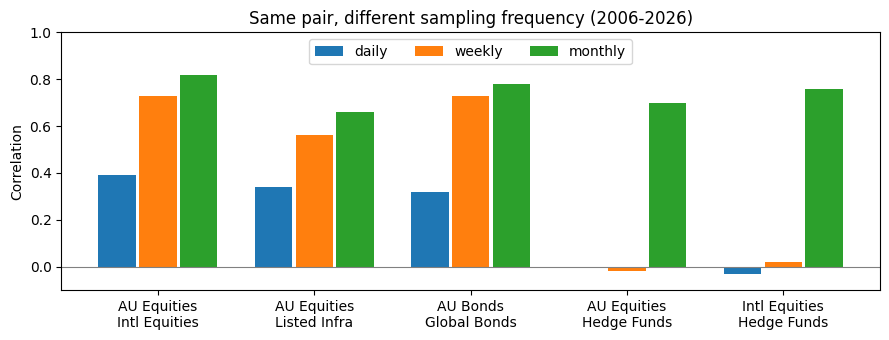

In [ ]:
# Why frequency matters: the same correlation measured at daily, weekly and monthly frequency
wd_prices = daily[daily.index.dayofweek < 5]
R_daily = wd_prices.pct_change(fill_method=None).iloc[1:].loc["2006-01-01":"2026-08-31"]
R_weekly = wd_prices.resample("W-WED").last().pct_change(fill_method=None).iloc[1:].loc["2006-01-01":"2026-08-31"]
R_monthly = monthly.pct_change(fill_method=None).iloc[1:].loc["2006-01-01":"2026-08-31"]

pairs = [("ASA52", "NDDLWI"), ("ASA52", "FDCIISAH"), ("BACM0", "H03432AU"),
         ("ASA52", "HEDGNAV"), ("NDDLWI", "HEDGNAV")]
freq_corr = pd.DataFrame({
    f"{LABEL[a]} / {LABEL[b]}": {
        "daily": R_daily[a].corr(R_daily[b]),
        "weekly": R_weekly[a].corr(R_weekly[b]),
        "monthly": R_monthly[a].corr(R_monthly[b]),
        "daily, 2nd asset lagged 1 day": R_daily[a].corr(R_daily[b].shift(1)),
    } for a, b in pairs}).T.round(2)
display(freq_corr)

fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(len(freq_corr))
for i, f in enumerate(["daily", "weekly", "monthly"]):
    ax.bar(x + (i - 1) * 0.26, freq_corr[f], 0.24, label=f)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x, [s.replace(" / ", "\n") for s in freq_corr.index])
ax.set_ylim(-0.1, 1.0)
ax.set_ylabel("Correlation")
ax.set_title("Same pair, different sampling frequency (2006-2026)")
ax.legend(ncol=3, loc="upper center")
plt.tight_layout()
plt.show()

**Q1(a) findings**

* **Different start dates.** AU equities, developed equities, hedge funds, AU bonds and cash start in January 1997; AU listed property in December 1999; global bonds in September 2000; EM equities in December 2000; listed infrastructure in December 2005. No series has missing values once it starts.
* **HEDGNAV is a monthly series reported at daily and weekly dates.** About 95% of its weekday values repeat the previous day, with a median gap of roughly a month between genuine changes. Its daily and weekly observations are not new information.
* **Some series changed frequency.** Developed equities (NDDLWI) update monthly until the end of 1998 and daily afterwards, which explains their extra weekday repeats; global bonds become daily during 2001.
* **The Daily sheet includes weekends.** Equity values repeat every Saturday and Sunday. AU bonds and cash still change on weekends until November 2015, but this is mechanical interest accrual over calendar days, not market news.
* **Daily correlations are biased.** The ASX closes before US markets open, so the same-day daily correlation between AU and developed equities is 0.39 against 0.82 monthly, and the lagged daily correlation (0.45) exceeds the same-day one. Hedge funds look uncorrelated with equities on daily data (about 0) but are about 0.7 correlated monthly. Daily data would make overseas assets and hedge funds look like far better diversifiers than they are.

## Q1(b) Return series, frequency and estimation period

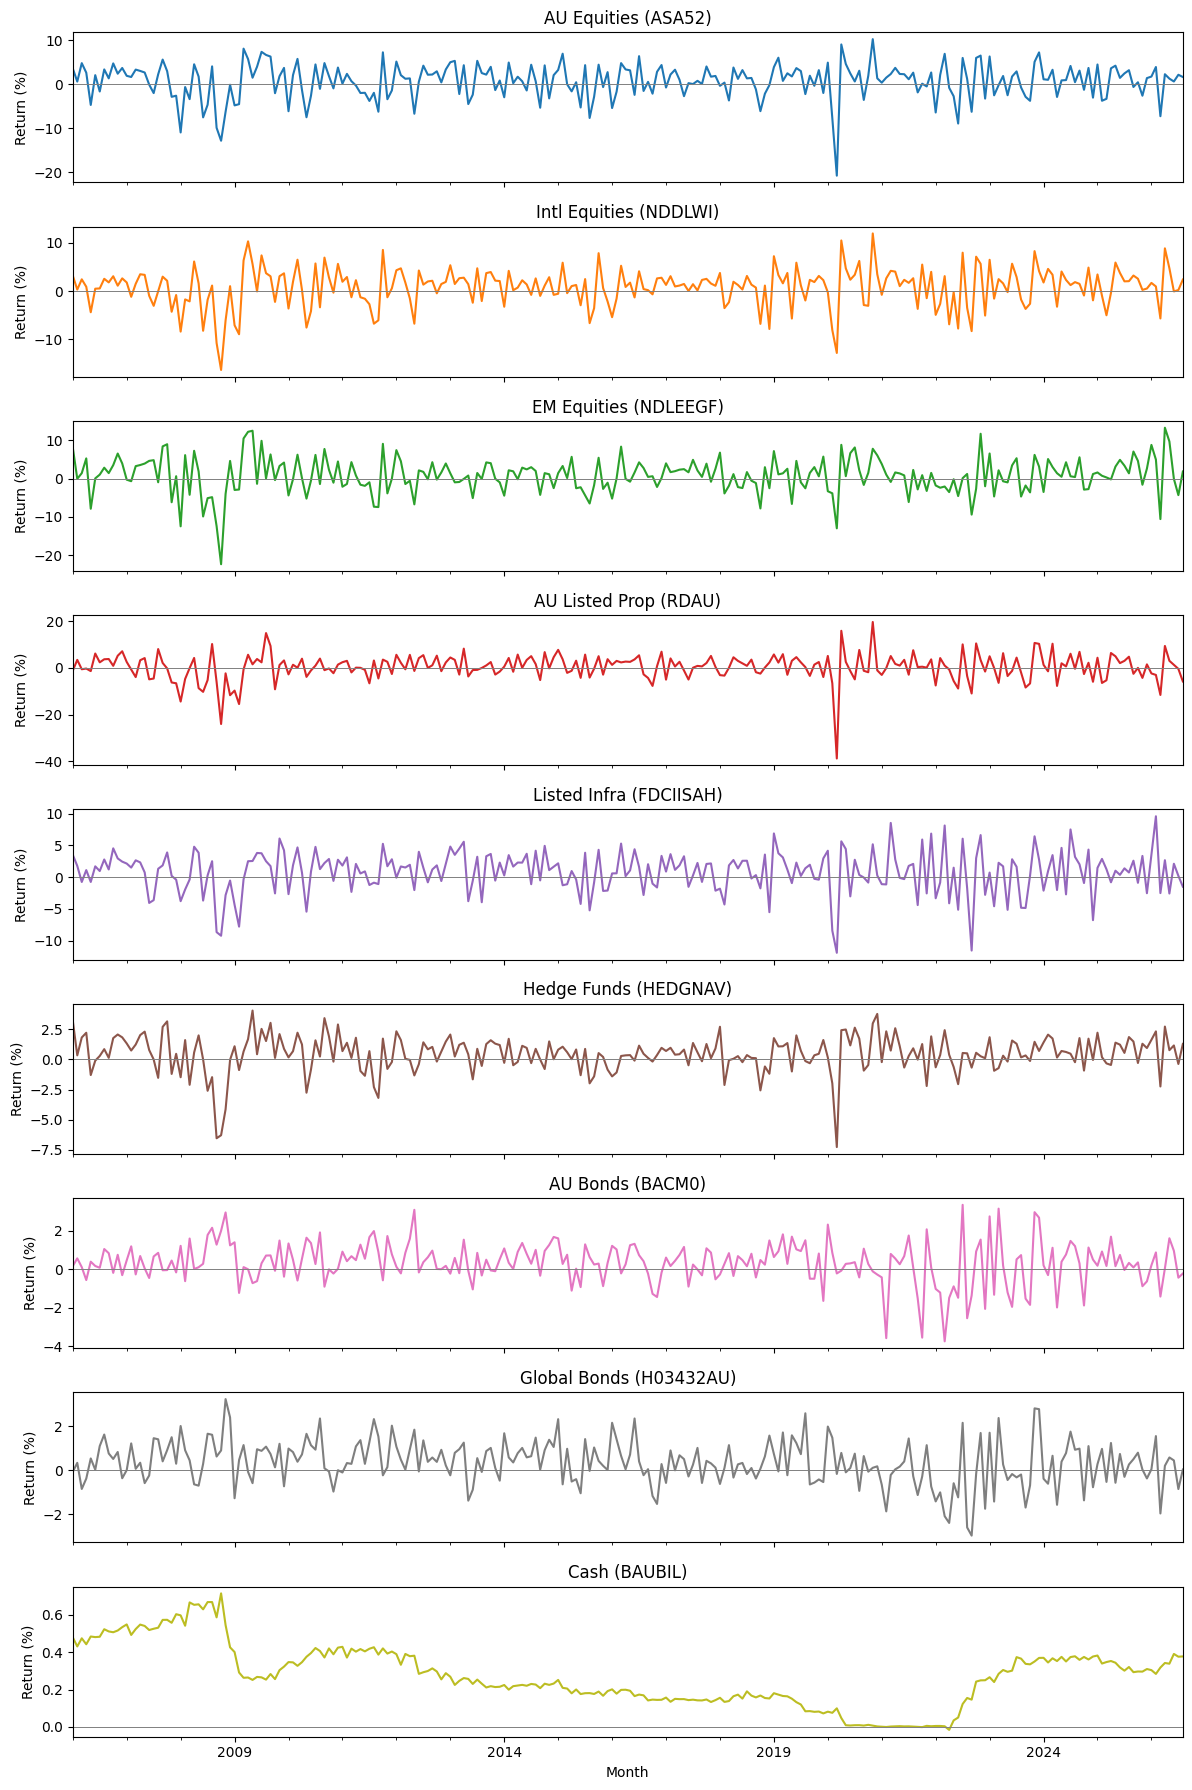

In [ ]:
# 1. Use the supplied monthly index levels
monthly_prices = datasets["Monthly"].copy().sort_index()

# Standardise dates to monthly periods
monthly_prices.index = monthly_prices.index.to_period("M")
monthly_prices.index.name = "Month"

# Check that there is only one observation per month
if monthly_prices.index.duplicated().any():
    raise ValueError("Duplicate monthly observations found.")

# Include all calendar months so missing months remain visible
full_months = pd.period_range(
    monthly_prices.index.min(),
    monthly_prices.index.max(),
    freq="M"
)
monthly_prices = monthly_prices.reindex(full_months)
monthly_prices.index.name = "Month"

# 2. Identify the common historical period (all nine assets available)
common_start = max(monthly_prices[col].first_valid_index() for col in monthly_prices.columns)
common_end = min(monthly_prices[col].last_valid_index() for col in monthly_prices.columns)

common_prices = monthly_prices.loc[common_start:common_end].copy()

# Do not fill missing values or silently remove missing months
if common_prices.isna().any().any():
    raise ValueError("Missing values remain within the common period.")

if (common_prices <= 0).any().any():
    raise ValueError("Non-positive index levels found.")

# 3. Calculate simple monthly returns
# R_t = P_t / P_(t-1) - 1
monthly_returns = common_prices.pct_change(fill_method=None).iloc[1:]

# Full history for each asset from its own start date (used for rolling estimates in Q1(e))
monthly_returns_full = monthly_prices.pct_change(fill_method=None).iloc[1:]

# Keep returns in decimal form for subsequent calculations
print("Index-level period:", common_start, "to", common_end)
print("Return period:", monthly_returns.index.min(), "to", monthly_returns.index.max())
print("Number of monthly returns:", len(monthly_returns))
print("Number of assets:", monthly_returns.shape[1])

# Display returns as percentages
display((monthly_returns.head() * 100).round(3))

# 4. Summarise the constructed return series
return_summary = pd.DataFrame({
    "First return month": [str(monthly_returns[col].first_valid_index()) for col in monthly_returns.columns],
    "Last return month": [str(monthly_returns[col].last_valid_index()) for col in monthly_returns.columns],
    "Observations": monthly_returns.notna().sum().to_numpy(),
    "Missing returns": monthly_returns.isna().sum().to_numpy(),
})
return_summary.index = monthly_returns.columns
return_summary.index.name = "Asset"
display(return_summary)

# 5. Serial correlation check: which series look smoothed (stale / appraisal-based)?
T = len(monthly_returns)
ac_table = pd.DataFrame({
    "AR(1)": monthly_returns.apply(lambda s: s.autocorr(lag=1)),
    "Significant (|AR(1)| > 2/sqrt(T))": monthly_returns.apply(lambda s: abs(s.autocorr(lag=1)) > 2 / np.sqrt(T)),
})
print(f"Significance cut-off 2/sqrt(T) = {2 / np.sqrt(T):.3f}")
display(ac_table.round(3))

# 6. Plot monthly returns (%)
plot_returns = monthly_returns.copy()
plot_returns.index = plot_returns.index.to_timestamp(how="start")

axes = (plot_returns * 100).plot(
    subplots=True,
    figsize=(12, 2 * monthly_returns.shape[1]),
    sharex=True,
    legend=False
)

for ax, asset in zip(np.atleast_1d(axes), monthly_returns.columns):
    ax.set_title(f"{LABEL[asset]} ({asset})")
    ax.set_ylabel("Return (%)")
    ax.axhline(0, color="grey", linewidth=0.7)

plt.tight_layout()
plt.show()

**Q1(b) choices**

* **Frequency: monthly.** Monthly is the highest frequency at which every asset provides genuinely new information (HEDGNAV updates monthly), and it removes the non-synchronous closing-time bias shown in Q1(a). Higher frequency would not make expected returns more precise anyway: the standard error of a mean is $\sigma/\sqrt{\text{years}}$, whatever the sampling frequency. Monthly data also suits a long-horizon strategic allocation.
* **Period: January 2006 to August 2026 (248 monthly returns).** This is the longest window in which all nine assets exist (listed infrastructure starts in December 2005). Using one common window keeps the covariance matrix internally consistent, and it covers several regimes: the GFC, the low-rate 2010s, COVID and the 2022 inflation shock.
* **Smoothing.** HEDGNAV has first-order autocorrelation of about 0.22, above the $2/\sqrt{T} \approx 0.13$ significance cut-off, while the liquid equity indices are close to zero. This is the usual sign of NAV smoothing (Getmansky, Lo and Makarov, 2004), which understates volatility, so we desmooth HEDGNAV in Q1(c). Global bonds are marginally above the cut-off but print a new value on about 98% of weekdays, so their autocorrelation reflects trending yields rather than stale prices. Cash is highly autocorrelated because interest rates are persistent, not because of stale pricing; neither is adjusted.

## Q1(c) Annualised expected returns m and covariance matrix C

In [ ]:
# --- Desmooth the hedge fund series (Geltner) ---
# HEDGNAV is a NAV-based index: its monthly returns are autocorrelated (~0.22),
# which understates its true volatility and correlation with other assets.
# r*_t = (r_t - rho * r_(t-1)) / (1 - rho)  keeps the mean, restores the hidden volatility.
def desmooth(r):
    r = r.dropna()
    rho = r.autocorr(lag=1)
    out = (r - rho * r.shift(1)) / (1 - rho)
    out.iloc[0] = r.iloc[0]          # first month has no lag; keep the observed return
    return out, rho

est_returns = monthly_returns.copy()  # used for ESTIMATION (monthly_returns stays raw for realised performance)
hf = monthly_returns["HEDGNAV"]
est_returns["HEDGNAV"], rho = desmooth(hf)
print(f"HEDGNAV AR(1) = {rho:.3f}; vol raw {hf.std()*np.sqrt(12):.2%} -> desmoothed {est_returns['HEDGNAV'].std()*np.sqrt(12):.2%}")

# Annualised expected returns (iid monthly returns: mean scales by 12)
m = est_returns.mean() * 12

# Annualised sample variance-covariance matrix (variance scales by 12)
C = est_returns.cov() * 12

# Annualised volatilities
annual_volatility = pd.Series(np.sqrt(np.diag(C)), index=C.index)

# Correlation matrix
correlation = est_returns.corr()

# Risk-free rate: average cash (bank bill) return over the same window
rf = m["BAUBIL"]

# Precision of the expected-return estimates: SE(m) = sigma / sqrt(years)
years = len(est_returns) / 12
se_m = annual_volatility / np.sqrt(years)

parameter_summary = pd.DataFrame({
    "Annualised expected return (%)": m * 100,
    "Annualised volatility (%)": annual_volatility * 100,
    "SE of mean (%)": se_m * 100,
    "95% CI low (%)": (m - 1.96 * se_m) * 100,
    "95% CI high (%)": (m + 1.96 * se_m) * 100,
    "Sharpe ratio vs cash": (m - rf) / annual_volatility,
})
parameter_summary.loc["BAUBIL", "Sharpe ratio vs cash"] = np.nan
display(parameter_summary.round(3))
print(f"Risk-free rate (mean cash return, annualised): {rf:.2%}")

print("Annualised covariance matrix (decimal-return units):")
display(C.round(6))

print("Correlation matrix:")
display(correlation.round(3))

**Q1(c) notes**

* With monthly returns $r_t$, the annualised estimates are $m = 12\,\bar r$ and $C = 12\,\widehat{\text{Cov}}(r)$. This assumes monthly returns are approximately serially uncorrelated, so means and variances scale linearly with time, which is why HEDGNAV is desmoothed first using Geltner's (1993) method, $r^*_t = (r_t - \rho r_{t-1})/(1-\rho)$. Desmoothing leaves its mean virtually unchanged but raises its volatility from about 5.3% to 6.6%.
* These are arithmetic means, the correct input for a one-period mean-variance problem; the compound growth rate is approximately $m - \sigma^2/2$.
* The risk-free rate is the average annualised return on cash (bank bills) over the same window, about 3.3%.
* **Expected returns are imprecise.** For the equity indices the standard error of the mean is about 3% a year, so their 95% confidence intervals span roughly ±6%. Cross-sectional differences in m are therefore weakly identified, which matters for the optimisation in Q2.

## Q1(d) Is C a valid covariance matrix?

In [ ]:
# Q1(d): Validate the annualised covariance matrix

C_array = C.to_numpy(dtype=float)

if not np.isfinite(C_array).all():
    raise ValueError("C contains missing or infinite values.")

# 1. Check symmetry
symmetry_error = np.max(np.abs(C_array - C_array.T))
is_symmetric = np.allclose(C_array, C_array.T, rtol=1e-10, atol=1e-12)

# 2. Check positive semidefiniteness
# Average with the transpose to remove numerical asymmetry
C_symmetric = (C_array + C_array.T) / 2
eigenvalues, eigenvectors = np.linalg.eigh(C_symmetric)

# Allow very small negative values caused by floating-point error
tolerance = 1e-10 * max(1.0, np.max(np.abs(eigenvalues)))
is_psd = eigenvalues.min() >= -tolerance

print("Symmetric:", is_symmetric)
print("Maximum symmetry error:", symmetry_error)
print("Minimum eigenvalue:", eigenvalues.min())
print("Positive semidefinite:", is_psd)

# 3. How close to singular is C? (large condition number = unstable optimal weights)
condition_number = eigenvalues.max() / eigenvalues.min()
print(f"Condition number: {condition_number:,.0f}")

display(pd.DataFrame({"Eigenvalue": eigenvalues}))

# Which portfolios have almost no variance? (eigenvectors of the two smallest eigenvalues)
display(pd.DataFrame(
    {"Smallest eigenvector": eigenvectors[:, 0], "2nd smallest": eigenvectors[:, 1]},
    index=C.index
).round(2))

if is_symmetric and is_psd:
    print("C passes both checks; no correction is required.")
else:
    print("C fails a check; investigate before portfolio optimisation.")

**Q1(d) findings**

The estimated covariance matrix is symmetric (maximum symmetry error of zero) and its smallest eigenvalue is about $2.86 \times 10^{-5} > 0$. All eigenvalues are positive, so C is positive definite and therefore positive semidefinite; no correction is needed. This is expected: a sample covariance matrix computed from one common sample with $T = 248 > N = 9$ is positive semidefinite by construction.

C is, however, **ill-conditioned** (condition number about 3,000). The eigenvector of the smallest eigenvalue is almost pure cash, which barely moves, and the next is a long-short position in AU and global bonds (correlation 0.78). Near-singularity makes unconstrained mean-variance weights unstable, which is one reason for the weight limits in Q2.

Positive semidefiniteness can fail when C is assembled from **different samples or by hand**: pairwise histories with different start dates, mixed sampling frequencies, or stress-scenario correlations chosen one pair at a time. Such correlations need not be mutually consistent, so the matrix can imply a portfolio with negative variance. A simple fix would be to compute the eigen-decomposition of C, set any negative eigenvalues to zero and rebuild the matrix. This was not needed here.

## Q1(e) Stability of the estimates over time

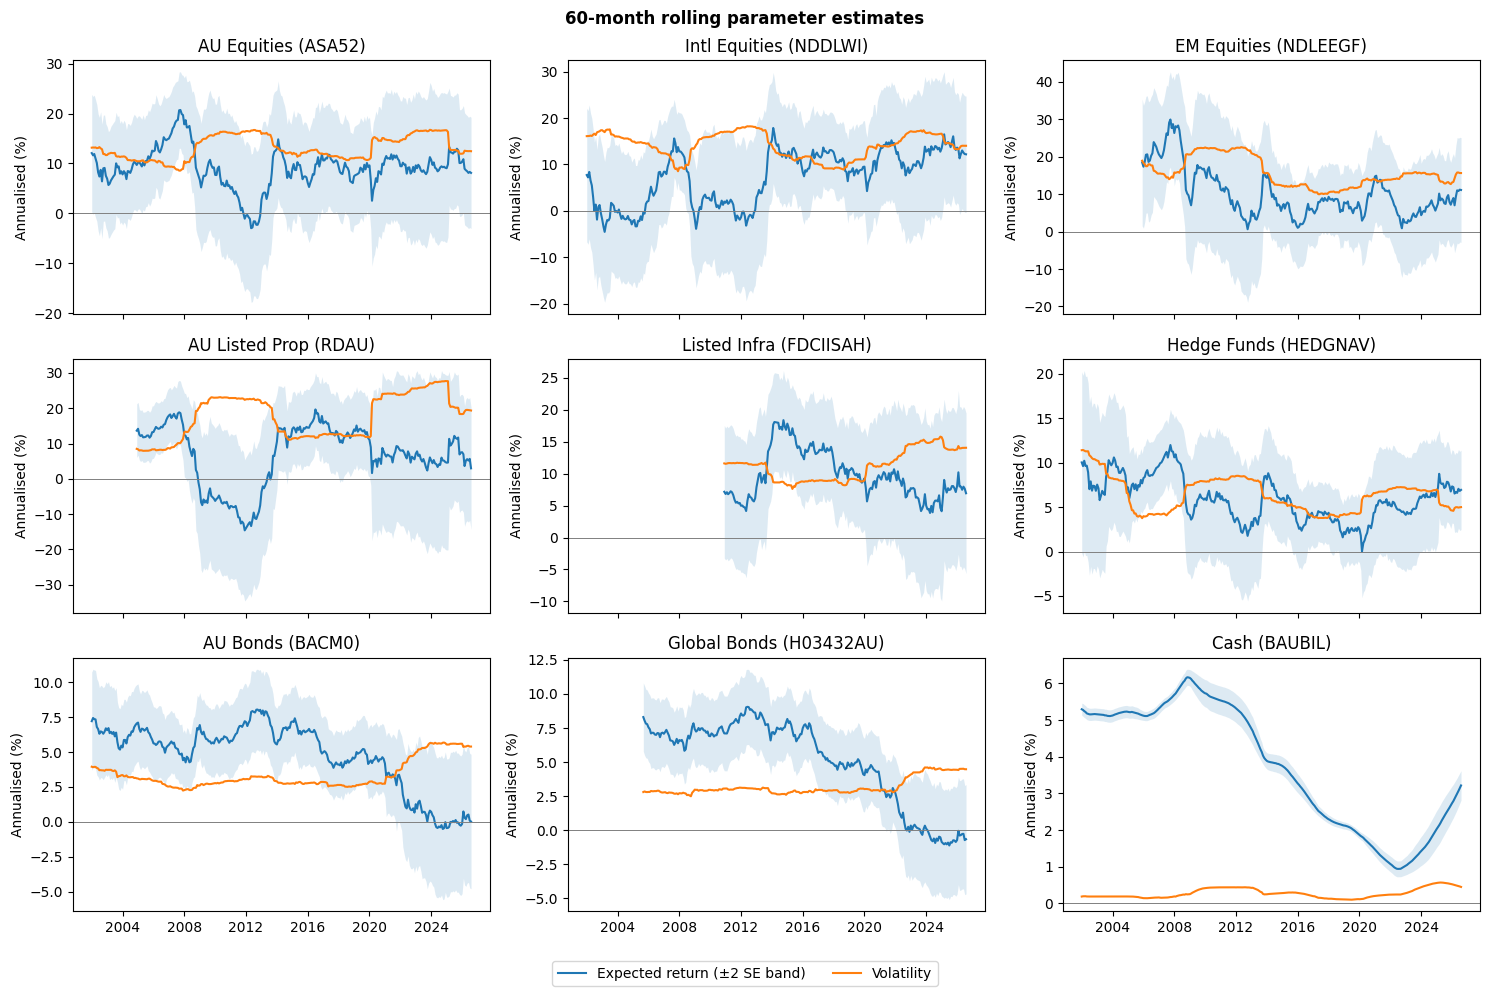

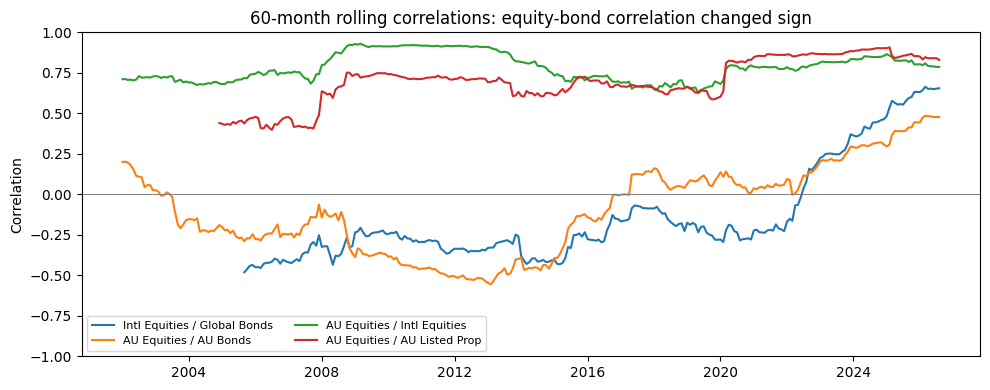

In [ ]:
# Uses est_returns (HEDGNAV desmoothed) so every estimate is consistent with Q1(c)

# 1. Compare different estimation periods
samples = {
    "Full sample": est_returns,
    "Last 10 years": est_returns.iloc[-120:],
    "Last 5 years": est_returns.iloc[-60:],
    "2006-2015": est_returns.loc["2006-01":"2015-12"],
}

# Store estimates for later use in Question 2(d)
parameter_sets = {}

for name, sample in samples.items():
    parameter_sets[name] = {
        "m": sample.mean() * 12,
        "C": sample.cov() * 12,
        "volatility": sample.std(ddof=1) * np.sqrt(12),
        "correlation": sample.corr(),
    }

# Show the dates and sample sizes
period_summary = pd.DataFrame({
    name: {"Start": str(sample.index.min()), "End": str(sample.index.max()), "Months": len(sample)}
    for name, sample in samples.items()
}).T
display(period_summary)

# Annualised expected returns (%)
mean_comparison = pd.DataFrame({name: est["m"] * 100 for name, est in parameter_sets.items()})

# Annualised volatilities (%)
vol_comparison = pd.DataFrame({name: est["volatility"] * 100 for name, est in parameter_sets.items()})

print("Annualised expected returns (%):")
display(mean_comparison.round(3))

print("Annualised volatilities (%):")
display(vol_comparison.round(3))

# How precisely is each parameter estimated? (full sample)
# SE(mean) = sigma / sqrt(years);  SE(vol)/vol ~ 1 / sqrt(2T)
relative_error = pd.DataFrame({
    "SE(mean) / |mean|": se_m / m.abs(),
    "SE(vol) / vol": 1 / np.sqrt(2 * len(est_returns)),
})
print("Relative estimation error, full sample (means are far less precise than volatilities):")
display(relative_error.round(2))


# 2. Compare correlations for all distinct asset pairs
assets = est_returns.columns.tolist()
pair_rows = []

for i in range(len(assets)):
    for j in range(i + 1, len(assets)):
        a, b = assets[i], assets[j]
        row = {"Asset pair": f"{a} / {b}"}
        for name, est in parameter_sets.items():
            row[name] = est["correlation"].loc[a, b]
        row["5Y minus full"] = row["Last 5 years"] - row["Full sample"]
        pair_rows.append(row)

correlation_comparison = pd.DataFrame(pair_rows).set_index("Asset pair")

# Display the 10 largest absolute correlation changes
largest_changes = (
    correlation_comparison["5Y minus full"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

print("Largest correlation changes: last 5 years versus full sample")
display(correlation_comparison.loc[largest_changes].round(3))


# 3. Plot 60-month rolling expected returns and volatilities
# Uses each asset's full history (from 1997 where available) so the rolling window covers more regimes
window = 60

R_full = monthly_returns_full.copy()
R_full["HEDGNAV"], _ = desmooth(R_full["HEDGNAV"])

rolling_mean = (R_full.rolling(window).mean() * 12).loc["2001":]
rolling_vol = (R_full.rolling(window).std(ddof=1) * np.sqrt(12)).loc["2001":]
rolling_se = rolling_vol / np.sqrt(window / 12)          # standard error of a 5-year mean

# Convert PeriodIndex for plotting
rolling_mean.index = rolling_mean.index.to_timestamp()
rolling_vol.index = rolling_vol.index.to_timestamp()
rolling_se.index = rolling_se.index.to_timestamp()

fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)

for ax, asset in zip(axes.flat, assets):
    ax.fill_between(
        rolling_mean.index,
        (rolling_mean[asset] - 2 * rolling_se[asset]) * 100,
        (rolling_mean[asset] + 2 * rolling_se[asset]) * 100,
        alpha=0.15, color="C0", linewidth=0
    )
    ax.plot(rolling_mean.index, rolling_mean[asset] * 100, color="C0", label="Expected return (±2 SE band)")
    ax.plot(rolling_vol.index, rolling_vol[asset] * 100, color="C1", label="Volatility")
    ax.set_title(f"{LABEL[asset]} ({asset})")
    ax.set_ylabel("Annualised (%)")
    ax.axhline(0, color="grey", linewidth=0.7)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.suptitle("60-month rolling parameter estimates", fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.legend(handles, labels, loc="lower center", ncol=2)
plt.show()


# 4. Rolling correlations: the pair with the largest change, plus the key equity-bond pairs
pair_values = [
    (a, b, abs(parameter_sets["Last 5 years"]["correlation"].loc[a, b]
               - parameter_sets["Full sample"]["correlation"].loc[a, b]))
    for i, a in enumerate(assets)
    for b in assets[i + 1:]
]
asset_a, asset_b, _ = max(pair_values, key=lambda item: item[2])
print(f"Pair with the largest correlation change: {asset_a} / {asset_b}")

plot_pairs = [(asset_a, asset_b)] + [p for p in [("ASA52", "BACM0"), ("ASA52", "NDDLWI"), ("ASA52", "RDAU")]
                                     if set(p) != {asset_a, asset_b}]

fig, ax = plt.subplots(figsize=(10, 4))
for a, b in plot_pairs:
    rolling_corr = R_full[a].rolling(window).corr(R_full[b]).loc["2002":]
    ax.plot(rolling_corr.index.to_timestamp(), rolling_corr, label=f"{LABEL[a]} / {LABEL[b]}")
ax.axhline(0, color="grey", linewidth=0.7)
ax.set_ylim(-1, 1)
ax.set_ylabel("Correlation")
ax.legend(ncol=2, loc="lower left", fontsize=8)
ax.set_title("60-month rolling correlations: equity-bond correlation changed sign")
fig.tight_layout()
plt.show()

**Q1(e) findings**

* **Expected returns are the least stable input.** AU bonds returned about 6.1% a year in 2006-2015 but only 1.7% over the last 10 years and roughly 0% over the last 5; developed equities went from 5.9% to about 13.5%. Rolling 5-year equity means swing over a range of more than 20 percentage points, and their ±2 standard-error band includes zero about two-thirds of the time. Even over the full sample, the standard error of an equity mean is about a third of the estimate itself (almost the whole estimate for listed property).
* **Volatilities are much more stable.** Their relative standard error is about 4% for every asset, and rolling volatilities stay within a band apart from crisis spikes (GFC, COVID).
* **Correlations move with the regime.** The largest change is between equities and bonds: the developed equity / global bond correlation was about -0.27 in 2006-2015 but about +0.655 over the last 5 years, and the AU equity / AU bond correlation shows the same sign change. When inflation drives both equities and bonds down, as in 2022, defensive assets diversify much less than history suggests.

**Implications for portfolio construction.** Mean-variance optimisers are most sensitive to the input we estimate worst, the expected returns, so small changes in m can swing the optimal weights. This motivates long-only constraints and weight limits (Q2), comparing results across the estimation periods stored in `parameter_sets` (Q2(d)), the bootstrap in Q4(c), and out-of-sample testing using only information available at each date (Q5, Q6).


# Q2 Static portfolio optimisation
## Q2(a) Constraints and efficient frontier

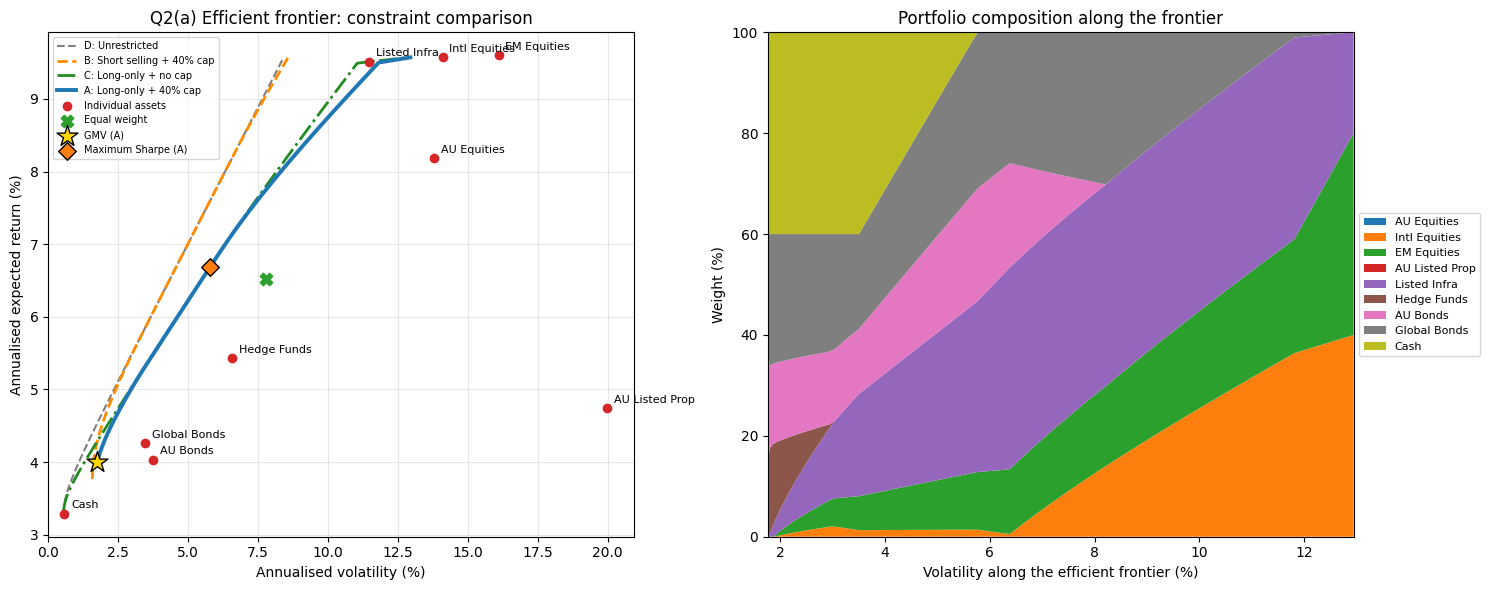

In [ ]:
# ======================================================================
# Q2(a)  Portfolio constraints, optimiser and efficient frontier
# ======================================================================
import warnings
from scipy.optimize import minimize, linprog, minimize_scalar, nnls

# ---------- 1. Inputs from Q1: full-sample m and C (HEDGNAV desmoothed) ----------
assets = list(m.index)
assert list(C.index) == assets and list(C.columns) == assets, "m and C must use the same asset order"
N = len(assets)
asset_labels = [LABEL[a] for a in assets]

def to_arrays(m_series, C_frame):
    """Align any Q1-style (m, C) pair to `assets`; return clean numpy arrays with C exactly symmetric."""
    mu_ = m_series.reindex(assets).to_numpy(dtype=float)
    S_ = C_frame.reindex(index=assets, columns=assets).to_numpy(dtype=float)
    assert np.isfinite(mu_).all() and np.isfinite(S_).all()
    return mu_, 0.5 * (S_ + S_.T)

mu_hat, Sigma_hat = to_arrays(m, C)

# ---------- 2. Portfolio constraints  ----------
W_MIN = 0.0      # no short selling (long-only)
W_MAX = 0.40     # no single asset above 40%
LB = np.full(N, W_MIN)
UB = np.full(N, W_MAX)
assert LB.sum() <= 1 <= UB.sum(), "constraints leave no fully invested portfolio"
# Full investment 1'x = 1 is always imposed inside the solver.

# ---------- 3. Optimiser ----------
TOL_ACTIVE = 1e-7

def kkt_check(x, grad, lb, ub, A_eq, mu=None, target=None, equality=False):
    """Exact first-order (KKT) optimality test for a convex QP.
    Stationarity: grad F(x) = A_eq' lambda  [+ nu*mu if the return constraint binds] + s_lb - s_ub,
    with nu >= 0 (inequality), s_lb, s_ub >= 0 on the weights sitting at their bounds.
    Solved as a non-negative least-squares problem: the returned residual is ~0 iff x is optimal."""
    n = len(x)
    cols = []
    for a in A_eq:
        cols += [a, -a]                                   # free-sign multipliers
    nu_cols = None
    if mu is not None and target is not None:
        if equality:
            nu_cols = (len(cols), len(cols) + 1); cols += [mu, -mu]
        elif mu @ x - target < TOL_ACTIVE:                # return constraint is binding
            nu_cols = (len(cols),); cols.append(mu)
    eye = np.eye(n)
    for i in range(n):
        if x[i] <= lb[i] + TOL_ACTIVE: cols.append(eye[i])
        if x[i] >= ub[i] - TOL_ACTIVE: cols.append(-eye[i])
    sol, rnorm = nnls(np.column_stack(cols), grad, maxiter=20000)
    nu = 0.0
    if nu_cols is not None:
        nu = sol[nu_cols[0]] - (sol[nu_cols[1]] if len(nu_cols) == 2 else 0.0)
    return rnorm / (1.0 + np.max(np.abs(grad))), nu

def solve_portfolio(mu, Sg, lb=None, ub=None, target=None, equality=False, gamma=None,
                    A_eq=None, b_eq=None, check=True, return_info=False, label=""):
    """General long-only (box-constrained) mean-variance solver.
       gamma is None : minimise  x'Sg x          s.t. 1'x = 1, lb <= x <= ub, [mu'x >= target (or = if equality)]
       gamma given   : maximise  mu'x - gamma/2 x'Sg x   s.t. the same constraints   (used from Q4 on)
       A_eq, b_eq    : optional extra linear equalities  A_eq x = b_eq  (e.g. growth exposure in Q3)
       Every solution is verified by an exact KKT test (check=True)."""
    mu = np.asarray(mu, float); Sg = np.asarray(Sg, float); n = len(mu)
    lb = LB if lb is None else np.asarray(lb, float)
    ub = UB if ub is None else np.asarray(ub, float)
    assert len(lb) == n and len(ub) == n and Sg.shape == (n, n)

    A_list, b_list = [np.ones(n)], [1.0]
    if A_eq is not None:
        A_list += list(np.atleast_2d(A_eq)); b_list += list(np.atleast_1d(b_eq))
    Aeq, beq = np.array(A_list, float), np.array(b_list, float)

    # feasible starting point: average of three random LP vertices (a convex combination is feasible)
    lp_Aeq, lp_beq, lp_Aub, lp_bub = Aeq, beq, None, None
    if target is not None:
        if equality: lp_Aeq, lp_beq = np.vstack([Aeq, mu]), np.append(beq, target)
        else:        lp_Aub, lp_bub = -mu[None, :], [-target]
    rng = np.random.default_rng(0)
    starts = []
    for _ in range(3):
        r = linprog(rng.normal(size=n), A_ub=lp_Aub, b_ub=lp_bub, A_eq=lp_Aeq, b_eq=lp_beq,
                    bounds=list(zip(lb, ub)), method="highs")
        if r.status == 2:
            raise ValueError(f"Infeasible constraints {label} (target={target})")
        if not r.success:
            raise RuntimeError(f"LP start failed: {r.message}")
        starts.append(r.x)
    x0 = np.mean(starts, axis=0)

    scale = 1e3
    if gamma is None:
        fun  = lambda x: scale * (x @ Sg @ x)
        jac  = lambda x: 2 * scale * (Sg @ x)
        grad = lambda x: 2 * (Sg @ x)
    else:
        fun  = lambda x: scale * (-mu @ x + 0.5 * gamma * (x @ Sg @ x))
        jac  = lambda x: scale * (-mu + gamma * (Sg @ x))
        grad = lambda x: -mu + gamma * (Sg @ x)
    cons = [{"type": "eq", "fun": lambda x: Aeq @ x - beq, "jac": lambda x: Aeq}]
    if target is not None:
        if equality: cons.append({"type": "eq",   "fun": lambda x: mu @ x - target, "jac": lambda x: mu})
        else:        cons.append({"type": "ineq", "fun": lambda x: mu @ x - target, "jac": lambda x: mu})

    def run(start):
        res = minimize(fun, start, jac=jac, bounds=list(zip(lb, ub)), constraints=cons,
                       method="SLSQP", options={"ftol": 1e-15, "maxiter": 2000})
        return np.clip(res.x, lb, ub)

    x = run(x0)
    resid, nu = kkt_check(x, grad(x), lb, ub, Aeq, mu, target, equality) if check else (np.nan, 0.0)
    if check and resid > 1e-6:                               # polish once from the current point
        x = run(x)
        resid, nu = kkt_check(x, grad(x), lb, ub, Aeq, mu, target, equality)
    # hard feasibility checks
    if np.max(np.abs(Aeq @ x - beq)) > 1e-7:
        raise RuntimeError(f"Equality constraints violated {label}: {np.max(np.abs(Aeq @ x - beq)):.2e}")
    if target is not None and not equality and mu @ x < target - 1e-7:
        raise RuntimeError(f"Return target missed {label}")
    if check and resid > 1e-5:
        warnings.warn(f"KKT residual {resid:.2e} {label}: solution may not be optimal")
    if return_info:
        return x, {"kkt_residual": resid, "nu": nu, "return_slack": (mu @ x - target) if target is not None else np.nan}
    return x

def port_stats(x, mu, Sg):
    """Expected return and volatility (annualised, decimal units)."""
    return float(mu @ x), float(np.sqrt(x @ Sg @ x))

def max_return_portfolio(mu, lb=None, ub=None, A_eq=None, b_eq=None):
    """Highest attainable expected return under the constraints (exact LP)."""
    mu = np.asarray(mu, float); n = len(mu)
    lb = LB if lb is None else np.asarray(lb, float); ub = UB if ub is None else np.asarray(ub, float)
    A_list, b_list = [np.ones(n)], [1.0]
    if A_eq is not None:
        A_list += list(np.atleast_2d(A_eq)); b_list += list(np.atleast_1d(b_eq))
    r = linprog(-mu, A_eq=np.array(A_list), b_eq=np.array(b_list), bounds=list(zip(lb, ub)), method="highs")
    assert r.success, r.message
    return r.x

def efficient_frontier(mu, Sg, lb=None, ub=None, n_points=80, A_eq=None, b_eq=None):
    """Efficient frontier: for target returns from the GMV return up to the maximum attainable return,
    solve  min x'Sg x  s.t.  mu'x >= target, 1'x = 1, bounds.  Returns a DataFrame (target, ret, vol, weights)."""
    x_gmv = solve_portfolio(mu, Sg, lb, ub, A_eq=A_eq, b_eq=b_eq, label="GMV")
    r_gmv = port_stats(x_gmv, mu, Sg)[0]
    x_max = max_return_portfolio(mu, lb, ub, A_eq, b_eq)
    r_max = port_stats(x_max, mu, Sg)[0]
    targets = np.linspace(r_gmv, r_max, n_points)
    W = [x_gmv]
    for t in targets[1:-1]:
        W.append(solve_portfolio(mu, Sg, lb, ub, target=t, A_eq=A_eq, b_eq=b_eq, label="frontier"))
    W.append(solve_portfolio(mu, Sg, lb, ub, target=r_max - 1e-10, A_eq=A_eq, b_eq=b_eq, label="frontier end"))
    W = np.array(W)
    stats = np.array([port_stats(w, mu, Sg) for w in W])
    out = pd.DataFrame(W, columns=assets)
    out.insert(0, "vol", stats[:, 1]); out.insert(0, "ret", stats[:, 0]); out.insert(0, "target", targets)
    return out

# ---------- 4. Efficient frontier (full-sample parameters) ----------
frontier = efficient_frontier(mu_hat, Sigma_hat, n_points=80)
w_gmv_a = frontier.loc[0, assets].to_numpy(float)
ret_gmv, vol_gmv = port_stats(w_gmv_a, mu_hat, Sigma_hat)
ret_max = frontier["ret"].iloc[-1]

# maximum-Sharpe portfolio on the constrained frontier (risk-free rate = mean cash return from Q1)
def sharpe_at(t):
    x = solve_portfolio(mu_hat, Sigma_hat, target=t, label="sharpe")
    r, v = port_stats(x, mu_hat, Sigma_hat)
    return (r - rf) / v
assert rf < ret_gmv, "risk-free rate above GMV return: tangency portfolio not defined this way"
grid_t = np.linspace(ret_gmv, ret_max - 1e-6, 400)
best_t = grid_t[np.argmax([sharpe_at(t) for t in grid_t])]
step = grid_t[1] - grid_t[0]
opt = minimize_scalar(lambda t: -sharpe_at(t), bounds=(max(ret_gmv, best_t - step), min(ret_max - 1e-6, best_t + step)),
                      method="bounded", options={"xatol": 1e-10})
w_tan_a = solve_portfolio(mu_hat, Sigma_hat, target=opt.x, label="tangency")
ret_tan, vol_tan = port_stats(w_tan_a, mu_hat, Sigma_hat)

# ---------- 5. Reference curves: no constraints except 1'x = 1 (short selling allowed, closed form) ----------
one = np.ones(N); Si = np.linalg.inv(Sigma_hat)
A_, B_, C_ = one @ Si @ one, one @ Si @ mu_hat, mu_hat @ Si @ mu_hat
D_ = A_ * C_ - B_ ** 2
unc_var = lambda r: (A_ * r ** 2 - 2 * B_ * r + C_) / D_
unc_w   = lambda r: Si @ (one * (C_ - B_ * r) + mu_hat * (A_ * r - B_)) / D_
unc_ret_gmv = B_ / A_


# ---------- 5b. Additional frontiers for constraint comparison ----------

# B: Short selling allowed, but each long position capped at 40%.
# Use -inf rather than -0.4 to avoid introducing a separate short limit.
lb_B = np.full(N, -np.inf)
ub_B = np.full(N, 0.40)

# C: Long-only, without the 40% concentration cap.
lb_C = np.zeros(N)
ub_C = np.ones(N)

# Use the original frontier maximum return as the common upper
# plotting limit. Each frontier starts at its own GMV return.
plot_return_max = ret_max

def comparison_frontier(lb, ub, label, n_points=80):
    w_gmv = solve_portfolio(
        mu_hat, Sigma_hat,
        lb=lb, ub=ub,
        label=f"{label} GMV"
    )
    r_gmv, v_gmv = port_stats(w_gmv, mu_hat, Sigma_hat)

    targets = np.linspace(r_gmv, plot_return_max, n_points)
    weights = [w_gmv]

    for target in targets[1:]:
        w = solve_portfolio(
            mu_hat, Sigma_hat,
            lb=lb, ub=ub,
            target=target,
            label=label
        )
        weights.append(w)

    weights = np.asarray(weights)
    stats = np.array([
        port_stats(w, mu_hat, Sigma_hat)
        for w in weights
    ])

    return {
        "ret": stats[:, 0],
        "vol": stats[:, 1],
        "weights": weights,
        "gmv_return": r_gmv,
        "gmv_vol": v_gmv
    }

frontier_B = comparison_frontier(
    lb_B, ub_B, "Short selling + 40% cap"
)

frontier_C = comparison_frontier(
    lb_C, ub_C, "Long-only + no cap"
)

# Diagnostic information at the GMV portfolios
for name, f in [
    ("B: Short selling + 40% cap", frontier_B),
    ("C: Long-only + no cap", frontier_C)
]:
    w = f["weights"][0]
    print(f"\n{name}")
    print(f"GMV return: {f['gmv_return']:.2%}")
    print(f"GMV volatility: {f['gmv_vol']:.2%}")
    print(f"Minimum weight: {w.min():.2%}")
    print(f"Maximum weight: {w.max():.2%}")
    print(f"Gross exposure: {np.abs(w).sum():.2%}")


# ---------- 6. Verification of the Q2(a) results (every line must print PASS) ----------
checks = {}
# (i) constraints hold at every frontier point
Wf = frontier[assets].to_numpy()
checks["weights sum to 1 (all points)"] = np.abs(Wf.sum(1) - 1).max() < 1e-8
checks["weights within [W_MIN, W_MAX]"] = (Wf.min() >= W_MIN - 1e-8) and (Wf.max() <= W_MAX + 1e-8)
# (ii) shape: return and volatility both rise along the efficient frontier
checks["return strictly increasing"] = (np.diff(frontier["ret"]) > 0).all()
checks["volatility non-decreasing"] = (np.diff(frontier["vol"]) >= -1e-10).all()
# (iii) every frontier point passes the exact KKT optimality test
kkt_res = [solve_portfolio(mu_hat, Sigma_hat, target=t, return_info=True)[1]["kkt_residual"] for t in frontier["target"].iloc[1:-1]]
checks[f"KKT optimality at all points (max resid {max(kkt_res):.1e})"] = max(kkt_res) < 1e-6
# (iv) the solver reproduces the closed-form unconstrained frontier when the bounds are made non-binding
r_test = ret_max
x_wide = solve_portfolio(mu_hat, Sigma_hat, lb=np.full(N, -50.0), ub=np.full(N, 50.0), target=r_test)
checks["solver = closed form (unconstrained)"] = np.abs(x_wide - unc_w(r_test)).max() < 1e-6
# (v) constrained frontier can never beat the unconstrained one
v_con = frontier["vol"].to_numpy() ** 2
checks["constrained var >= unconstrained var"] = (v_con >= unc_var(frontier["ret"].to_numpy()) - 1e-10).all()
# (vi) no random feasible portfolio beats the optimiser at its own return level
rng = np.random.default_rng(42)
cand = rng.dirichlet(np.ones(N), size=20000)
cand = cand[(cand <= W_MAX).all(1)][:300]
gaps = []
for x in cand:
    r_c, v_c = port_stats(x, mu_hat, Sigma_hat)
    xo = solve_portfolio(mu_hat, Sigma_hat, target=r_c)
    gaps.append(v_c ** 2 - port_stats(xo, mu_hat, Sigma_hat)[1] ** 2)
checks[f"300 random portfolios never beat optimiser (min gap {min(gaps):.1e})"] = min(gaps) >= -1e-10
# (vii) optional cross-check against an independent solver (cvxpy), if installed
try:
    import cvxpy as cp
    worst = 0.0
    for t in frontier["target"].iloc[1:-1:8]:
        xv = cp.Variable(N)
        cp.Problem(cp.Minimize(cp.quad_form(xv, cp.psd_wrap(Sigma_hat))),
                   [cp.sum(xv) == 1, xv >= W_MIN, xv <= W_MAX, mu_hat @ xv >= t]).solve(solver=cp.CLARABEL, tol_gap_abs=1e-13, tol_gap_rel=1e-13, tol_feas=1e-13)
        worst = max(worst, np.abs(xv.value - solve_portfolio(mu_hat, Sigma_hat, target=t)).max())
    checks[f"matches cvxpy (max weight diff {worst:.1e})"] = worst < 1e-6
except ImportError:
    print("(cvxpy not installed: independent cross-check skipped; KKT test above already proves optimality)")
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values()), "Q2(a) verification failed - do not use these results"

# ---------- 7. Report ----------
print(f"\nConstraints: long-only (x_i >= {W_MIN:.0%}), x_i <= {W_MAX:.0%}, fully invested (sum = 100%)")
print(f"Frontier runs from GMV  (return {ret_gmv:.2%}, vol {vol_gmv:.2%})  to the maximum-return portfolio "
      f"(return {ret_max:.2%}, vol {frontier['vol'].iloc[-1]:.2%})")
print(f"Max-Sharpe portfolio (rf = {rf:.2%}): return {ret_tan:.2%}, vol {vol_tan:.2%}, Sharpe {(ret_tan - rf) / vol_tan:.3f}")
sel = frontier.iloc[np.linspace(0, len(frontier) - 1, 9).astype(int)].copy()
tab = pd.DataFrame({"Target (%)": sel["target"] * 100, "Return (%)": sel["ret"] * 100, "Vol (%)": sel["vol"] * 100})
tab = pd.concat([tab, sel[assets].rename(columns=LABEL) * 100], axis=1).round(2)
display(tab.reset_index(drop=True))

# ---------- 8. Plot ----------
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

a0 = ax[0]

# D: Unrestricted frontier (original closed-form solution)
r_u = np.linspace(unc_ret_gmv, ret_max, 200)
a0.plot(
    np.sqrt(np.maximum(unc_var(r_u), 0)) * 100,
    r_u * 100,
    "--", color="grey", lw=1.5,
    label="D: Unrestricted"
)

# B: Short selling allowed, 40% long-position cap
a0.plot(
    frontier_B["vol"] * 100,
    frontier_B["ret"] * 100,
    "--", color="darkorange", lw=2,
    label="B: Short selling + 40% cap"
)

# C: Long-only, no concentration cap
a0.plot(
    frontier_C["vol"] * 100,
    frontier_C["ret"] * 100,
    "-.", color="forestgreen", lw=2,
    label="C: Long-only + no cap"
)

# A: Original constrained frontier
a0.plot(
    frontier["vol"] * 100,
    frontier["ret"] * 100,
    "-", color="C0", lw=2.8,
    label="A: Long-only + 40% cap"
)

# Individual assets
a0.scatter(
    np.sqrt(np.diag(Sigma_hat)) * 100,
    mu_hat * 100,
    color="C3", zorder=3,
    label="Individual assets"
)

for i, lab in enumerate(asset_labels):
    a0.annotate(
        lab,
        (np.sqrt(Sigma_hat[i, i]) * 100, mu_hat[i] * 100),
        textcoords="offset points",
        xytext=(5, 4),
        fontsize=8
    )

# Equal-weight portfolio
ew = np.full(N, 1 / N)
a0.scatter(
    *(np.array(port_stats(ew, mu_hat, Sigma_hat))[::-1] * 100),
    marker="X", color="C2", s=80,
    zorder=4, label="Equal weight"
)

# Original constrained GMV
a0.scatter(
    vol_gmv * 100, ret_gmv * 100,
    marker="*", color="gold", edgecolor="k",
    s=250, zorder=5,
    label="GMV (A)"
)

# Original maximum-Sharpe portfolio
a0.scatter(
    vol_tan * 100, ret_tan * 100,
    marker="D", color="C1", edgecolor="k",
    s=80, zorder=5,
    label="Maximum Sharpe (A)"
)

a0.set_xlabel("Annualised volatility (%)")
a0.set_ylabel("Annualised expected return (%)")
a0.set_title("Q2(a) Efficient frontier: constraint comparison")
a0.set_xlim(left=0)
a0.grid(alpha=0.3)
a0.legend(fontsize=7, loc="best")

a1 = ax[1]
a1.stackplot(frontier["vol"] * 100, (frontier[assets] * 100).T.to_numpy(), labels=asset_labels)
a1.set_xlabel("Volatility along the efficient frontier (%)"); a1.set_ylabel("Weight (%)")
a1.set_title("Portfolio composition along the frontier"); a1.set_xlim(frontier["vol"].min() * 100, frontier["vol"].max() * 100)
a1.set_ylim(0, 100); a1.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

**Q2(a) findings**

**Constraints.** We use three constraints:

- **Fully invested:** $\mathbf{1}^{\top}x=1$
- **No short selling:** $x_i\geq 0$
- **Maximum 40% allocation to any individual asset:** $x_i\leq 0.4$

Although the basic mean-variance model allows short selling, we choose a long-only strategy for our main portfolio to avoid leveraged long-short positions and keep the allocation straightforward to interpret. The 40% cap limits concentration while allowing flexibility, ensuring that at least three assets receive positive weights. This threshold is a modelling choice rather than a theoretically optimal limit.

To assess these choices, the figure compares four settings: (A) long-only with a 40% cap, (B) short selling allowed with a 40% upper bound, (C) long-only without the cap, and (D) unrestricted weights. All four portfolios remain fully invested.

These constraints also help limit extreme allocations arising from estimation uncertainty. Our covariance matrix has a condition number of approximately 3,000 (Q1(d)), and expected returns have large standard errors (Q1(c) and Q1(e)). Unrestricted optimisation may therefore produce extreme weights that are sensitive to estimation errors.

**Method.** For a target return \(\mu\), we solve

\[
\begin{aligned}
\min_x\quad &x^\top Cx\\
\text{subject to}\quad
&x^\top m\geq\mu,\\
&\mathbf{1}^\top x=1,\\
&0\leq x_i\leq0.4.
\end{aligned}
\]

The lowest target is the return of the minimum-variance portfolio (Q2(b)). The highest attainable return is 9.57%, achieved by allocating 40% to EM equities, 40% to international equities and 20% to listed infrastructure. We solve the problem for 80 target returns to construct the efficient frontier. The solutions pass the KKT optimality checks, and relaxing the weight bounds reproduces the closed-form unconstrained solution from the lectures.

**Results.** The constrained frontier starts at the minimum-variance portfolio (return 4.00%, volatility 1.76%) and ends at the maximum-return portfolio (return 9.57%, volatility 12.94%). The maximum-Sharpe portfolio has a return of 6.69%, volatility of 5.80% and Sharpe ratio of 0.587, using the average cash return of 3.29% as the risk-free rate.

As the target return increases, the portfolio reduces cash and bond holdings and increases allocations to infrastructure, followed by EM and international equities. The 40% cap is reached by cash at lower target returns, infrastructure at intermediate returns, and EM and international equities at the highest return. AU equities and AU listed property receive zero weight along the frontier. AU equities have similar volatility to international equities (13.8% versus 14.1%) but lower expected return (8.2% versus 9.6%), with a correlation of 0.82. AU listed property has the highest volatility (20.0%) but only a 4.7% return.

The comparison shows that allowing short selling reduces the estimated minimum variance for a given return, while removing the 40% cap has a smaller effect over much of the plotted range. However, these improvements are based on historical estimates and do not account for leverage costs or implementation risks. We therefore retain the long-only strategy with a 40% cap for subsequent questions as a more interpretable allocation with controlled concentration.

## Q2(b) Global minimum-variance portfolio

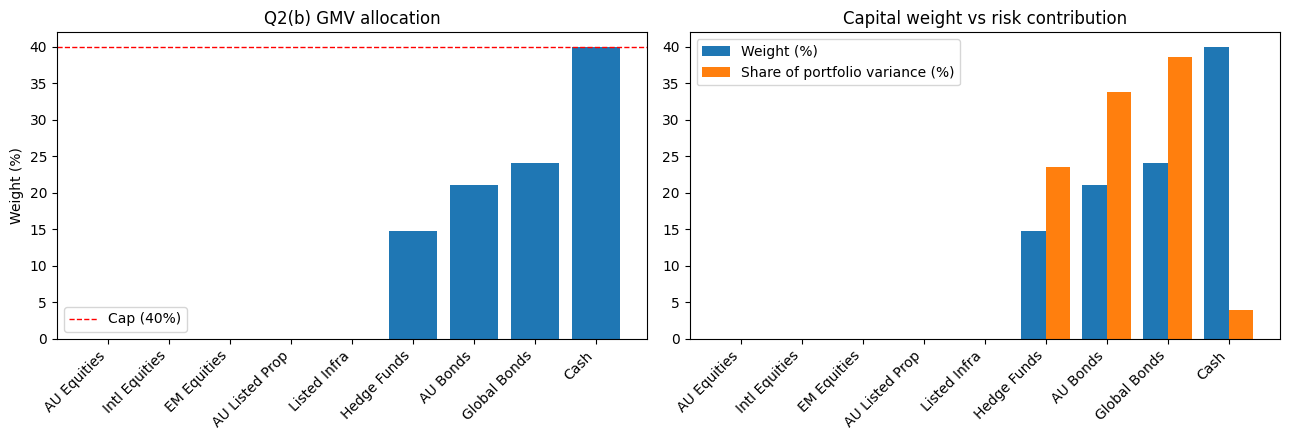

In [ ]:
# ======================================================================
# Q2(b)  Global minimum-variance (GMV) portfolio
#        min x'Cx  s.t.  1'x = 1,  W_MIN <= x_i <= W_MAX
# ======================================================================
w_gmv, info_gmv = solve_portfolio(mu_hat, Sigma_hat, return_info=True, label="GMV")
ret_g, vol_g = port_stats(w_gmv, mu_hat, Sigma_hat)

# ---- allocation table ----
def status(x):
    return "at cap" if x >= W_MAX - TOL_ACTIVE else ("at zero" if x <= W_MIN + TOL_ACTIVE else "interior")

mcr = Sigma_hat @ w_gmv                       # marginal contribution to variance, (Cx)_i
gmv_table = pd.DataFrame({
    "Weight (%)": w_gmv * 100,
    "Constraint": [status(x) for x in w_gmv],
    "Expected return (%)": mu_hat * 100,
    "Volatility (%)": np.sqrt(np.diag(Sigma_hat)) * 100,
    "Risk contribution (%)": w_gmv * mcr / (w_gmv @ mcr) * 100,
}, index=asset_labels).round(2)
display(gmv_table)

print(f"\nGMV portfolio:  expected return = {ret_g:.3%}   volatility = {vol_g:.3%}   "
      f"Sharpe (rf = {rf:.2%}) = {(ret_g - rf) / vol_g:.3f}")

# ---- reference portfolios ----
w_unc = Si @ one / A_                          # GMV with short selling allowed (closed form)
w_eq = np.full(N, 1 / N)
ref = pd.DataFrame({
    "Return (%)":     [ret_g * 100, port_stats(w_unc, mu_hat, Sigma_hat)[0] * 100, port_stats(w_eq, mu_hat, Sigma_hat)[0] * 100],
    "Volatility (%)": [vol_g * 100, port_stats(w_unc, mu_hat, Sigma_hat)[1] * 100, port_stats(w_eq, mu_hat, Sigma_hat)[1] * 100],
}, index=["GMV (long-only, cap)", "GMV (shorting allowed)", "Equal weight"]).round(3)
display(ref)
print("GMV weights with shorting allowed (%):", {k: float(v) for k, v in zip(asset_labels, np.round(w_unc * 100, 1))})
print(f"-> Without the cap the GMV is essentially 100% cash (vol {port_stats(w_unc, mu_hat, Sigma_hat)[1]:.2%}); "
      f"the {W_MAX:.0%} cap on any single asset is what forces the GMV to hold bonds and hedge funds.")

# ---- verification (every line must print PASS) ----
chk = {}
chk["weights sum to 1"] = abs(w_gmv.sum() - 1) < 1e-8
chk["weights within bounds"] = (w_gmv.min() >= W_MIN - 1e-8) and (w_gmv.max() <= W_MAX + 1e-8)
chk[f"exact KKT test (resid {info_gmv['kkt_residual']:.1e})"] = info_gmv["kkt_residual"] < 1e-6
# optimality condition: all 'interior' assets have the same marginal contribution (Cx)_i
free = (w_gmv > W_MIN + TOL_ACTIVE) & (w_gmv < W_MAX - TOL_ACTIVE)
spread = np.ptp(mcr[free]) if free.sum() > 1 else 0.0
chk[f"equal marginal variance on interior assets (spread {spread:.1e})"] = spread < 1e-8
chk["identical to first point of the Q2(a) frontier"] = np.abs(w_gmv - w_gmv_a).max() < 1e-8
# no feasible local perturbation lowers the variance
rng = np.random.default_rng(7); worse_ok = True
for _ in range(5000):
    d = rng.normal(size=N); d -= d.mean(); d *= 0.05 / np.abs(d).max()
    y = w_gmv + d
    if (y >= W_MIN).all() and (y <= W_MAX).all():
        worse_ok &= (y @ Sigma_hat @ y >= w_gmv @ Sigma_hat @ w_gmv - 1e-12)
chk["5000 random feasible perturbations never reduce variance"] = worse_ok
# diversification: GMV is less volatile than every non-cash asset (cash alone is less volatile, but the cap stops 100% cash)
non_cash = [i for i, a in enumerate(assets) if a != "BAUBIL"]
chk["GMV volatility below every non-cash asset"] = vol_g < np.sqrt(np.diag(Sigma_hat))[non_cash].min()
try:
    import cvxpy as cp
    xv = cp.Variable(N)
    cp.Problem(cp.Minimize(cp.quad_form(xv, cp.psd_wrap(Sigma_hat))), [cp.sum(xv) == 1, xv >= W_MIN, xv <= W_MAX]
               ).solve(solver=cp.CLARABEL, tol_gap_abs=1e-13, tol_gap_rel=1e-13, tol_feas=1e-13)
    chk[f"matches cvxpy (max weight diff {np.abs(xv.value - w_gmv).max():.1e})"] = np.abs(xv.value - w_gmv).max() < 1e-6
except ImportError:
    pass
for k, v in chk.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(chk.values()), "Q2(b) verification failed"

# ---- plot ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(asset_labels, w_gmv * 100, color="C0")
ax[0].axhline(W_MAX * 100, color="red", ls="--", lw=1, label=f"Cap ({W_MAX:.0%})")
ax[0].set_ylabel("Weight (%)"); ax[0].set_title("Q2(b) GMV allocation"); ax[0].legend()
plt.setp(ax[0].get_xticklabels(), rotation=45, ha="right")
rc = w_gmv * mcr / (w_gmv @ mcr) * 100
x_pos = np.arange(N)
ax[1].bar(x_pos - 0.2, w_gmv * 100, 0.4, label="Weight (%)")
ax[1].bar(x_pos + 0.2, rc, 0.4, label="Share of portfolio variance (%)")
ax[1].set_xticks(x_pos, asset_labels, rotation=45, ha="right"); ax[1].legend()
ax[1].set_title("Capital weight vs risk contribution")
plt.tight_layout(); plt.show()

**Q2(b) findings**

The global minimum-variance (GMV) portfolio minimises \(x^\top Cx\), subject to \(\mathbf{1}^\top x=1\) and \(0\leq x_i\leq0.4\), using the constraints selected in Q2(a).

| Asset | Weight | Share of portfolio variance |
|---|---:|---:|
| Cash | 40.0% | 3.9% |
| Global Bonds | 24.1% | 38.7% |
| AU Bonds | 21.1% | 33.9% |
| Hedge Funds | 14.7% | 23.6% |
| All other assets | 0% | 0% |

The GMV portfolio has an expected annual return of **3.996%** and volatility of **1.763%**. Its Sharpe ratio is 0.402, using the average cash return of 3.29% as the risk-free rate. The portfolio holds no equities, reflecting its focus on minimising variance rather than maximising returns.

Cash reaches the 40% allocation cap and has the lowest individual volatility (0.56%). The unrestricted GMV has a lower volatility of 0.551%, compared with 1.763% under our chosen constraints, illustrating the cost of restricting the feasible portfolio set.

Capital allocation and risk contribution differ considerably. Cash represents 40% of the portfolio but contributes only 3.9% of its variance, while global bonds account for 24.1% of capital but 38.7% of variance. This shows that portfolio risk depends not only on investment weights but also on asset volatilities and covariances.

## Q2(c) Minimum variance for a range of target returns

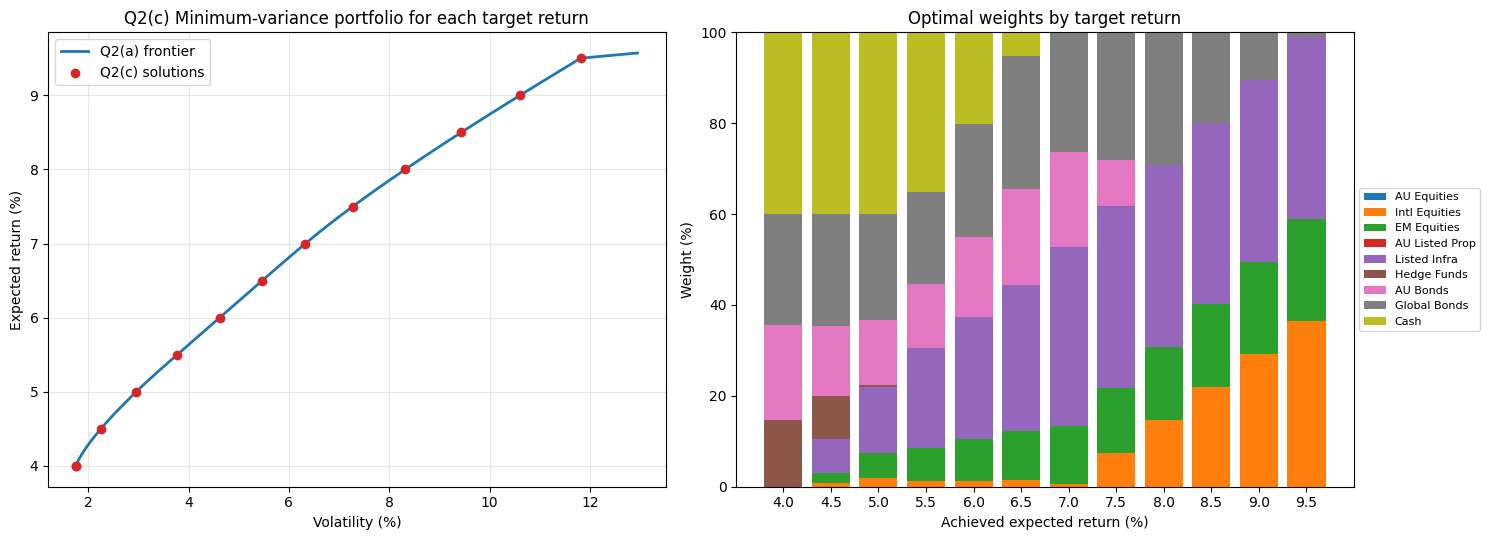

In [ ]:
# ======================================================================
# Q2(c)  Minimum variance for a range of target returns
#        min x'Cx  s.t.  x'm >= mu,  1'x = 1,  W_MIN <= x_i <= W_MAX
# ======================================================================
STEP = 0.005                                                # 0.5% steps in the target return
lo, hi = np.ceil(ret_gmv / STEP) * STEP, np.floor(ret_max / STEP) * STEP
targets = np.concatenate([[ret_gmv - STEP], np.arange(lo, hi + 1e-12, STEP), [ret_max + STEP]])
# first target lies below the GMV return (constraint should not bind); last lies above the maximum attainable return

rows, W_rows = [], []
for t in targets:
    try:
        x, inf = solve_portfolio(mu_hat, Sigma_hat, target=t, return_info=True, label="Q2(c)")
    except ValueError:
        rows.append({"Target (%)": t * 100, "Feasible": False}); W_rows.append(np.full(N, np.nan)); continue
    r, v = port_stats(x, mu_hat, Sigma_hat)
    rows.append({"Target (%)": t * 100, "Feasible": True, "Return (%)": r * 100, "Slack (%)": (r - t) * 100,
                 "Return constraint binds": inf["return_slack"] < 1e-7, "Vol (%)": v * 100,
                 "Sharpe": (r - rf) / v, "Shadow price dVar/dmu": inf["nu"], "KKT resid": inf["kkt_residual"]})
    W_rows.append(x)
res_c = pd.concat([pd.DataFrame(rows), pd.DataFrame(np.array(W_rows) * 100, columns=asset_labels)], axis=1)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(res_c.round(3))

feas = res_c["Feasible"].to_numpy(bool)
Wc = np.array(W_rows)[feas]
rc_ = res_c.loc[feas].reset_index(drop=True)

# ---- verification (every line must print PASS) ----
chk = {}
chk["all weights satisfy sum = 1 and bounds"] = (np.abs(Wc.sum(1) - 1).max() < 1e-8) and Wc.min() >= W_MIN - 1e-8 and Wc.max() <= W_MAX + 1e-8
chk["return target met for every feasible target"] = (rc_["Slack (%)"] > -1e-7).all()
chk["target below GMV return -> constraint slack, solution = GMV"] = (not rc_.loc[0, "Return constraint binds"]) and np.abs(Wc[0] - w_gmv_a).max() < 1e-6
chk["target above max return -> reported infeasible"] = not feas[-1]
chk["constraint binds for all targets above the GMV return"] = rc_["Return constraint binds"].iloc[1:].all()
chk[f"KKT optimality everywhere (max resid {rc_['KKT resid'].max():.1e})"] = rc_["KKT resid"].max() < 1e-6
# '>=' and '=' formulations coincide above the GMV return
eq_diff = max(np.abs(solve_portfolio(mu_hat, Sigma_hat, target=t, equality=True) - Wc[k + 1]).max()
              for k, t in enumerate(targets[feas][1:]))
chk[f"'>=' and '=' give identical portfolios (max diff {eq_diff:.1e})"] = eq_diff < 1e-6
# consistency with the Q2(a) frontier (interpolated on its 80-point grid)
fv = np.interp(rc_["Return (%)"].iloc[1:] / 100, frontier["ret"], frontier["vol"]) * 100
diff_f = np.abs(fv - rc_["Vol (%)"].iloc[1:]).max()
chk[f"lies on the Q2(a) frontier (max vol diff {diff_f:.1e} pp)"] = diff_f < 1e-2
# shadow price must equal the local slope of variance vs return
k = len(Wc) // 2; t0 = targets[feas][k]; h = 1e-5
slope = (port_stats(solve_portfolio(mu_hat, Sigma_hat, target=t0 + h), mu_hat, Sigma_hat)[1] ** 2 -
         port_stats(solve_portfolio(mu_hat, Sigma_hat, target=t0 - h), mu_hat, Sigma_hat)[1] ** 2) / (2 * h)
chk[f"shadow price = finite-difference slope ({rc_.loc[k, 'Shadow price dVar/dmu']:.4f} vs {slope:.4f})"] = abs(rc_.loc[k, "Shadow price dVar/dmu"] - slope) < 1e-3
for kk, v in chk.items():
    print(("PASS  " if v else "FAIL  ") + kk)
assert all(chk.values()), "Q2(c) verification failed"

# ---- plot ----
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].plot(frontier["vol"] * 100, frontier["ret"] * 100, color="C0", lw=2, label="Q2(a) frontier")
ax[0].scatter(rc_["Vol (%)"], rc_["Return (%)"], color="C3", zorder=3, label="Q2(c) solutions")
ax[0].set_xlabel("Volatility (%)"); ax[0].set_ylabel("Expected return (%)"); ax[0].grid(alpha=0.3)
ax[0].set_title("Q2(c) Minimum-variance portfolio for each target return"); ax[0].legend()
bottom = np.zeros(len(rc_)); xlab = [f"{t:.1f}" for t in rc_["Return (%)"]]
for j, lab in enumerate(asset_labels):
    ax[1].bar(xlab, Wc[:, j] * 100, bottom=bottom, label=lab); bottom += Wc[:, j] * 100
ax[1].set_xlabel("Achieved expected return (%)"); ax[1].set_ylabel("Weight (%)")
ax[1].set_title("Optimal weights by target return"); ax[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

**Q2(c) findings**

We solve the problem

$$\min_x \; x^\top C x \quad \text{subject to} \quad x^\top m \ge \mu, \;\; \mathbf{1}^\top x = 1, \;\; 0 \le x_i \le 0.4$$

for target returns from 4.0% to 9.5%, in steps of 0.5 percentage points, and also test targets outside the efficient return range. Some of the results are in the table below. The weights are in %, and the other assets have zero weight.

| Target | Volatility | Sharpe | Cash | Global bonds | AU bonds | Infra | EM equities | Intl equities | Hedge funds |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 4.0% | 1.76% | 0.40 | 40.0 | 24.3 | 20.7 | 0 | 0 | 0 | 15.0 |
| 5.0% | 2.96% | 0.58 | 40.0 | 23.3 | 14.4 | 14.5 | 5.3 | 2.0 | 0.5 |
| 6.0% | 4.62% | 0.59 | 20.2 | 24.8 | 17.6 | 27.0 | 9.1 | 1.4 | 0 |
| 7.0% | 6.33% | 0.59 | 0 | 26.3 | 20.8 | 39.5 | 12.7 | 0.6 | 0 |
| 8.0% | 8.32% | 0.57 | 0 | 29.3 | 0 | 40.0 | 16.0 | 14.7 | 0 |
| 9.0% | 10.60% | 0.54 | 0 | 10.5 | 0 | 40.0 | 20.4 | 29.1 | 0 |
| 9.5% | 11.81% | 0.53 | 0 | 1.1 | 0 | 40.0 | 22.6 | 36.4 | 0 |

For every target above 4.00% the return constraint is tight, so the portfolio earns exactly the target. If the target is below the GMV return, the constraint does not matter and we get the GMV portfolio. If the target is above 9.57% (for example 10.07%), no portfolio satisfies the constraints. Using $x^\top m = \mu$ instead of $x^\top m \ge \mu$ gives the same portfolios.

When the target return goes up, the portfolio moves out of cash and bonds into infrastructure, then EM and international equities. The Sharpe ratio is almost flat at about 0.58 to 0.59 for targets between 5% and 7%, and then falls.

The shadow price in our output is the Lagrange multiplier of the return constraint, as in the Lagrangian method of Lecture 14. It tells us how much the minimum variance goes up if we ask for one more unit of return. It rises from about 0.06 (target 4.5%) to 0.58 (target 9.5%). For example, going from a 6% target to a 7% target raises the variance from 0.0021 to 0.0040. So extra return is much more expensive in risk at the top of the frontier.

## Q2(d) Sensitivity to the parameter estimates

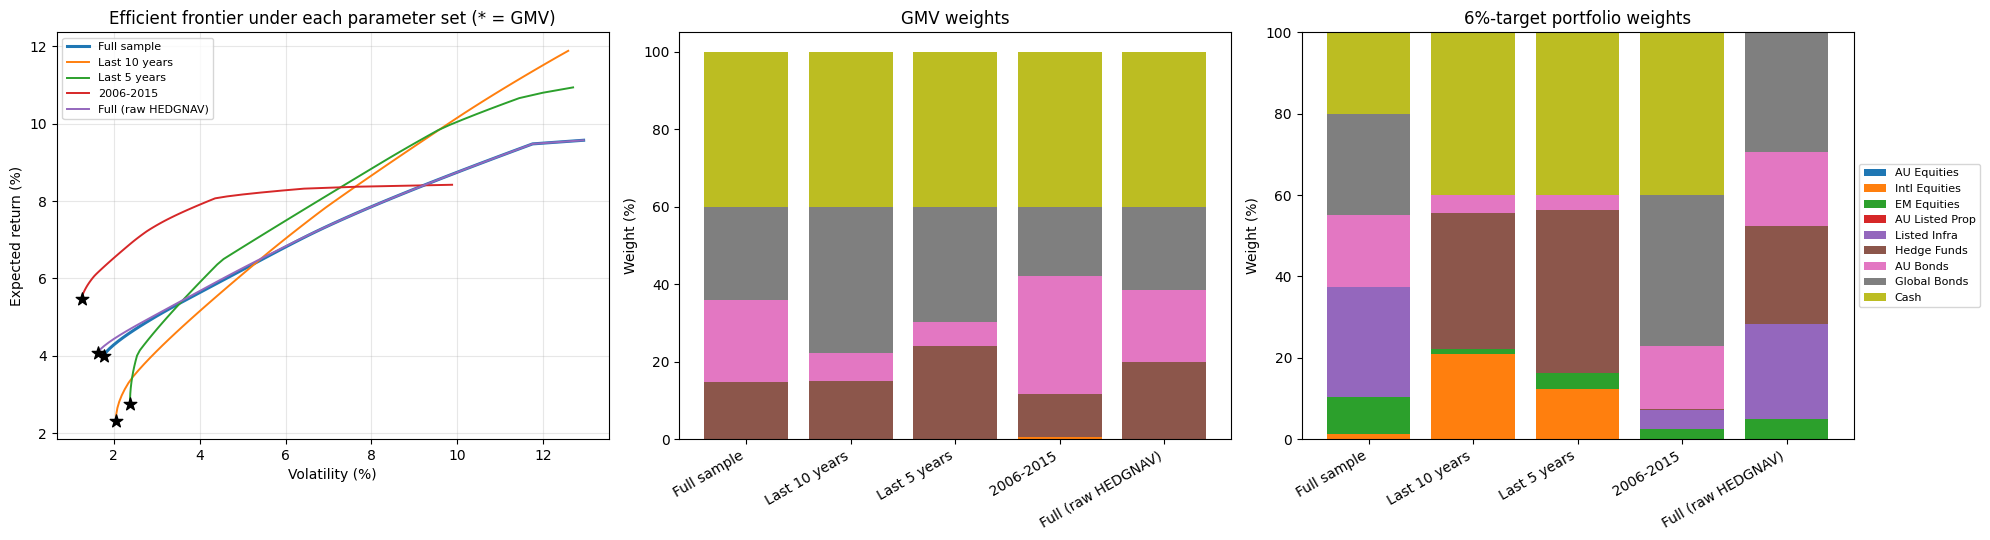

In [ ]:
# ======================================================================
# Q2(d)  Sensitivity of the optimal portfolios to the parameter estimates
# ======================================================================
# ---- 1. Parameter sets from Q1(e), plus one extra: full sample WITHOUT desmoothing HEDGNAV ----
sets = {name: to_arrays(est["m"], est["C"]) for name, est in parameter_sets.items()}
sets["Full (raw HEDGNAV)"] = to_arrays(monthly_returns.mean() * 12, monthly_returns.cov() * 12)
names = list(sets)
assert np.allclose(sets["Full sample"][0], mu_hat) and np.allclose(sets["Full sample"][1], Sigma_hat), "Full sample must equal Q2(a) inputs"
TARGET = 0.06            # common target return used for the comparison (6% p.a.)

def half_l1(a, b): return 0.5 * np.abs(a - b).sum()          # share of the portfolio that has to be traded

# ---- 2. GMV, target-return portfolio and frontier under every parameter set ----
gmv_w, tgt_w, fronts = {}, {}, {}
for nm, (mu_, S_) in sets.items():
    gmv_w[nm] = solve_portfolio(mu_, S_, label=nm + " GMV")
    tgt_w[nm] = solve_portfolio(mu_, S_, target=TARGET, label=nm + " target")
    fronts[nm] = efficient_frontier(mu_, S_, n_points=60)

summ = pd.DataFrame({nm: {
    "GMV return (%)": port_stats(gmv_w[nm], *sets[nm])[0] * 100, "GMV vol (%)": port_stats(gmv_w[nm], *sets[nm])[1] * 100,
    f"{TARGET:.0%}-target vol (%)": port_stats(tgt_w[nm], *sets[nm])[1] * 100,
    "Max attainable return (%)": fronts[nm]["ret"].iloc[-1] * 100,
    "Half-L1 distance of GMV to Full": half_l1(gmv_w[nm], gmv_w["Full sample"]) * 100,
    f"Half-L1 distance of {TARGET:.0%}-portfolio to Full": half_l1(tgt_w[nm], tgt_w["Full sample"]) * 100,
} for nm in names}).T.round(2)
print("Summary (each set evaluated under its OWN parameters; half-L1 = % of portfolio that must be traded):")
display(summ)
print("GMV weights (%):");                 display(pd.DataFrame(gmv_w, index=asset_labels).mul(100).round(1))
print(f"Weights of the {TARGET:.0%}-target-return portfolio (%):"); display(pd.DataFrame(tgt_w, index=asset_labels).mul(100).round(1))

# ---- 3. Cross-evaluation: portfolio optimal under set A, judged with the parameters of set B ----
vol_cross = pd.DataFrame({B: {A: port_stats(gmv_w[A], *sets[B])[1] * 100 for A in names} for B in names})
vol_cross.index.name = "GMV built with (row) / judged with (col)"
print("Volatility (%) of each GMV portfolio under each parameter set (diagonal = own optimum; column minimum is on the diagonal):")
display(vol_cross.round(2))
ret_cross = pd.DataFrame({B: {A: port_stats(tgt_w[A], *sets[B])[0] * 100 for A in names} for B in names})
ret_cross.index.name = f"{TARGET:.0%}-portfolio built with (row) / judged with (col)"
print(f"Expected return (%) of each {TARGET:.0%}-target portfolio under each parameter set (diagonal = {TARGET:.0%}):")
display(ret_cross.round(2))

# ---- 4. Which input drives the changes: m or C? (weights of the 6% portfolio, vs Full sample) ----
rows = []
for nm in names:
    if nm == "Full sample": continue
    out = {"Set": nm}
    for lab, (mm, SS) in {"only m changed": (sets[nm][0], Sigma_hat), "only C changed": (mu_hat, sets[nm][1]), "both changed": sets[nm]}.items():
        try:
            out[lab] = half_l1(solve_portfolio(mm, SS, target=TARGET), tgt_w["Full sample"]) * 100
        except ValueError:
            out[lab] = np.nan                                 # target not attainable with these means
    out["GMV (depends on C only)"] = half_l1(gmv_w[nm], gmv_w["Full sample"]) * 100
    rows.append(out)
print(f"Half-L1 distance (%) from the Full-sample {TARGET:.0%}-portfolio when only one input is swapped:")
display(pd.DataFrame(rows).set_index("Set").round(1))

# ---- 5. Pure estimation noise: redraw the mean vector within its sampling error, keep C fixed ----
n_draws = 300
rng = np.random.default_rng(2024)
years_ = len(est_returns) / 12
m_draws = rng.multivariate_normal(mu_hat, Sigma_hat / years_, size=n_draws)      # Cov(m_hat) = C / years
W_list = []
for md in m_draws:
    try:
        W_list.append(solve_portfolio(md, Sigma_hat, target=TARGET))
    except ValueError:                       # in this draw no feasible portfolio reaches the target return
        pass
W_noise = np.array(W_list)
n_skipped = n_draws - len(W_noise)
base = tgt_w["Full sample"]
noise_tab = pd.DataFrame({"Base weight (%)": base * 100, "Mean over draws (%)": W_noise.mean(0) * 100,
                          "Std over draws (%)": W_noise.std(0) * 100,
                          "5th pct (%)": np.percentile(W_noise, 5, axis=0) * 100,
                          "95th pct (%)": np.percentile(W_noise, 95, axis=0) * 100}, index=asset_labels).round(1)
print(f"Sampling noise in m only ({len(W_noise)} usable draws of {n_draws}, m ~ N(m_hat, C/years)) -> {TARGET:.0%}-target portfolio weights"
      f" ({n_skipped} draws skipped: target unattainable):")
display(noise_tab)
print(f"Average half-L1 distance to the base portfolio: {np.mean([half_l1(w, base) for w in W_noise]) * 100:.1f}%   "
      f"(GMV does not use m, so it is unaffected by this noise)")

# ---- 6. Verification ----
chk = {}
chk["every portfolio satisfies sum = 1 and bounds"] = all(
    abs(w.sum() - 1) < 1e-8 and w.min() >= W_MIN - 1e-8 and w.max() <= W_MAX + 1e-8
    for w in list(gmv_w.values()) + list(tgt_w.values()) + list(W_noise))
chk["each GMV is optimal under its own C (diagonal is column minimum)"] = all(
    vol_cross[B].min() >= vol_cross.loc[B, B] - 1e-6 for B in names)
chk["each target portfolio earns exactly the target under own m"] = all(abs(ret_cross.loc[A, A] - TARGET * 100) < 1e-4 for A in names)
chk["GMV unchanged when only m changes (m is not an input)"] = all(
    np.abs(solve_portfolio(sets[nm][0], Sigma_hat) - gmv_w["Full sample"]).max() < 1e-6 for nm in names)
chk["all four Q1(e) sets + raw-HEDGNAV set solved"] = len(names) == 5
for k, v in chk.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(chk.values()), "Q2(d) verification failed"

# ---- 7. Plots ----
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
for nm in names:
    ax[0].plot(fronts[nm]["vol"] * 100, fronts[nm]["ret"] * 100, lw=2.2 if nm == "Full sample" else 1.4, label=nm)
    ax[0].scatter(port_stats(gmv_w[nm], *sets[nm])[1] * 100, port_stats(gmv_w[nm], *sets[nm])[0] * 100, marker="*", s=90, color="k", zorder=4)
ax[0].set_xlabel("Volatility (%)"); ax[0].set_ylabel("Expected return (%)"); ax[0].grid(alpha=0.3)
ax[0].set_title("Efficient frontier under each parameter set (* = GMV)"); ax[0].legend(fontsize=8)
for a_, W_, ttl in [(ax[1], gmv_w, "GMV weights"), (ax[2], tgt_w, f"{TARGET:.0%}-target portfolio weights")]:
    bottom = np.zeros(len(names))
    for j, lab in enumerate(asset_labels):
        vals = np.array([W_[nm][j] * 100 for nm in names]); a_.bar(range(len(names)), vals, bottom=bottom, label=lab); bottom += vals
    a_.set_xticks(range(len(names)), names, rotation=30, ha="right"); a_.set_ylabel("Weight (%)"); a_.set_title(ttl)
ax[2].legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

**Q2(d) findings**

We repeat the optimisation using the estimates from Q1(e): the full sample, the last 10 years, the last 5 years and 2006 to 2015. We also add one more case, the full sample without desmoothing the hedge fund returns. We compare the global minimum-variance (GMV) portfolio and a 6% target-return portfolio. The GMV depends only on the covariance matrix \(C\), while the 6% portfolio depends on both expected returns \(m\) and \(C\). This allows us to compare their sensitivity to parameter estimation. We choose 6% as a common target because it is above the full-sample GMV return, attainable under all five parameter sets, and provides a meaningful comparison without focusing on the extreme upper end of the efficient frontier.

To measure how different two portfolios are, we use $D = \tfrac{1}{2}\sum_i |x_i - y_i|$. This is the share of the portfolio we would have to trade to move from one to the other.

| Estimate | D for GMV | D for 6% portfolio |
|---|---:|---:|
| Last 10 years | 14% | 73% |
| Last 5 years | 15% | 71% |
| 2006 to 2015 | 10% | 32% |
| Full sample, raw hedge funds | 5% | 29% |

(D is measured against the full-sample portfolio.)

**The optimal portfolios change a lot with the estimates.** The 6% portfolio from the full sample is very different from the ones using the last 10 or 5 years. The recent samples buy more hedge funds and international equities, buy no infrastructure and keep cash at 40%. Even desmoothing the hedge fund returns or not changes the portfolio by about 29%.

**The expected returns matter more than the covariance matrix.** For the three other sample periods, changing only $m$ moves the 6% portfolio by 39% to 74%, while changing only $C$ moves it by 25% to 52%. This only applies to our experiment. It matches Q1(e), where the expected returns were the least stable estimates.

**Estimation error alone is enough to change the portfolio.** We drew 300 new mean vectors from $N(m, C/T)$, where $T = 20.7$ years is the length of our sample, and kept $C$ fixed. In 278 draws the 6% target could be reached. The 6% portfolio moved by about 40% on average. The weight of infrastructure, for example, ranged from 0% to 40% between the 5th and 95th percentiles.

**The GMV portfolio is more stable** because it uses only $C$. It is always made of cash, bonds and hedge funds. But it still changes: in the last 10 and 5 years it holds more global bonds and fewer AU bonds, because the correlations changed.

**Portfolios do not carry over to other periods.** The 6% portfolio built with 2006 to 2015 data has an expected return of only 2.2% under the last 10 years' means and 1.7% under the last 5 years' means. The full-sample 6% portfolio has an expected return of 3.5% under the last 5 years' means.

In summary, estimation error is a big problem for mean-variance optimisation, mainly because of the expected returns. This is why we use a bootstrap in Q4(c) and out-of-sample tests in Q5 and Q6.

# Q3 Strategic asset allocation
## Growth/defensive classification



**Classification.** We follow Table 4 of APRA's MySuper Heatmap methodology paper (APRA, 2021). Listed equities, listed property and listed infrastructure are 100% growth, and fixed interest and cash are 100% defensive. So AU, international and EM equities, AU listed property and listed infrastructure are growth assets, and AU bonds, global bonds and cash are defensive. APRA's table has no separate line for hedge funds, so we put them in its "other" category, which is 50% growth and 50% defensive. The growth exposure of a portfolio is then $g^\top x$, where $g$ holds the growth shares above.

## Q3(a) Minimum-variance portfolio for each allocation

In [ ]:
# ======================================================================
# Q3(a) Strategic Asset Allocation:
# Defensive / Balanced / Aggressive portfolios
# ======================================================================

# APRA MySuper Heatmap growth/defensive classification
# Growth exposure:
# Equities, listed property, listed infrastructure = 100% Growth
# Hedge funds / alternatives = 50% Growth
# Fixed interest and cash = 100% Defensive

growth_exposure = pd.Series({
    "ASA52":     1.00,   # AU Equities
    "NDDLWI":    1.00,   # International Equities
    "NDLEEGF":   1.00,   # Emerging Market Equities
    "RDAU":      1.00,   # AU Listed Property
    "FDCIISAH":  1.00,   # Listed Infrastructure
    "HEDGNAV":   0.50,   # Hedge Funds / Alternatives
    "BACM0":     0.00,   # AU Bonds
    "H03432AU":  0.00,   # Global Bonds
    "BAUBIL":    0.00    # Cash
}).reindex(assets)

defensive_exposure = 1 - growth_exposure

classification = pd.DataFrame({
    "Asset": [LABEL[a] for a in assets],
    "Growth (%)": growth_exposure * 100,
    "Defensive (%)": defensive_exposure * 100
}, index=assets)

display(classification)

In [ ]:
# Growth allocation targets required by Q3
saa_targets = {
    "Defensive": 0.30,
    "Balanced":  0.70,
    "Aggressive": 0.90
}

g = growth_exposure.to_numpy(dtype=float)

q3_weights = {}
q3_results = []

for name, growth_target in saa_targets.items():

    # min x'C x
    # s.t.
    # 1'x = 1
    # g'x = growth_target
    # 0 <= x_i <= 0.40
    w = solve_portfolio(
        mu_hat,
        Sigma_hat,
        A_eq=g,
        b_eq=growth_target,
        label=f"Q3 {name}"
    )

    q3_weights[name] = w

    ret, vol = port_stats(
        w,
        mu_hat,
        Sigma_hat
    )

    sharpe = (ret - rf) / vol

    q3_results.append({
        "Portfolio": name,
        "Growth (%)": g @ w * 100,
        "Defensive (%)": (1 - g) @ w * 100,
        "Expected return (%)": ret * 100,
        "Volatility (%)": vol * 100,
        "Sharpe ratio": sharpe
    })


q3_summary = pd.DataFrame(q3_results).set_index("Portfolio")

print("Q3(a) portfolio summary:")
display(q3_summary.round(3))

q3_weight_table = pd.DataFrame(
    q3_weights,
    index=asset_labels
) * 100

print("Q3(a) portfolio weights (%):")
display(q3_weight_table.round(2))

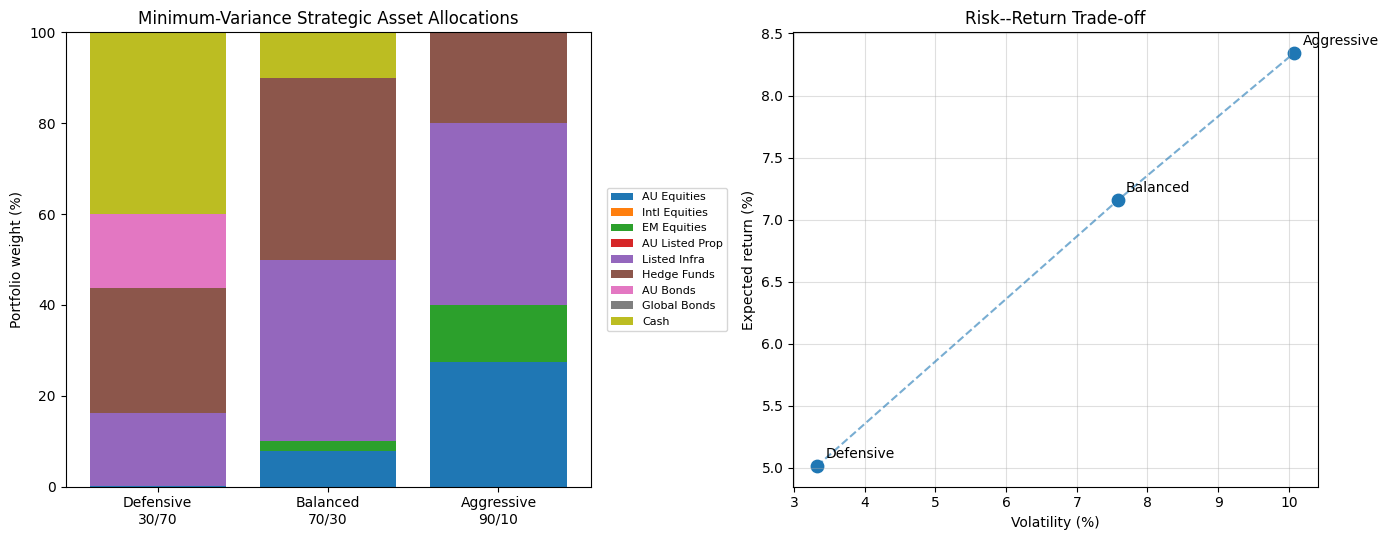

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -------- data for right-hand plot --------
portfolios = ["Defensive", "Balanced", "Aggressive"]
vols = q3_summary.loc[portfolios, "Volatility (%)"].values
rets = q3_summary.loc[portfolios, "Expected return (%)"].values

# -------- create side-by-side figure --------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# =========================
# Left panel: stacked bar
# =========================
ax = axes[0]
bottom = np.zeros(3)

for j, asset in enumerate(asset_labels):
    vals = np.array([
        q3_weights["Defensive"][j],
        q3_weights["Balanced"][j],
        q3_weights["Aggressive"][j]
    ]) * 100

    ax.bar(
        ["Defensive\n30/70",
         "Balanced\n70/30",
         "Aggressive\n90/10"],
        vals,
        bottom=bottom,
        label=asset
    )
    bottom += vals

ax.set_ylabel("Portfolio weight (%)")
ax.set_title("Minimum-Variance Strategic Asset Allocations")

# =========================
# Right panel: risk-return scatter
# =========================
ax = axes[1]

ax.scatter(vols, rets, s=80)

for i, name in enumerate(portfolios):
    ax.annotate(
        name,
        (vols[i], rets[i]),
        textcoords="offset points",
        xytext=(6, 6)
    )

ax.plot(vols, rets, linestyle="--", alpha=0.6)
ax.set_xlabel("Volatility (%)")
ax.set_ylabel("Expected return (%)")
ax.set_title("Risk--Return Trade-off")
ax.grid(True, alpha=0.4)

# legend only for left plot
axes[0].legend(
    fontsize=8,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.show()

**Q3(a) findings**

Under the common 40% individual-asset cap, the minimum-variance portfolios exhibit a clear risk–return trade-off as the required growth exposure increases. The defensive portfolio has an expected return of 5.01% and volatility of 3.32%, compared with 7.16% and 7.58% for the balanced portfolio and 8.34% and 10.08% for the aggressive portfolio. Higher growth exposure therefore raises expected return but also substantially increases portfolio risk. The Sharpe ratio declines slightly from 0.519 for the defensive portfolio to 0.502 for the aggressive portfolio, indicating that the additional expected return is not accompanied by an improvement in risk-adjusted performance over the sample considered.

For the Sharpe ratio we use the average cash return over the sample, 3.29%, as the risk-free rate, the same as in Q2. Cash is one of our nine assets and is the closest thing in the data to a riskless investment for an Australian fund, so its own average return is the natural benchmark.

## Q3(b) Diversification benefits

In [ ]:
# optional (reach 40% upper bound)
for name, w in q3_weights.items():
    print(f"\n{name}")

    for asset, weight in zip(asset_labels, w):
        if weight > 1e-4:
            flag = " <- upper bound" if np.isclose(weight, 0.40, atol=1e-4) else ""
            print(f"{asset:25s}: {weight:7.2%}{flag}")

In [ ]:
# ======================================================================
# Q3(b)  Diversification benefits and the cost of the growth/defensive constraint
# ======================================================================
vol_i = np.sqrt(np.diag(Sigma_hat))
g_q3 = growth_exposure.reindex(assets).to_numpy(dtype=float)
g_hf100 = g_q3.copy(); g_hf100[assets.index("HEDGNAV")] = 1.0   # alternative: hedge funds counted as 100% growth

div_rows, chk, kkt = [], {}, []
for name, w in q3_weights.items():
    ret, vol = port_stats(w, mu_hat, Sigma_hat)
    _, inf = solve_portfolio(mu_hat, Sigma_hat, A_eq=g_q3, b_eq=saa_targets[name], return_info=True)
    kkt.append(inf["kkt_residual"])
    # 1. same growth target using only AU equities (growth) and AU bonds (defensive)
    w_two = np.zeros(N)
    w_two[assets.index("ASA52")] = saa_targets[name]
    w_two[assets.index("BACM0")] = 1 - saa_targets[name]
    ret_two, vol_two = port_stats(w_two, mu_hat, Sigma_hat)
    # 2. efficient portfolio with the same expected return (Q2(c) problem, no growth constraint)
    vol_front = port_stats(solve_portfolio(mu_hat, Sigma_hat, target=ret - 1e-10), mu_hat, Sigma_hat)[1]
    # 3. same growth target, but hedge funds counted as 100% growth
    w_alt = solve_portfolio(mu_hat, Sigma_hat, A_eq=g_hf100, b_eq=saa_targets[name])
    ret_alt, vol_alt = port_stats(w_alt, mu_hat, Sigma_hat)
    div_rows.append({
        "Portfolio": name,
        "Volatility (%)": vol * 100,
        "Weighted avg of asset vols (%)": (w @ vol_i) * 100,
        "Diversification ratio": (w @ vol_i) / vol,
        "AU eq + AU bonds: return (%)": ret_two * 100,
        "AU eq + AU bonds: vol (%)": vol_two * 100,
        "Frontier vol at same return (%)": vol_front * 100,
        "Sharpe on frontier": (ret - rf) / vol_front,
        "HF as 100% growth: return (%)": ret_alt * 100,
        "HF as 100% growth: vol (%)": vol_alt * 100,
        "HF as 100% growth: HF weight (%)": w_alt[assets.index("HEDGNAV")] * 100,
    })
q3_div = pd.DataFrame(div_rows).set_index("Portfolio")
display(q3_div.round(2))

# ---- verification (every line must print PASS) ----
W3 = np.array(list(q3_weights.values()))
chk["weights sum to 1 and respect the 0-40% bounds"] = (np.abs(W3.sum(1) - 1).max() < 1e-8) and W3.min() >= W_MIN - 1e-8 and W3.max() <= W_MAX + 1e-8
chk["growth exposure equals the target exactly"] = all(abs(g_q3 @ q3_weights[n] - saa_targets[n]) < 1e-8 for n in q3_weights)
chk[f"KKT optimality for all three portfolios (max resid {max(kkt):.1e})"] = max(kkt) < 1e-6
chk["portfolio vol is below the weighted average of asset vols (diversification)"] = (q3_div["Diversification ratio"] > 1).all()
chk["each SAA lies on or inside the Q2 frontier (growth constraint can only add risk)"] = (q3_div["Volatility (%)"] >= q3_div["Frontier vol at same return (%)"] - 1e-6).all()
for k, v in chk.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(chk.values()), "Q3 verification failed"

**Q3(b) findings**

The portfolio allocations demonstrate clear diversification benefits across asset classes. The optimiser does not satisfy higher growth targets solely through equities, but also assigns substantial weights to listed infrastructure and hedge funds. This reflects the importance of covariance as well as individual asset volatility in determining portfolio risk. Fixed-income assets and cash play a larger risk-reduction role in the defensive allocation, while equities become increasingly important as the growth constraint is tightened. The 40% asset cap is binding in several cases, preventing the minimum-variance solutions from becoming excessively concentrated in a small number of assets.

The table above puts numbers on this.

* **Portfolio risk is well below the average risk of the assets held.** The defensive portfolio holds assets whose volatilities average 4.51% (weighted by the portfolio weights), but its own volatility is only 3.32%. The ratio of the two is 1.36 for the defensive portfolio and 1.15 to 1.16 for the other two. The reduction comes from correlations below one, so the asset risks partly offset in $x^\top C x$.
* **More asset classes give less risk for the same growth exposure.** A simple fund holding only AU equities for growth and AU bonds for defensive has volatility 4.96%, 9.75% and 12.44% at the three growth levels, against 3.32%, 7.58% and 10.07% for our portfolios. Its Sharpe ratios are only 0.36 to 0.40. In the balanced and aggressive cases our portfolios also have the higher expected return.
* **Fixing the growth/defensive split has a cost.** For the same expected return, the Q2 frontier portfolio has 0.34, 0.97 and 1.00 percentage points less volatility, with Sharpe ratios of 0.58, 0.59 and 0.56, against a maximum of 0.587 in Q2(a).
* **The result depends on how hedge funds are classified.** Hedge funds are strongly correlated with equities (0.70 to 0.78), so the 50/50 split is a convention rather than something the data confirm. If we count them as 100% growth, the optimiser holds 30% to 40% hedge funds and every portfolio becomes much less risky. The aggressive portfolio then becomes essentially our balanced portfolio (return 7.2%, volatility 7.6%). So two funds with the same growth/defensive label can carry quite different risk, depending on how they classify alternatives.

## Q3(c) Comparing the three allocations

**Q3(c) findings**

The defensive portfolio is most appropriate when capital preservation and low volatility are priorities, while the aggressive portfolio is more suitable for investors with long horizons and greater tolerance for short-term fluctuations. The balanced allocation provides an intermediate compromise between expected return and risk. In particular, moving from the balanced to the aggressive allocation raises expected return from 7.16% to 8.34%, but volatility increases from 7.58% to 10.08%, resulting in a slightly lower Sharpe ratio. The appropriate strategic allocation therefore depends primarily on the fund's investment horizon, risk tolerance and required return rather than on expected return alone.

We can look at the choice from several angles.

* **Risk-adjusted return does not decide it.** The three Sharpe ratios are almost the same (0.50 to 0.52), so no allocation is better on a risk-adjusted basis. The choice depends on the fund's members.
* **Member horizon and cash needs.** The defensive allocation suits members close to or in retirement, or a fund that must pay out money soon, because a large loss would be hard to recover before the money is needed. Its cost is an expected return only 1.7 percentage points above cash (5.01% against 3.29%). The balanced allocation suits a broad group of members with long horizons who still want some protection in bad years. The aggressive allocation suits young members who will not draw on their savings for decades, and funds with strong cash inflows, because they can wait out falls.
* **Out-of-sample evidence.** Q5 shows that the risk of the aggressive allocation is real. The aggressive portfolio built in December 2021 lost 2.2% over 2022 and 2023, while the defensive one gained 2.8%. For the portfolios built in December 2018, the aggressive portfolio's realised volatility was 15.5% against a prediction of 7.9%. An investor choosing the aggressive allocation must be able to accept risk larger than the model predicts.
* **Risk aversion.** In Q4(a) the growth exposure of the optimal portfolio falls as $\gamma$ rises (risk tolerance $t = 1/\gamma$): it is 100% at $\gamma = 3$, 75.9% at $\gamma = 5$, 61.1% at $\gamma = 7$ and 32.0% at $\gamma = 15$. The aggressive allocation therefore fits an investor with $\gamma$ between 3 and 5, the balanced allocation $\gamma$ between 5 and 7, and the defensive allocation $\gamma$ around 15.
* **The label is not the whole story.** Q3(b) shows that the risk of each allocation depends on how hedge funds are classified, so a fund should look at the actual volatility of an allocation and not only at its growth/defensive label.

Overall, there is no single best allocation: the right choice is the one whose risk matches the members' horizon and risk tolerance.

# Q4 Utility and Monte Carlo optimisation
## Q4(a) Optimal portfolios for different levels of risk aversion

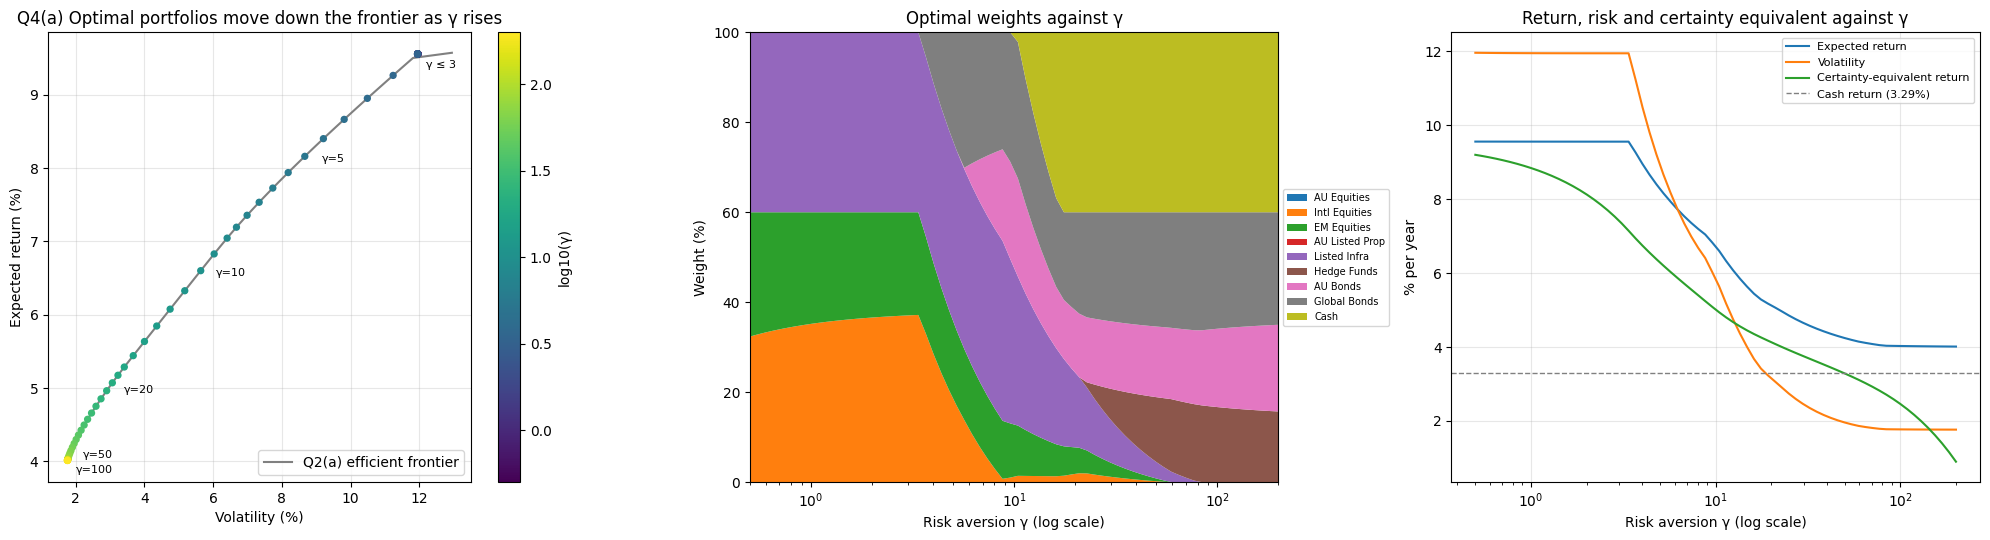

In [ ]:
# ======================================================================
# Q4(a)  Mean-variance (CARA-normal) optimal portfolios for several gamma
#        max_x  x'm - (gamma/2) x'Cx   s.t.  1'x = 1,  W_MIN <= x_i <= W_MAX   (same constraints as Q2)
# ======================================================================
# With W0 = 1, U(W) = -exp(-gamma W) and R ~ N(m, C):
#   E[U(W1)] = -exp(-gamma (1 + x'm) + gamma^2/2 x'Cx)
# so maximising E[U] <=> maximising the certainty-equivalent return  CE(x) = x'm - gamma/2 x'Cx.

def ce_return(x, mu, Sg, gamma):
    """Certainty-equivalent return of portfolio x under the normal model (exact)."""
    return float(mu @ x - 0.5 * gamma * x @ Sg @ x)

def expected_utility_exact(x, mu, Sg, gamma):
    """E[-exp(-gamma W1)] with W1 = 1 + x'R, R ~ N(mu, Sg) (closed form)."""
    return float(-np.exp(-gamma * (1 + mu @ x) + 0.5 * gamma ** 2 * x @ Sg @ x))

# ---- 1. Optimal portfolio for a range of risk-aversion levels ----
GAMMAS = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100]
opt_a, info_a = {}, {}
for g in GAMMAS:
    opt_a[g], info_a[g] = solve_portfolio(mu_hat, Sigma_hat, gamma=g, return_info=True, label=f"gamma={g}")

rows = []
for g in GAMMAS:
    x = opt_a[g]
    r, v = port_stats(x, mu_hat, Sigma_hat)
    rows.append({"gamma": g, "Expected return (%)": r * 100, "Volatility (%)": v * 100,
                 "CE return (%)": ce_return(x, mu_hat, Sigma_hat, g) * 100,
                 "Sharpe": (r - rf) / v,
                 "Growth exposure, APRA (%)": growth_exposure.reindex(assets).to_numpy(dtype=float) @ x * 100,
                 "Assets held": int((x > 1e-4).sum())})
res_a = pd.concat([pd.DataFrame(rows),
                   pd.DataFrame([opt_a[g] * 100 for g in GAMMAS], columns=asset_labels)], axis=1).set_index("gamma")
print("Optimal portfolio for each gamma (weights in %):")
display(res_a.round(2))

# ---- 2. Smooth path over gamma (for the plots) ----
gamma_grid = np.geomspace(0.5, 200, 70)
path_W = np.array([solve_portfolio(mu_hat, Sigma_hat, gamma=g) for g in gamma_grid])
path_stats = np.array([port_stats(x, mu_hat, Sigma_hat) for x in path_W])

# gamma above which the optimum is (almost) the GMV portfolio, and below which it is (almost) the max-return portfolio
dist_gmv = np.array([0.5 * np.abs(x - w_gmv_a).sum() for x in path_W])
x_maxret = max_return_portfolio(mu_hat)
print(f"Half-L1 distance to the GMV portfolio: {dist_gmv[gamma_grid >= 100][0]:.1%} at gamma = 100, "
      f"{dist_gmv[-1]:.1%} at gamma = {gamma_grid[-1]:.0f}")

# ---- 3. Verification (every line must print PASS) ----
chk = {}
W_a = np.array([opt_a[g] for g in GAMMAS])
chk["weights sum to 1 and respect the bounds"] = (np.abs(W_a.sum(1) - 1).max() < 1e-8) and W_a.min() >= W_MIN - 1e-8 and W_a.max() <= W_MAX + 1e-8
chk[f"KKT optimality for every gamma (max resid {max(i['kkt_residual'] for i in info_a.values()):.1e})"] = \
    max(i["kkt_residual"] for i in info_a.values()) < 1e-6
# (i) each optimum is efficient: no portfolio with the same expected return has lower volatility (exact Q2(c) solve)
gap = max(port_stats(opt_a[g], mu_hat, Sigma_hat)[1]
          - port_stats(solve_portfolio(mu_hat, Sigma_hat, target=port_stats(opt_a[g], mu_hat, Sigma_hat)[0] - 1e-12), mu_hat, Sigma_hat)[1]
          for g in GAMMAS)
chk[f"every gamma-optimum lies on the efficient frontier (max vol gap {gap * 100:.1e} pp)"] = gap < 1e-6
# (ii) link to Lecture 14: gamma = 1/t (risk tolerance t), so the Lagrange multiplier of the Q2(c) return constraint equals 2/gamma
nu_err = []
for g in [5, 7, 10, 15, 20]:
    r_g = port_stats(opt_a[g], mu_hat, Sigma_hat)[0]
    _, inf = solve_portfolio(mu_hat, Sigma_hat, target=r_g, return_info=True)
    nu_err.append(abs(inf["nu"] - 2 / g) * g / 2)
chk[f"Lagrange multiplier of the Q2(c) return constraint = 2/gamma (max rel. error {max(nu_err):.1e})"] = max(nu_err) < 1e-3
# (iii) monotonicity: more risk aversion -> lower volatility and lower expected return
chk["volatility falls as gamma rises"] = (np.diff(path_stats[:, 1]) <= 1e-9).all()
chk["expected return falls as gamma rises"] = (np.diff(path_stats[:, 0]) <= 1e-9).all()
# (iv) maximising CE is the same as maximising the exact expected utility (no feasible random portfolio does better)
rng = np.random.default_rng(11)
cand = rng.dirichlet(np.ones(N), size=20000); cand = cand[(cand <= W_MAX).all(1)][:2000]
chk["no random feasible portfolio has higher E[U] (gamma = 10)"] = \
    max(expected_utility_exact(x, mu_hat, Sigma_hat, 10) for x in cand) <= expected_utility_exact(opt_a[10], mu_hat, Sigma_hat, 10) + 1e-15
# (v) limits: large gamma -> GMV, small gamma -> max-return corner (both approached on the grid)
d500 = 0.5 * np.abs(solve_portfolio(mu_hat, Sigma_hat, gamma=500) - w_gmv_a).sum()
d1000 = 0.5 * np.abs(solve_portfolio(mu_hat, Sigma_hat, gamma=1000) - w_gmv_a).sum()
chk[f"gamma -> large: optimum converges to the GMV portfolio at rate 1/gamma ({d500:.2%} at 500, {d1000:.2%} at 1000)"] = \
    d1000 < 0.005 and 1.7 < d500 / d1000 < 2.3
chk["gamma -> small: optimum approaches the max-return portfolio"] = abs(path_stats[0, 0] - mu_hat @ x_maxret) < 5e-4
# (vi) closed form when the bounds do not bind: x = C^-1 (m - lambda 1)/gamma with lambda set by 1'x = 1
g0 = 10
x_cf = Si @ (mu_hat - (one @ Si @ mu_hat - g0) / (one @ Si @ one) * one) / g0
x_num = solve_portfolio(mu_hat, Sigma_hat, gamma=g0, lb=np.full(N, -50.0), ub=np.full(N, 50.0))
chk["solver = closed form when bounds are removed (gamma = 10)"] = np.abs(x_cf - x_num).max() < 1e-6
try:
    import cvxpy as cp
    worst = 0.0
    for g in GAMMAS:
        xv = cp.Variable(N)
        cp.Problem(cp.Maximize(mu_hat @ xv - g / 2 * cp.quad_form(xv, cp.psd_wrap(Sigma_hat))),
                   [cp.sum(xv) == 1, xv >= W_MIN, xv <= W_MAX]).solve(solver=cp.CLARABEL, tol_gap_abs=1e-13, tol_gap_rel=1e-13, tol_feas=1e-13)
        worst = max(worst, np.abs(xv.value - opt_a[g]).max())
    chk[f"matches cvxpy for every gamma (max weight diff {worst:.1e})"] = worst < 1e-5
except ImportError:
    pass
for k, v in chk.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(chk.values()), "Q4(a) verification failed"

# ---- 4. Plots ----
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
ax[0].plot(frontier["vol"] * 100, frontier["ret"] * 100, color="grey", lw=1.5, label="Q2(a) efficient frontier")
sc = ax[0].scatter(path_stats[:, 1] * 100, path_stats[:, 0] * 100, c=np.log10(gamma_grid), cmap="viridis", s=18, zorder=3)
for g in [3, 5, 10, 20, 50, 100]:
    r, v = port_stats(opt_a[g], mu_hat, Sigma_hat)
    ax[0].annotate("γ ≤ 3" if g == 3 else f"γ={g}", (v * 100, r * 100), textcoords="offset points", xytext=(6, -10), fontsize=8)
cb = fig.colorbar(sc, ax=ax[0]); cb.set_label("log10(γ)")
ax[0].set_xlabel("Volatility (%)"); ax[0].set_ylabel("Expected return (%)"); ax[0].grid(alpha=0.3)
ax[0].set_title("Q4(a) Optimal portfolios move down the frontier as γ rises"); ax[0].legend(loc="lower right")
ax[1].stackplot(gamma_grid, (path_W * 100).T, labels=asset_labels)
ax[1].set_xscale("log"); ax[1].set_xlabel("Risk aversion γ (log scale)"); ax[1].set_ylabel("Weight (%)")
ax[1].set_ylim(0, 100); ax[1].set_xlim(gamma_grid[0], gamma_grid[-1]); ax[1].set_title("Optimal weights against γ")
ax[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
ax[2].plot(gamma_grid, path_stats[:, 0] * 100, label="Expected return")
ax[2].plot(gamma_grid, path_stats[:, 1] * 100, label="Volatility")
ax[2].plot(gamma_grid, [ce_return(x, mu_hat, Sigma_hat, g) * 100 for x, g in zip(path_W, gamma_grid)], label="Certainty-equivalent return")
ax[2].axhline(rf * 100, color="grey", ls="--", lw=1, label=f"Cash return ({rf:.2%})")
ax[2].set_xscale("log"); ax[2].set_xlabel("Risk aversion γ (log scale)"); ax[2].set_ylabel("% per year")
ax[2].set_title("Return, risk and certainty equivalent against γ"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Q4(a) findings**

**Set-up.** With $W_0 = 1$, $U(W) = -e^{-\gamma W}$ and $R \sim N(m, C)$, the end-of-period wealth $W_1 = 1 + x^\top R$ is normal, so

$$E[U(W_1)] = -\exp\!\Big(-\gamma\,(1 + x^\top m) + \tfrac{\gamma^2}{2}\, x^\top C x\Big).$$

Maximising $E[U]$ is therefore the same as maximising the certainty-equivalent (CE) return $x^\top m - \tfrac{\gamma}{2} x^\top C x$. We solve this with the same constraints as Q2 (fully invested, no short selling, at most 40% per asset) for $\gamma$ from 1 to 100, using the Q1 estimates.

| $\gamma$ | Return | Volatility | Sharpe | Main holdings (%) |
|---:|---:|---:|---:|---|
| 1 to 3 | 9.56% | 11.95% | 0.52 | Infra 40, Intl equities 35 to 37, EM equities 23 to 25 |
| 5 | 8.27% | 8.92% | 0.56 | Infra 40, Global bonds 24.1, Intl equities 18.7, EM equities 17.2 |
| 10 | 6.72% | 5.85% | 0.59 | Infra 34.7, Global bonds 30.3, AU bonds 22.1, EM equities 11.6, Intl equities 1.3 |
| 20 | 5.12% | 3.15% | 0.58 | Cash 40, Global bonds 21.8, Infra 16.6, AU bonds 13.9, EM equities 5.9 |
| 50 | 4.24% | 1.96% | 0.49 | Cash 40, Global bonds 25.4, AU bonds 15.7, Hedge funds 14.4, Infra 3.7 |
| 100 | 4.03% | 1.77% | 0.42 | Cash 40, Global bonds 25.9, AU bonds 17.4, Hedge funds 16.7 |

**Risk aversion moves the investor along the efficient frontier.** Every optimal portfolio lies on the Q2(a) frontier (checked by re-solving the Q2(c) problem at the same return). This is the result of Lecture 14: our objective is the lecture's $t\,x^\top m - \tfrac{1}{2}x^\top C x$ multiplied by $\gamma$, with risk tolerance $t = 1/\gamma$, and every $t > 0$ gives a portfolio on the efficient frontier. Equivalently, the Lagrange multiplier of the return constraint in the Q2(c) problem equals $2/\gamma$, which our results confirm to a relative error of $5 \times 10^{-7}$. As $\gamma$ rises, expected return falls from 9.56% to 4.03% and volatility from 11.95% to 1.77%. For large $\gamma$ the optimum converges to the minimum-variance portfolio of Q2(b) at rate $1/\gamma$: the distance to it is 0.74% at $\gamma = 500$ and 0.37% at $\gamma = 1000$.

**How the allocation changes.** International equities are sold first, then EM equities, and infrastructure leaves the 40% cap at about $\gamma = 8.9$. The defensive assets enter in a clear order (found by bisection on $\gamma$): global bonds at $\gamma \approx 3.4$, AU bonds at $\gamma \approx 5.7$, cash at $\gamma \approx 10.2$ (reaching the 40% cap at $\gamma \approx 17$), and hedge funds at $\gamma \approx 21.8$. AU equities and AU listed property are never held, consistent with Q2: they offer lower returns than other growth assets with similar or higher risk.

**For $\gamma \le 3$ the solution hardly changes.** The investor is close to the maximum-return portfolio, and the 40% cap binds on infrastructure. Because international equities, EM equities and infrastructure have almost the same expected return (9.57%, 9.60% and 9.52%), the split between them makes almost no difference to the return (9.56% against the maximum of 9.57%).

**The Sharpe ratio peaks at about 0.59 for $\gamma$ between 10 and 15.** The $\gamma = 10$ portfolio (return 6.72%, volatility 5.85%) is close to the maximum-Sharpe portfolio of Q2(a) (6.69%, 5.80%). The CE return falls from 8.84% at $\gamma = 1$ to 2.46% at $\gamma = 100$, because a more risk-averse investor values the same risky portfolio less.

We use $\gamma = 10$ for Q4(b) and Q4(c). Its optimum is a diversified mix of growth and defensive assets with five assets held and several weights away from their bounds, which makes numerical and estimation errors easy to see.

## Q4(b) Numerical expected-utility maximisation by Monte Carlo

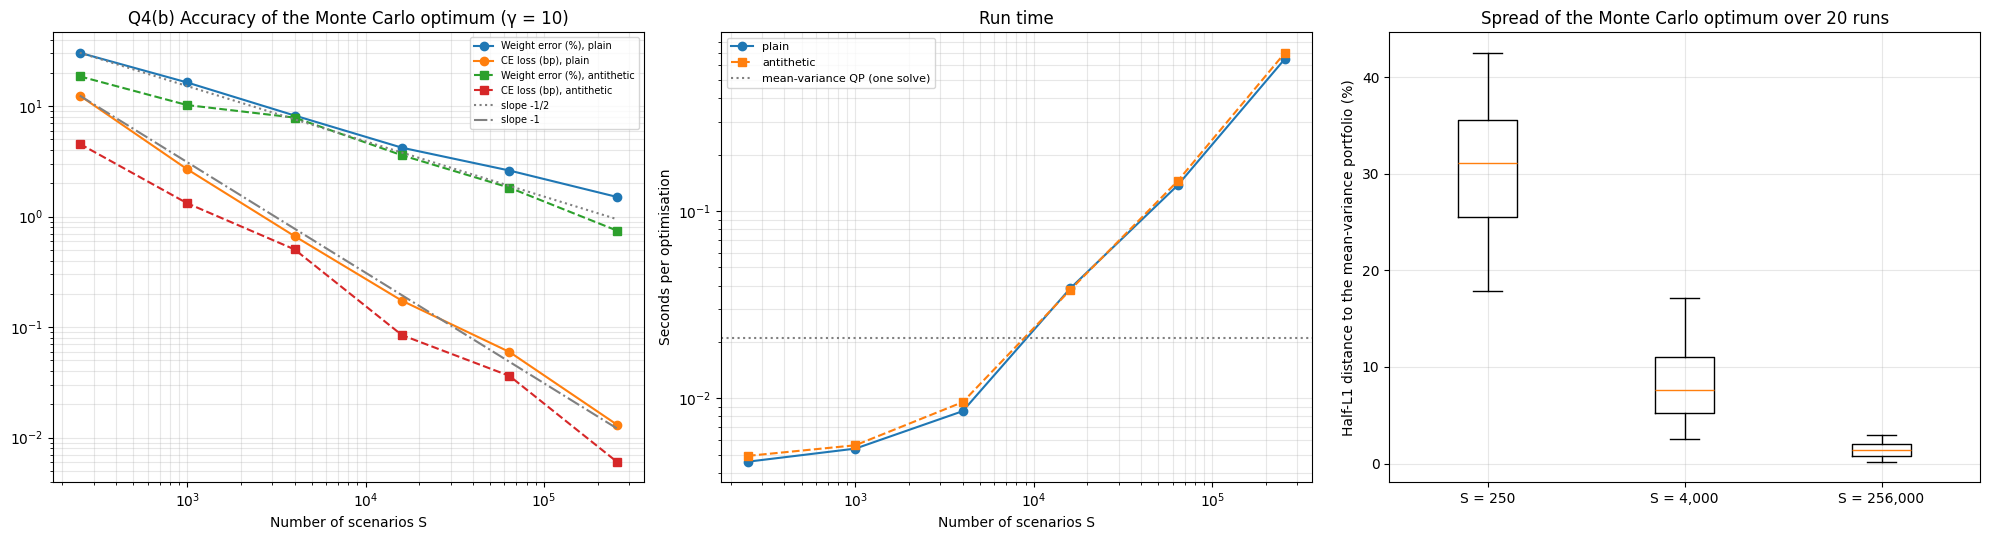

In [ ]:
# ======================================================================
# Q4(b)  Numerical expected-utility maximisation by Monte Carlo (normal model)
#        max_x  (1/S) sum_s -exp(-gamma (1 + x'R_s)),   R_s ~ N(m, C) iid,   same constraints as Q2
# ======================================================================
# Method (Lectures 2-3): simulate S return vectors from N(m, C) once, estimate E[U] for any portfolio x by the
# Monte Carlo average over these scenarios, and maximise that estimate over x. The same simulated scenarios are
# used for every candidate x, so the estimated objective is smooth and its gradient is exact.
# For numerical stability we maximise the equivalent
#     CE_hat(x) = -(1/gamma) log( (1/S) sum_s exp(-gamma x'R_s) ),
# a strictly increasing transform of the Monte Carlo estimate of E[U] (same maximiser), computed via log-sum-exp.
# Gradient: dCE_hat/dx = sum_s w_s R_s with weights w_s proportional to exp(-gamma x'R_s).
# Variance reduction: antithetic variates (Lecture 3), pairing each normal draw z with -z.
import time

GAMMA_MC = 10                                   # main risk-aversion level for Q4(b) and Q4(c)
x_star = opt_a[GAMMA_MC]                        # mean-variance benchmark from Q4(a)
ce_star = ce_return(x_star, mu_hat, Sigma_hat, GAMMA_MC)
L_chol = np.linalg.cholesky(Sigma_hat)

def draw_returns(S, seed, antithetic=False):
    """S annual return vectors from N(mu_hat, Sigma_hat). Antithetic: S/2 draws z and their mirror -z."""
    rng_ = np.random.default_rng(seed)
    if antithetic:
        Z = rng_.standard_normal((S // 2, N)); Z = np.vstack([Z, -Z])
    else:
        Z = rng_.standard_normal((S, N))
    return mu_hat + Z @ L_chol.T

def ce_hat(x, R, gamma):
    a = -gamma * (R @ x)
    amax = a.max()
    return -(amax + np.log(np.mean(np.exp(a - amax)))) / gamma

def ce_hat_grad(x, R, gamma):
    a = -gamma * (R @ x)
    w = np.exp(a - a.max()); w /= w.sum()
    return R.T @ w

def mc_solve(R, gamma, x0=None):
    """Maximise the Monte Carlo expected utility under the Q2 constraints (SLSQP, analytic gradient)."""
    x0 = np.full(N, 1 / N) if x0 is None else x0
    res = minimize(lambda x: -1e3 * ce_hat(x, R, gamma), x0, jac=lambda x: -1e3 * ce_hat_grad(x, R, gamma),
                   bounds=list(zip(LB, UB)), constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1, "jac": lambda x: np.ones(N)}],
                   method="SLSQP", options={"ftol": 1e-14, "maxiter": 1000})
    x = np.clip(res.x, LB, UB)
    # optimality is judged by the exact KKT test from Q2(a) on the Monte Carlo objective, not by SLSQP's exit
    # message (at this tight tolerance SLSQP often stops with 'positive directional derivative' at the optimum)
    kkt_resid, _ = kkt_check(x, -ce_hat_grad(x, R, gamma), LB, UB, np.ones((1, N)))
    return x, kkt_resid

def eu_hat_with_se(x, R, gamma):
    """Plain Monte Carlo estimate of E[U] and its standard error (antithetic pairs handled as one draw)."""
    u = -np.exp(-gamma * (1 + R @ x))
    if len(u) % 2 == 0 and np.allclose(R[: len(u) // 2] + R[len(u) // 2:], 2 * mu_hat):
        u = 0.5 * (u[: len(u) // 2] + u[len(u) // 2:])       # average each antithetic pair first
    return u.mean(), u.std(ddof=1) / np.sqrt(len(u))

# ---- 1. Accuracy and run time as the number of scenarios grows ----
N_LIST = [250, 1000, 4000, 16000, 64000, 256000]
REPS = 20
u_exact = expected_utility_exact(x_star, mu_hat, Sigma_hat, GAMMA_MC)
rows = []
for method in ["plain", "antithetic"]:
    for S in N_LIST:
        for rep in range(REPS):
            R = draw_returns(S, seed=1000 * rep + S, antithetic=(method == "antithetic"))
            t0 = time.perf_counter()
            x_mc, kkt_r = mc_solve(R, GAMMA_MC)
            secs = time.perf_counter() - t0
            u_hat, u_se = eu_hat_with_se(x_star, R, GAMMA_MC)
            rows.append({"method": method, "S": S, "rep": rep, "KKT resid": kkt_r, "seconds": secs,
                         "weight error (half-L1, %)": 0.5 * np.abs(x_mc - x_star).sum() * 100,
                         "max weight error (pp)": np.abs(x_mc - x_star).max() * 100,
                         "CE loss (bp)": (ce_star - ce_return(x_mc, mu_hat, Sigma_hat, GAMMA_MC)) * 1e4,
                         "z-score of E[U] estimate at x*": (u_hat - u_exact) / u_se,
                         "rel. SE of E[U] estimate (%)": u_se / abs(u_exact) * 100,
                         "sum check": abs(x_mc.sum() - 1), "min w": x_mc.min(), "max w": x_mc.max()})
mc = pd.DataFrame(rows)
summary_b = mc.groupby(["method", "S"]).agg(**{
    "mean weight error (%)": ("weight error (half-L1, %)", "mean"),
    "mean max weight error (pp)": ("max weight error (pp)", "mean"),
    "mean CE loss (bp)": ("CE loss (bp)", "mean"),
    "rel. SE of E[U] at x* (%)": ("rel. SE of E[U] estimate (%)", "mean"),
    "median run time (s)": ("seconds", "median"),
})
print(f"gamma = {GAMMA_MC}: Monte Carlo optimum vs mean-variance benchmark, {REPS} independent runs per row")
display(summary_b.round(4))

# convergence rates: slope of log(error) on log(S)
def slope(col, method):
    d = summary_b.loc[method]
    return np.polyfit(np.log(d.index.values), np.log(d[col].values), 1)[0]
rates = pd.DataFrame({m: {"weight error": slope("mean weight error (%)", m), "CE loss": slope("mean CE loss (bp)", m),
                          "SE of E[U]": slope("rel. SE of E[U] at x* (%)", m)} for m in ["plain", "antithetic"]}).T
print("Estimated convergence rates (slope of log error against log S; theory: -0.5 for weights and SE, -1 for CE loss):")
display(rates.round(2))
var_ratio = (summary_b.loc["antithetic", "rel. SE of E[U] at x* (%)"] / summary_b.loc["plain", "rel. SE of E[U] at x* (%)"]) ** 2
print(f"Antithetic variates: variance of the E[U] estimate is {var_ratio.mean():.2f} x that of plain Monte Carlo "
      f"(about {1 / var_ratio.mean():.1f}x fewer scenarios for the same accuracy)")

# ---- 2. Every gamma with a large simulation (S = 256,000, antithetic) ----
R_big = draw_returns(256000, seed=7, antithetic=True)
rows_g = []
for g in GAMMAS:
    t0 = time.perf_counter(); x_mc, _ = mc_solve(R_big, g); secs = time.perf_counter() - t0
    t1 = time.perf_counter(); solve_portfolio(mu_hat, Sigma_hat, gamma=g, check=False); secs_qp = time.perf_counter() - t1
    rows_g.append({"gamma": g, "max weight diff (pp)": np.abs(x_mc - opt_a[g]).max() * 100,
                   "half-L1 diff (%)": 0.5 * np.abs(x_mc - opt_a[g]).sum() * 100,
                   "CE loss (bp)": (ce_return(opt_a[g], mu_hat, Sigma_hat, g) - ce_return(x_mc, mu_hat, Sigma_hat, g)) * 1e4,
                   "MC time (s)": secs, "QP time (s)": secs_qp})
by_gamma = pd.DataFrame(rows_g).set_index("gamma")
print("Monte Carlo (S = 256,000, antithetic) vs mean-variance solution for every gamma:")
display(by_gamma.round(4))

x_mc_main, _ = mc_solve(R_big, GAMMA_MC)
display(pd.DataFrame({"Mean-variance (%)": x_star * 100, "Monte Carlo, S = 256k (%)": x_mc_main * 100,
                      "Difference (pp)": (x_mc_main - x_star) * 100}, index=asset_labels).round(3))

# ---- 3. Verification (every line must print PASS) ----
chk = {}
chk[f"every Monte Carlo solve is optimal for its own sample (max KKT resid {mc['KKT resid'].max():.1e})"] = mc["KKT resid"].max() < 1e-6
chk["every Monte Carlo portfolio satisfies sum = 1 and bounds"] = (mc["sum check"].max() < 1e-8) and mc["min w"].min() >= W_MIN - 1e-9 and mc["max w"].max() <= W_MAX + 1e-9
chk[f"CE loss is never negative: x* is optimal for the true objective (min {mc['CE loss (bp)'].min():.1e} bp)"] = mc["CE loss (bp)"].min() > -1e-6
chk["weight error falls as S grows (both methods)"] = all((np.diff(summary_b.loc[m, "mean weight error (%)"]) < 0).all() for m in ["plain", "antithetic"])
chk[f"weight-error rate close to 1/sqrt(S) (slopes {rates['weight error'].round(2).tolist()})"] = rates["weight error"].between(-0.7, -0.3).all()
chk[f"CE-loss rate close to 1/S (slopes {rates['CE loss'].round(2).tolist()})"] = rates["CE loss"].between(-1.3, -0.7).all()
z = mc["z-score of E[U] estimate at x*"]
chk[f"E[U] estimates at x* are unbiased: mean z = {z.mean():.2f}, sd = {z.std():.2f} (should be about 0 and 1)"] = abs(z.mean()) < 0.3 and 0.7 < z.std() < 1.3
chk["antithetic variates reduce the variance of the E[U] estimate"] = (var_ratio < 1).all()
chk[f"S = 256k matches the benchmark for every gamma (max diff {by_gamma['max weight diff (pp)'].max():.2f} pp, CE loss <= {by_gamma['CE loss (bp)'].max():.3f} bp)"] = \
    by_gamma["max weight diff (pp)"].max() < 3 and by_gamma["CE loss (bp)"].max() < 0.5
for k, v in chk.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(chk.values()), "Q4(b) verification failed"

# ---- 4. Plots ----
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
for m, mk in [("plain", "o-"), ("antithetic", "s--")]:
    d = summary_b.loc[m]
    ax[0].loglog(d.index, d["mean weight error (%)"], mk, label=f"Weight error (%), {m}")
    ax[0].loglog(d.index, d["mean CE loss (bp)"], mk, label=f"CE loss (bp), {m}")
Sref = np.array(N_LIST, float)
ax[0].loglog(Sref, summary_b.loc["plain", "mean weight error (%)"].iloc[0] * (Sref / Sref[0]) ** -0.5, ":", color="grey", label="slope -1/2")
ax[0].loglog(Sref, summary_b.loc["plain", "mean CE loss (bp)"].iloc[0] * (Sref / Sref[0]) ** -1, "-.", color="grey", label="slope -1")
ax[0].set_xlabel("Number of scenarios S"); ax[0].set_title(f"Q4(b) Accuracy of the Monte Carlo optimum (γ = {GAMMA_MC})")
ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3, which="both")
for m, mk in [("plain", "o-"), ("antithetic", "s--")]:
    ax[1].loglog(summary_b.loc[m].index, summary_b.loc[m, "median run time (s)"], mk, label=m)
ax[1].axhline(by_gamma["QP time (s)"].mean(), color="grey", ls=":", label="mean-variance QP (one solve)")
ax[1].set_xlabel("Number of scenarios S"); ax[1].set_ylabel("Seconds per optimisation"); ax[1].set_title("Run time")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
small = mc[(mc["method"] == "plain") & (mc["S"].isin([250, 4000, 256000]))]
ax[2].boxplot([small.loc[small["S"] == s, "weight error (half-L1, %)"] for s in [250, 4000, 256000]])
ax[2].set_xticks([1, 2, 3], ["S = 250", "S = 4,000", "S = 256,000"])
ax[2].set_ylabel("Half-L1 distance to the mean-variance portfolio (%)"); ax[2].set_title(f"Spread of the Monte Carlo optimum over {REPS} runs")
ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Q4(b) findings**

**Method.** We solve the expected-utility problem numerically, without using the closed form. We draw $S$ return vectors $R_s \sim N(m, C)$ once and maximise the Monte Carlo estimate of expected utility (Lectures 2 and 3),

$$\max_x \; \frac{1}{S}\sum_{s=1}^{S} -e^{-\gamma(1 + x^\top R_s)},$$

under the Q2 constraints. The same simulated scenarios are used for every candidate portfolio, so the estimated objective is smooth and can be maximised with a standard optimiser. For numerical stability we maximise $-\tfrac{1}{\gamma}\log\big(\tfrac{1}{S}\sum_s e^{-\gamma x^\top R_s}\big)$ instead, an increasing transform of the same objective with the same maximiser. Every Monte Carlo solution satisfies the optimality conditions for its own sample. We also apply antithetic variates (Lecture 3), pairing each normal draw $z$ with $-z$.

**Accuracy ($\gamma = 10$, 20 independent runs for each $S$).**

| Scenarios $S$ | Weight error, plain | Weight error, antithetic | CE loss, plain | CE loss, antithetic |
|---:|---:|---:|---:|---:|
| 250 | 30.3% | 18.6% | 12.4 bp | 4.5 bp |
| 4,000 | 8.2% | 7.9% | 0.67 bp | 0.50 bp |
| 64,000 | 2.6% | 1.8% | 0.060 bp | 0.036 bp |
| 256,000 | 1.5% | 0.75% | 0.013 bp | 0.006 bp |

The weight error is the share of the portfolio that differs from the mean-variance solution of Q4(a). The CE loss is how much certainty-equivalent return the Monte Carlo portfolio gives up under the true model.

* **Convergence rates match the theory.** The weight error falls like $1/\sqrt{S}$ (estimated slopes -0.44 and -0.45 on a log-log scale) and the CE loss like $1/S$ (slopes -0.97 and -0.94). The CE loss falls faster because utility is flat near the optimum: the loss is roughly quadratic in the weight error. So a Monte Carlo portfolio can differ noticeably in its weights while costing almost nothing in utility.
* **The estimates are unbiased.** At the true optimum the Monte Carlo estimate of $E[U]$ has mean z-score 0.03 and standard deviation 1.09 against the exact value, as it should.
* **Antithetic variates work.** They cut the variance of the $E[U]$ estimate to 0.28 times that of plain Monte Carlo, the same as using about 3.5 times as many scenarios.

**All $\gamma$.** With $S = 256{,}000$ antithetic draws, the Monte Carlo solution matches the mean-variance solution for every $\gamma$ from 1 to 100 to within 0.89 percentage points per weight, with a CE loss of at most 0.005 bp. The largest differences are between AU bonds and global bonds. These two are highly correlated (0.78) with similar means, so swapping one for the other barely changes the objective.

**Computational cost.** One mean-variance solve takes a few milliseconds. The Monte Carlo solve becomes slower than that above roughly $S = 10{,}000$ to $20{,}000$ scenarios and takes about 0.1 to 0.2 s at $S = 256{,}000$ (the exact time depends on the machine), while still carrying a small simulation error. Under the normal model the closed form is both faster and exact. The value of the Monte Carlo method is that it works for any return distribution or utility function, including fat-tailed returns where no closed form exists. The normal case serves as a test that the numerical method is correct.

## Q4(c) Bootstrap uncertainty of the optimal portfolio

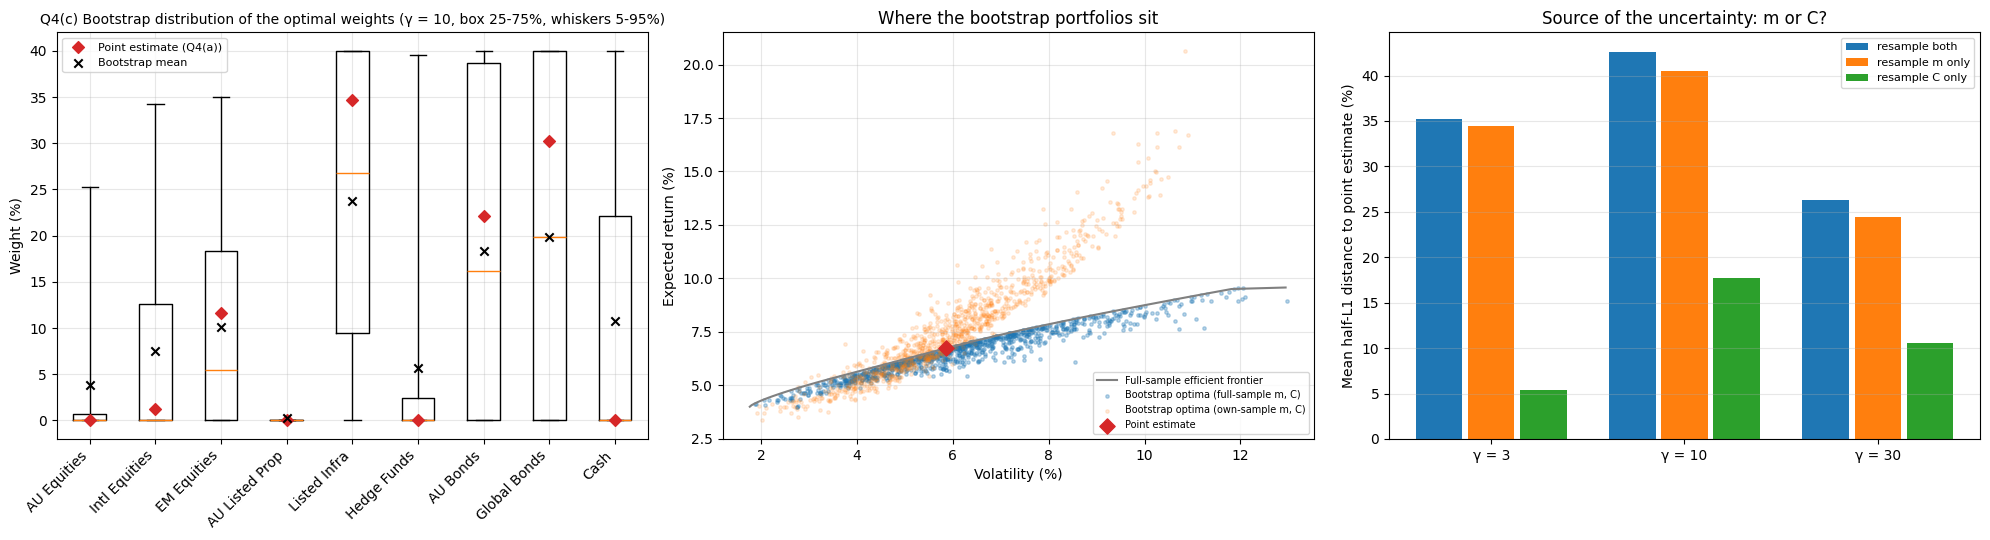

In [ ]:
# ======================================================================
# Q4(c)  Historical bootstrap: sampling uncertainty of the optimal portfolio
# ======================================================================
# Resample the 248 monthly return vectors (all assets on the same month, so cross-correlations are kept)
# with replacement, re-estimate m and C, and re-solve the Q4(a) problem.  The spread of the re-solved
# weights shows how much of the 'optimal' portfolio is driven by sampling noise in the inputs.
# Empirical bootstrap as in Lecture 15 (resample with replacement).  Returns are the Q1 estimation returns
# (HEDGNAV desmoothed).
import warnings as _w

B = 1000                                    # bootstrap samples
R_hist = est_returns.to_numpy()             # T x N monthly returns
T_hist = len(R_hist)
rng_b = np.random.default_rng(2026)

def boot_index_iid(rng_):
    return rng_.integers(0, T_hist, T_hist)

idx_iid = [boot_index_iid(rng_b) for _ in range(B)]

def boot_params(idx):
    Rb = R_hist[idx]
    return Rb.mean(0) * 12, np.cov(Rb, rowvar=False) * 12

def run_boot(idx_list, gamma, mode="both"):
    """Re-solve the gamma-problem on every bootstrap sample. mode: 'both', 'm only' (C fixed), 'C only' (m fixed)."""
    W = []
    with _w.catch_warnings(record=True) as caught:
        _w.simplefilter("always")
        for idx in idx_list:
            mb, Cb = boot_params(idx)
            if mode == "m only": Cb = Sigma_hat
            if mode == "C only": mb = mu_hat
            W.append(solve_portfolio(mb, Cb, gamma=gamma))
    n_warn = sum("KKT" in str(c.message) for c in caught)
    return np.array(W), n_warn

def half_l1_rows(W, ref): return 0.5 * np.abs(W - ref).sum(1)

# ---- 1. Main bootstrap at gamma = GAMMA_MC ----
W_boot, warn_main = run_boot(idx_iid, GAMMA_MC)
x_pt = opt_a[GAMMA_MC]                                              # point estimate from Q4(a)
tab_c = pd.DataFrame({
    "Point estimate (%)": x_pt * 100,
    "Bootstrap mean (%)": W_boot.mean(0) * 100,
    "Bootstrap sd (pp)": W_boot.std(0) * 100,
    "5th pct (%)": np.percentile(W_boot, 5, 0) * 100,
    "95th pct (%)": np.percentile(W_boot, 95, 0) * 100,
    "P(held > 0.5%)": (W_boot > 0.005).mean(0),
    "P(at 40% cap)": (W_boot > W_MAX - 1e-4).mean(0),
}, index=asset_labels)
print(f"gamma = {GAMMA_MC}: optimal weights across {B} iid bootstrap samples")
display(tab_c.round(2))

# performance of every bootstrap portfolio if the full-sample estimates were the truth
stats_b = np.array([port_stats(w, mu_hat, Sigma_hat) for w in W_boot])
ce_loss_b = np.array([(ce_return(x_pt, mu_hat, Sigma_hat, GAMMA_MC) - ce_return(w, mu_hat, Sigma_hat, GAMMA_MC)) * 1e4 for w in W_boot])
own_stats = np.array([port_stats(w, *boot_params(idx)) for w, idx in zip(W_boot, idx_iid)])
perf = pd.DataFrame({
    "Expected return, own sample (%)": own_stats[:, 0] * 100,
    "Volatility, own sample (%)": own_stats[:, 1] * 100,
    "Expected return, full-sample m (%)": stats_b[:, 0] * 100,
    "Volatility, full-sample C (%)": stats_b[:, 1] * 100,
    "CE loss vs point estimate (bp)": ce_loss_b,
    "Half-L1 distance to point estimate (%)": half_l1_rows(W_boot, x_pt) * 100,
}).describe(percentiles=[0.05, 0.5, 0.95]).loc[["mean", "std", "5%", "50%", "95%"]]
print("Bootstrap portfolios: predicted return/risk on their own sample vs under the full-sample estimates")
display(perf.round(2))

# ---- 2. What drives the uncertainty, and how does it depend on gamma? ----
rows = []
for g in [3, GAMMA_MC, 30]:
    for mode in ["both", "m only", "C only"]:
        if g == GAMMA_MC and mode == "both":
            W_, nw = W_boot, warn_main
        else:
            W_, nw = run_boot(idx_iid[:500], g, mode)
        ref = opt_a[g]
        rows.append({"gamma": g, "resampled input": mode, "samples": len(W_), "KKT warnings": nw,
                     "mean half-L1 to point estimate (%)": half_l1_rows(W_, ref).mean() * 100,
                     "average weight sd (pp)": W_.std(0).mean() * 100,
                     "sd of expected return (pp)": np.std([port_stats(w, mu_hat, Sigma_hat)[0] for w in W_]) * 100,
                     "sd of volatility (pp)": np.std([port_stats(w, mu_hat, Sigma_hat)[1] for w in W_]) * 100})
drivers = pd.DataFrame(rows).set_index(["gamma", "resampled input"])
print("Dispersion of the bootstrap optima (expected return and volatility measured under the full-sample estimates):")
display(drivers.round(2))

# ---- 3. Verification (every line must print PASS) ----
chk = {}
allW = W_boot
chk["every bootstrap portfolio satisfies sum = 1 and bounds"] = (np.abs(allW.sum(1) - 1).max() < 1e-8) and allW.min() >= W_MIN - 1e-8 and allW.max() <= W_MAX + 1e-8
chk[f"every bootstrap solve passed the KKT test ({int(drivers['KKT warnings'].sum())} warnings)"] = drivers["KKT warnings"].sum() == 0
m_boot = np.array([boot_params(idx)[0] for idx in idx_iid])
se_ratio = m_boot.std(0) / (np.sqrt(np.diag(Sigma_hat)) / np.sqrt(T_hist / 12))
chk[f"bootstrap SE of m matches sigma/sqrt(years) (ratio {se_ratio.min():.2f} to {se_ratio.max():.2f})"] = ((se_ratio > 0.85) & (se_ratio < 1.15)).all()
chk["bootstrap mean of m is centred on the full-sample m"] = (np.abs(m_boot.mean(0) - mu_hat) < 3 * m_boot.std(0) / np.sqrt(B)).all()
chk[f"CE loss vs point estimate never negative under full-sample estimates (min {ce_loss_b.min():.1e} bp)"] = ce_loss_b.min() > -1e-6
d_ = drivers["mean half-L1 to point estimate (%)"]
chk["uncertainty in m moves the portfolio more than uncertainty in C (every gamma)"] = all(d_.loc[(g, "m only")] > d_.loc[(g, "C only")] for g in [3, GAMMA_MC, 30])
chk["highest risk aversion (gamma = 30) gives the most stable portfolio"] = d_.loc[(30, "both")] < min(d_.loc[(3, "both")], d_.loc[(GAMMA_MC, "both")])
c_share = {g: d_.loc[(g, "C only")] / d_.loc[(g, "both")] for g in [3, GAMMA_MC, 30]}
chk[f"C matters far more away from the gamma = 3 corner (C-only share {c_share[3]:.0%} at 3, {c_share[GAMMA_MC]:.0%} at {GAMMA_MC}, {c_share[30]:.0%} at 30)"] = \
    min(c_share[GAMMA_MC], c_share[30]) > 2 * c_share[3]
chk["bootstrap optima look better on their own sample than under the full-sample estimates"] = own_stats[:, 0].mean() > stats_b[:, 0].mean()
for k, v in chk.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(chk.values()), "Q4(c) verification failed"

# ---- 4. Plots ----
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
ax[0].boxplot([W_boot[:, j] * 100 for j in range(N)], whis=(5, 95), showfliers=False)
ax[0].scatter(range(1, N + 1), x_pt * 100, marker="D", color="C3", zorder=3, label="Point estimate (Q4(a))")
ax[0].scatter(range(1, N + 1), W_boot.mean(0) * 100, marker="x", color="k", zorder=3, label="Bootstrap mean")
ax[0].set_xticks(range(1, N + 1), asset_labels, rotation=45, ha="right"); ax[0].set_ylabel("Weight (%)")
ax[0].set_title(f"Q4(c) Bootstrap distribution of the optimal weights (γ = {GAMMA_MC}, box 25-75%, whiskers 5-95%)", fontsize=10)
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[1].plot(frontier["vol"] * 100, frontier["ret"] * 100, color="grey", lw=1.5, label="Full-sample efficient frontier")
ax[1].scatter(stats_b[:, 1] * 100, stats_b[:, 0] * 100, s=6, alpha=0.3, label="Bootstrap optima (full-sample m, C)")
ax[1].scatter(own_stats[:, 1] * 100, own_stats[:, 0] * 100, s=6, alpha=0.15, color="C1", label="Bootstrap optima (own-sample m, C)")
r0, v0 = port_stats(x_pt, mu_hat, Sigma_hat)
ax[1].scatter(v0 * 100, r0 * 100, marker="D", color="C3", s=60, zorder=4, label="Point estimate")
ax[1].set_xlabel("Volatility (%)"); ax[1].set_ylabel("Expected return (%)"); ax[1].grid(alpha=0.3)
ax[1].set_title("Where the bootstrap portfolios sit"); ax[1].legend(fontsize=7, loc="lower right")
modes = ["both", "m only", "C only"]; xg = np.arange(3); bw = 0.27
for i, mode in enumerate(modes):
    ax[2].bar(xg + (i - 1) * bw, [d_.loc[(g, mode)] for g in [3, GAMMA_MC, 30]], bw - 0.03, label=f"resample {mode}")
ax[2].set_xticks(xg, [f"γ = {g}" for g in [3, GAMMA_MC, 30]]); ax[2].set_ylabel("Mean half-L1 distance to point estimate (%)")
ax[2].set_title("Source of the uncertainty: m or C?"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

**Q4(c) findings**

**Method.** We use the empirical bootstrap of Lecture 15: we resample the 248 monthly return vectors with replacement (whole months, so the correlations between assets are kept), re-estimate $m$ and $C$, and re-solve the $\gamma = 10$ problem of Q4(a). We repeat this 1,000 times. The bootstrap reproduces the sampling error of the means well: the bootstrap standard error of each mean is 0.99 to 1.03 times $\sigma/\sqrt{\text{years}}$.

**The estimated optimal portfolio is very uncertain.**

| Asset | Point estimate | Bootstrap mean | 90% interval | Held in |
|---|---:|---:|---:|---:|
| Infrastructure | 34.7% | 23.8% | 0% to 40% | 84% of samples |
| Global bonds | 30.3% | 19.8% | 0% to 40% | 71% |
| AU bonds | 22.1% | 18.3% | 0% to 40% | 68% |
| EM equities | 11.6% | 10.1% | 0% to 35.0% | 60% |
| Intl equities | 1.3% | 7.5% | 0% to 34.3% | 43% |
| Cash | 0% | 10.8% | 0% to 40% | 41% |
| Hedge funds | 0% | 5.7% | 0% to 39.6% | 26% |
| AU equities | 0% | 3.8% | 0% to 25.3% | 25% |
| AU listed property | 0% | 0.2% | 0% to 0% | 3% |

For every asset except AU listed property, the 90% interval runs from zero to a large weight, often the full 40% cap. Assets with zero weight in the point estimate (cash, hedge funds, AU equities) appear in a quarter to two fifths of the bootstrap samples. On average, a bootstrap portfolio differs from the point estimate by 42.6% of its value (90% range 15.8% to 73.6%).

**Optimised portfolios look better on the data used to build them.** On their own bootstrap sample, the optimal portfolios promise an expected return of 7.71% on average. Under the full-sample estimates the same portfolios deliver 6.52%, about 1.2 percentage points less, because each optimisation favours whichever assets happened to look good in its own sample. If the full-sample estimates were the truth, the bootstrap portfolios would lose 57 bp of certainty-equivalent return on average against the point estimate (median 42 bp, 95th percentile 165 bp).

**The expected returns are the main source of the uncertainty.** Resampling only $m$ (keeping $C$ fixed) moves the portfolio almost as much as resampling both: 40.5% against 42.6% at $\gamma = 10$. Resampling only $C$ moves it by 17.7%. The same holds at $\gamma = 3$ (34.5% against 5.4%) and $\gamma = 30$ (24.4% against 10.6%). This matches Q1(e) and Q2(d).

**The uncertainty depends on risk aversion, but not monotonically.** The average distance to the point estimate is 35.3% at $\gamma = 3$, 42.6% at $\gamma = 10$ and 26.3% at $\gamma = 30$. At $\gamma = 3$ the portfolio sits at a corner of the constraints (all growth assets, infrastructure at the cap), so resampling can only reshuffle weight among the growth assets, and $C$ hardly matters (it accounts for 15% of the uncertainty). At $\gamma = 30$ the portfolio is close to the minimum-variance portfolio, which does not depend on $m$, so it is the most stable. The intermediate $\gamma = 10$ portfolio trades growth against defensive assets and is the most sensitive.

**What this means for reliability.** The individual weights of the estimated optimal portfolio should not be taken literally: the data cannot tell us whether the right infrastructure weight is 0% or 40%. What is robust is the broad structure, such as a mix of growth and defensive assets at $\gamma = 10$ and almost no AU listed property. These results motivate the out-of-sample tests in Q5 and Q6.

# Q5 Out-of-sample performance of the strategic allocations
## Q5(a) Estimation window and portfolio construction

In [ ]:
# ======================================================================
# Q5  Out-of-Sample Performance of Strategic Asset Allocations
# ======================================================================

T0_list = [
    "2015-12",
    "2018-12",
    "2021-12",
    "2023-12"
]

estimation_months = 120    # 10-year estimation window
oos_months = 24            # 2-year out-of-sample period

T0_list = [pd.Period(x, freq="M") for x in T0_list]

# APRA growth exposure vector, aligned with the asset order used in Q2
growth_share = pd.Series({
    "ASA52":     1.00,
    "NDDLWI":    1.00,
    "NDLEEGF":   1.00,
    "RDAU":      1.00,
    "FDCIISAH":  1.00,
    "HEDGNAV":   0.50,
    "BACM0":     0.00,
    "H03432AU":  0.00,
    "BAUBIL":    0.00
}).reindex(assets)

g = growth_share.to_numpy(dtype=float)

saa_targets = {
    "Defensive": 0.30,
    "Balanced":  0.70,
    "Aggressive": 0.90
}

In [ ]:
# ======================================================================
# Helper 1: parameter estimation using information available at T0 only
# ======================================================================

def estimate_at_T0(R_raw):
    """
    Estimate annualised m and C from a historical monthly-return window.
    Hedge-fund returns are desmoothed using ONLY this window.
    """

    R_est = R_raw.copy()

    # Desmooth HEDGNAV using only information in this estimation window
    R_est["HEDGNAV"], rho_hf = desmooth(R_raw["HEDGNAV"])

    # Same annualisation convention as Q1
    m_est = R_est.mean() * 12
    C_est = R_est.cov() * 12

    # Align with the common asset order used in Q2/Q3
    mu, Sigma = to_arrays(m_est, C_est)

    rf_est = m_est["BAUBIL"]

    return mu, Sigma, rf_est, rho_hf

In [ ]:
# ======================================================================
# Helper 2: construct the three strategic portfolios
# ======================================================================

def construct_saa(mu, Sigma):
    weights = {}

    for name, growth_target in saa_targets.items():

        weights[name] = solve_portfolio(
            mu,
            Sigma,
            A_eq=g,
            b_eq=growth_target,
            label=f"Q5 {name}"
        )

    return weights

**Q5(a) findings**

A 10-year estimation window balances sample size with the need to accommodate changing market conditions. We select four evaluation dates (December 2015, 2018, 2021 and 2023), each followed by a complete two-year test period. This horizon allows us to examine medium-term performance across several historical periods.

At each date, expected returns and covariances are estimated using only the preceding 120 monthly observations, with hedge-fund desmoothing estimated within that window. We then construct the three minimum-variance portfolios using the same growth/defensive targets and investment constraints as in Q3.

## Q5(b) Predicted and realised out-of-sample performance

In [ ]:
# Q5(b): evaluate one historical experiment

def evaluate_q5(T0):
    T0 = pd.Period(T0, freq="M")

    # Training window: same specification as Q5(a)
    train_start = T0 - estimation_months + 1
    R_train = monthly_returns.loc[train_start:T0, assets].copy()

    # Test window: starts strictly after T0
    test_start = T0 + 1
    test_end = T0 + oos_months
    R_test = monthly_returns.loc[test_start:test_end, assets].copy()

    # Check complete, consecutive monthly observations
    for label, R, start, end in [
        ("Training", R_train, train_start, T0),
        ("Test", R_test, test_start, test_end),
    ]:
        expected_index = pd.period_range(start, end, freq="M")
        if not R.index.equals(expected_index):
            raise ValueError(f"{T0}: incomplete {label.lower()} dates.")
        if not np.isfinite(R.to_numpy()).all():
            raise ValueError(f"{T0}: invalid {label.lower()} returns.")

    assert R_train.index.max() < R_test.index.min()

    # Reuse Q5(a): estimate parameters and construct SAA portfolios
    mu, Sigma, rf_pred, rho_hf = estimate_at_T0(R_train)
    weights = construct_saa(mu, Sigma)

    # Test-period cash return is used only for evaluation
    rf_real = 12 * R_test["BAUBIL"].mean()

    rows = []
    returns = {}
    wealth = {}

    for name, w in weights.items():
        w = np.asarray(w, dtype=float)

        # Check the same constraints as Q3/Q5(a)
        assert np.isclose(w.sum(), 1, atol=1e-7)
        assert np.all(w >= LB - 1e-7)
        assert np.all(w <= UB + 1e-7)
        assert np.isclose(g @ w, saa_targets[name], atol=1e-7)

        # Predicted performance
        pred_ret = float(w @ mu)
        pred_vol = float(np.sqrt(w @ Sigma @ w))
        pred_sharpe = (
            (pred_ret - rf_pred) / pred_vol
            if pred_vol > 0 else np.nan
        )

        # Realised monthly returns: constant target weights
        rp = pd.Series(
            R_test.to_numpy() @ w,
            index=R_test.index,
            name=name,
        )

        if (rp <= -1).any():
            raise ValueError(f"{T0}, {name}: invalid compounded wealth.")

        real_ret = 12 * rp.mean()
        real_vol = np.sqrt(12) * rp.std(ddof=1)
        real_sharpe = (
            (real_ret - rf_real) / real_vol
            if real_vol > 0 else np.nan
        )

        # Include initial wealth of 1 at T0
        wealth_path = pd.concat([
            pd.Series([1.0], index=pd.PeriodIndex([T0])),
            (1 + rp).cumprod(),
        ])

        returns[name] = rp
        wealth[name] = wealth_path

        rows.append({
            "T0": str(T0),
            "Portfolio": name,
            "Predicted return (%)": 100 * pred_ret,
            "Realised return (%)": 100 * real_ret,
            "Predicted volatility (%)": 100 * pred_vol,
            "Realised volatility (%)": 100 * real_vol,
            "Predicted Sharpe": pred_sharpe,
            "Realised Sharpe": real_sharpe,
            "OOS cumulative return (%)":
                100 * (wealth_path.iloc[-1] - 1),
            "HF rho used": rho_hf,
        })

    return (
        pd.DataFrame(rows),
        weights,
        pd.DataFrame(returns),
        pd.DataFrame(wealth),
    )

In [ ]:
# Evaluate all four dates; retain outputs for Q5(c) and Q6

result_frames = []
q5_weights = {}
q5_returns = {}
q5_wealth = {}

for T0 in T0_list:
    results, weights, returns, wealth = evaluate_q5(T0)
    key = str(T0)

    result_frames.append(results)
    q5_weights[key] = weights
    q5_returns[key] = returns
    q5_wealth[key] = wealth

q5_results = pd.concat(result_frames, ignore_index=True)

display(q5_results.round(3))
print("All date, data and portfolio-constraint checks passed.")

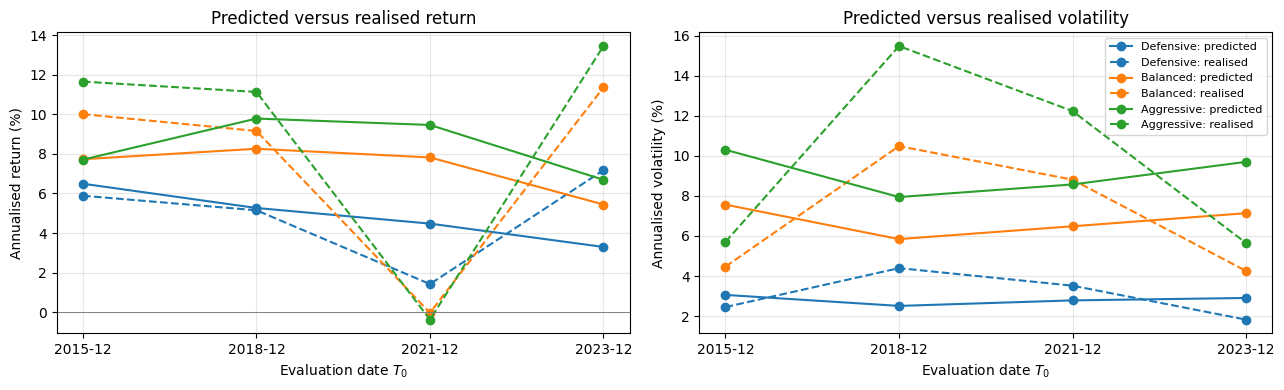

In [ ]:
# Predicted versus realised return and volatility

colors = {
    "Defensive": "C0",
    "Balanced": "C1",
    "Aggressive": "C2",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, metric in zip(axes, ["return", "volatility"]):
    for name in saa_targets:
        d = q5_results[q5_results["Portfolio"] == name]

        ax.plot(
            d["T0"], d[f"Predicted {metric} (%)"],
            color=colors[name], marker="o",
            label=f"{name}: predicted",
        )
        ax.plot(
            d["T0"], d[f"Realised {metric} (%)"],
            color=colors[name], marker="o", linestyle="--",
            label=f"{name}: realised",
        )

    ax.set_title(f"Predicted versus realised {metric}")
    ax.set_xlabel("Evaluation date $T_0$")
    ax.set_ylabel(f"Annualised {metric} (%)")
    ax.grid(alpha=0.3)

axes[0].axhline(0, color="grey", linewidth=0.7)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Q5(b) findings**

For each evaluation date \(T_0\), we use the three strategic portfolios constructed in Q5(a) and evaluate them over the following 24 months. The target weights remain unchanged throughout the test period and are maintained through monthly rebalancing. Transaction costs are excluded.

Predicted annualised return and volatility are calculated from the training-period estimates:
\[
\widehat{\mu}_p=w^\top m_{T_0},
\qquad
\widehat{\sigma}_p=\sqrt{w^\top C_{T_0}w}.
\]

Realised portfolio returns use the original monthly return series:
\[
r_{p,t}=w^\top r_t.
\]
We report annualised arithmetic mean return, annualised monthly volatility, Sharpe ratio and cumulative return. Predicted Sharpe ratios use the training-period mean cash return, while realised Sharpe ratios use the test-period mean cash return solely for evaluation.

Historical estimates can both overstate and understate subsequent returns and risk. For the portfolios constructed in December 2018, realised volatility exceeded predictions for all three strategies; the aggressive portfolio’s volatility was 15.48%, compared with a prediction of 7.94%.

Return forecast errors were particularly large for the December 2021 portfolios, evaluated over 2022–2023. Predicted annualised returns were 4.48%, 7.82% and 9.46% for the defensive, balanced and aggressive portfolios, whereas realised returns were 1.42%, −0.03% and −0.38%. All three underperformed the mean cash return. By contrast, the December 2023 portfolios achieved higher returns and lower volatility than predicted.

Higher-growth portfolios had higher realised volatility in every test period, but did not always earn higher returns. These results show that historical optimisation does not guarantee subsequent performance. Predicted risk uses desmoothed hedge-fund returns, while realised risk uses reported returns, so the differences cannot be attributed entirely to changing market conditions. Sharpe comparisons also reflect changes in cash returns.

## Q5(c) Stability across evaluation dates

In [ ]:
# Q5(c): compare allocations and performance across T0

portfolio_names = list(saa_targets)
date_labels = [str(T0) for T0 in T0_list]

# 1. Asset weights at each evaluation date
weight_rows = []

for key in date_labels:
    for name in portfolio_names:
        w = q5_weights[key][name]

        row = {"T0": key, "Portfolio": name}
        row.update({
            LABEL[asset]: 100 * weight
            for asset, weight in zip(assets, w)
        })
        weight_rows.append(row)

q5_weight_table = pd.DataFrame(weight_rows)

print("Portfolio weights (%):")
display(q5_weight_table.round(2))


# 2. Half-L1 allocation distances between successive dates
stability_rows = []

for name in portfolio_names:
    for previous_key, current_key in zip(
        date_labels[:-1], date_labels[1:]
    ):
        w_previous = q5_weights[previous_key][name]
        w_current = q5_weights[current_key][name]

        allocation_distance = (
            0.5 * np.abs(w_current - w_previous).sum()
        )

        stability_rows.append({
            "Portfolio": name,
            "From T0": previous_key,
            "To T0": current_key,
            "Allocation change (%)": 100 * allocation_distance
        })

q5_stability = pd.DataFrame(stability_rows)

print("Changes between target allocations (%):")
display(q5_stability.round(2))


# 3. Realised performance across the separate test periods
realised_comparison = q5_results.pivot(
    index="T0",
    columns="Portfolio",
    values=[
        "Realised return (%)",
        "Realised volatility (%)",
        "Realised Sharpe",
        "OOS cumulative return (%)"
    ]
)

print("Out-of-sample performance across evaluation dates:")
display(realised_comparison.round(3))

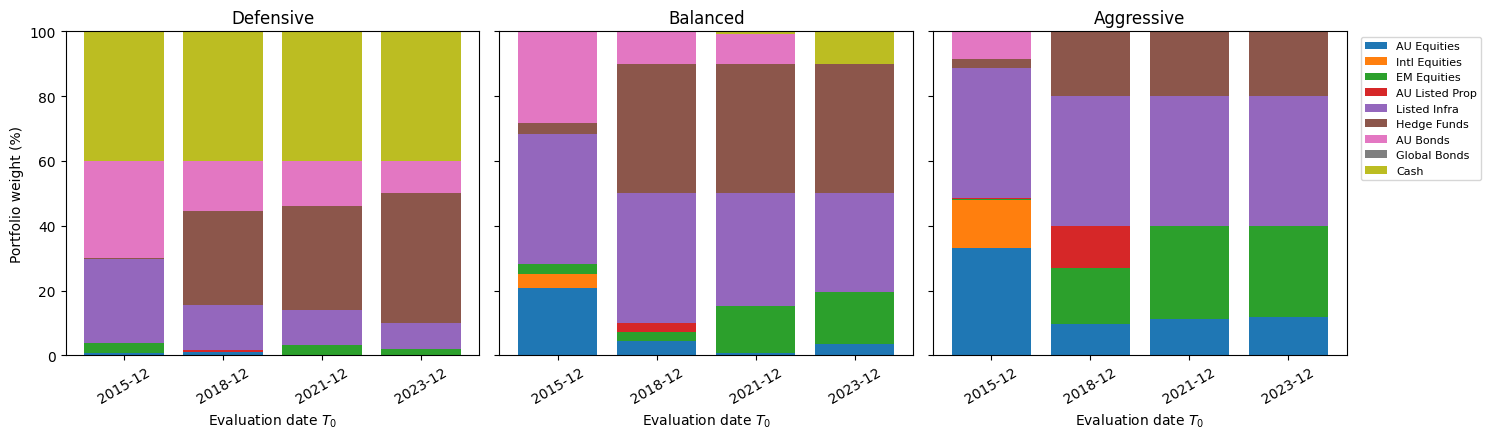

In [ ]:
# Q5(c): portfolio composition across evaluation dates

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5), sharey=True
)

asset_colors = plt.get_cmap("tab10").colors

for ax, name in zip(axes, portfolio_names):
    W = np.array([
        q5_weights[key][name] for key in date_labels
    ]) * 100

    bottom = np.zeros(len(date_labels))

    for j, asset in enumerate(assets):
        ax.bar(
            date_labels,
            W[:, j],
            bottom=bottom,
            color=asset_colors[j],
            label=LABEL[asset]
        )
        bottom += W[:, j]

    ax.set_title(name)
    ax.set_xlabel("Evaluation date $T_0$")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=30)

axes[0].set_ylabel("Portfolio weight (%)")
axes[-1].legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=8
)

plt.tight_layout()
plt.show()

**Q5(c) findings**

We compare portfolio allocations and out-of-sample performance across
the four evaluation dates. Differences between successive target
allocations are measured using the half-L1 distance:

$$
D(w_a,w_b)=\frac{1}{2}\sum_i |w_{a,i}-w_{b,i}|.
$$

This measures allocation differences, rather than actual trading
turnover. Each portfolio uses a 120-month estimation window ending at
its evaluation date, with hedge-fund desmoothing estimated within that
window. Subsequent returns are reserved for evaluation.

Portfolio weights vary across evaluation dates despite unchanged growth/defensive targets. The largest changes occurred between December 2015 and December 2018, with half-L1 allocation distances of 29.57%, 39.21% and 46.83% for the defensive, balanced and aggressive portfolios. Because these portfolios minimise variance under fixed constraints, the changes reflect differences in estimated covariance matrices.

Similar allocations do not imply similar performance. The aggressive portfolios constructed in December 2021 and December 2023 differed by only 0.51%, yet their subsequent two-year cumulative returns were −2.17% and 30.29%. Market conditions therefore matter even when portfolio weights remain similar.

To avoid look-ahead bias, each estimation window ends at its evaluation date, and the resulting weights are applied only from the following month. Using full-sample estimates would introduce future information into historical decisions.

These four tests are separate investment experiments and provide limited evidence about future performance. Target weights are maintained through monthly rebalancing, and transaction costs are excluded. Half-L1 distances measure differences between target allocations rather than actual trading turnover. Reported annualised returns are arithmetic means, whereas cumulative returns incorporate compounding.

# Q6 Tactical asset allocation
## Q6(a) Strategy specification

In [ ]:
# Q6(a): strategy settings

SAA_NAME = "Balanced"
SAA_GROWTH = saa_targets[SAA_NAME]

TACTICAL_DEVIATION = 0.10
GROWTH_LOWER = SAA_GROWTH - TACTICAL_DEVIATION
GROWTH_UPPER = SAA_GROWTH + TACTICAL_DEVIATION

Q6_WINDOW = estimation_months     # 120 months
Q6_HORIZON = oos_months           # 24 months
Q6_GAMMA = 10.0

# Use a distinct name to avoid conflicts with Q4's gamma loops.
growth_vector = (
    growth_exposure.reindex(assets).to_numpy(dtype=float)
)

if not np.isfinite(growth_vector).all():
    raise ValueError("Missing growth-exposure classification.")

print(f"Long-term SAA: {SAA_NAME}, growth target {SAA_GROWTH:.0%}")
print(f"Tactical growth range: {GROWTH_LOWER:.0%}–{GROWTH_UPPER:.0%}")
print(f"Estimation window: {Q6_WINDOW} months")
print(f"Rebalancing: monthly; gamma = {Q6_GAMMA:g}")
print(f"Out-of-sample horizon: {Q6_HORIZON} months per starting date")

**Q6(a) findings**

We choose the balanced allocation, with 70% growth and 30% defensive
exposure, as the long-term SAA. Tactical growth exposure is allowed
between 60% and 80%, representing a maximum deviation of 10 percentage
points from the strategic target. Hedge funds contribute 50% growth
and 50% defensive exposure, consistent with Q3 and Q5.

Parameters are estimated from the preceding 120 monthly observations,
and the portfolio is rebalanced monthly. This preserves the estimation
window and weight-maintenance frequency used in Q5. We choose gamma = 10,
the principal risk-aversion value investigated in Q4.

At each month-end, parameters are estimated using only information
available by that date, including window-specific hedge-fund
desmoothing. The new allocation is applied to the following month's
original returns. Portfolios remain fully invested, long-only, and
subject to the 40% individual-asset cap.

The strategy is evaluated over the same four 24-month periods as Q5.
The benchmark is the corresponding balanced portfolio constructed at
each initial evaluation date, with its target weights maintained
monthly. Results exclude transaction costs; turnover is recorded
for both strategies.

With $\gamma = 10$ the full-sample optimum has a growth exposure of only 47.6% (Q4(a)), below the 60% floor. The floor therefore binds often, and part of the tactical strategy is a steady underweight in growth compared with the SAA. Q6(e) shows how often the limits bind and how the results change with $\gamma$.

## Q6(b) Out-of-sample implementation

In [ ]:
# Q6(b): utility optimisation with tactical growth limits

def solve_tactical(mu, Sigma, gamma, lower, upper):
    # First solve without the tactical growth restriction.
    w, info = solve_portfolio(
        mu,
        Sigma,
        gamma=gamma,
        return_info=True,
        label="Q6 unrestricted growth"
    )

    growth = float(growth_vector @ w)
    boundary = None

    if growth < lower:
        boundary = lower
    elif growth > upper:
        boundary = upper

    # If necessary, re-solve at the binding tactical boundary.
    if boundary is not None:
        w, info = solve_portfolio(
            mu,
            Sigma,
            gamma=gamma,
            A_eq=growth_vector,
            b_eq=boundary,
            return_info=True,
            label="Q6 tactical boundary"
        )

    growth = float(growth_vector @ w)

    if (
        not np.isfinite(w).all()
        or abs(w.sum() - 1) > 1e-7
        or np.any(w < LB - 1e-7)
        or np.any(w > UB + 1e-7)
        or growth < lower - 1e-7
        or growth > upper + 1e-7
        or info["kkt_residual"] > 1e-6
    ):
        raise ValueError("Q6 optimisation failed a constraint or optimality check.")

    return w, info

In [ ]:
# Q6(b): monthly out-of-sample backtest

def run_q6_at_T0(
    T0,
    gamma=Q6_GAMMA,
    window=Q6_WINDOW,
    lower=GROWTH_LOWER,
    upper=GROWTH_UPPER
):
    T0 = pd.Period(T0, freq="M")
    key = str(T0)

    test_months = pd.period_range(
        start=T0 + 1,
        periods=Q6_HORIZON,
        freq="M"
    )

    R_test = monthly_returns.reindex(
        index=test_months,
        columns=assets
    )

    if R_test.isna().any().any():
        raise ValueError(f"{T0}: incomplete test data.")

    # Corresponding fixed balanced allocation from Q5
    w_saa = np.asarray(
        q5_weights[key][SAA_NAME],
        dtype=float
    ).copy()

    if abs(growth_vector @ w_saa - SAA_GROWTH) > 1e-7:
        raise ValueError(f"{T0}: SAA benchmark has incorrect growth exposure.")

    monthly_rows = []
    weight_rows = []
    mean_rows = []
    volatility_rows = []

    # Weights immediately before the next rebalance
    previous_taa_end = None
    previous_saa_end = None

    for month in test_months:
        decision_month = month - 1

        expected_train = pd.period_range(
            end=decision_month,
            periods=window,
            freq="M"
        )

        R_train = monthly_returns.reindex(
            index=expected_train,
            columns=assets
        )

        if R_train.isna().any().any():
            raise ValueError(f"{month}: incomplete training data.")

        if R_train.index.max() >= month:
            raise ValueError("Training data overlap the investment month.")

        mu, Sigma, rf_est, rho_hf = estimate_at_T0(R_train)

        w_taa, info = solve_tactical(
            mu, Sigma, gamma, lower, upper
        )

        # Exclude initial establishment from both turnover measures.
        taa_turnover = (
            0.0 if previous_taa_end is None
            else 0.5 * np.abs(w_taa - previous_taa_end).sum()
        )
        saa_turnover = (
            0.0 if previous_saa_end is None
            else 0.5 * np.abs(w_saa - previous_saa_end).sum()
        )

        asset_returns = R_test.loc[month].to_numpy(dtype=float)

        taa_return = float(asset_returns @ w_taa)
        saa_return = float(asset_returns @ w_saa)

        if min(1 + taa_return, 1 + saa_return) <= 0:
            raise ValueError("Non-positive portfolio wealth.")

        # End-of-month weights drift with asset returns.
        previous_taa_end = (
            w_taa * (1 + asset_returns) / (1 + taa_return)
        )
        previous_saa_end = (
            w_saa * (1 + asset_returns) / (1 + saa_return)
        )

        predicted_return, predicted_vol = port_stats(
            w_taa, mu, Sigma
        )

        monthly_rows.append({
            "Month": month,
            "Decision month": decision_month,
            "TAA return": taa_return,
            "SAA return": saa_return,
            "Cash return": R_test.loc[month, "BAUBIL"],
            "Growth exposure": float(growth_vector @ w_taa),
            "TAA turnover": taa_turnover,
            "SAA turnover": saa_turnover,
            "Predicted TAA return": predicted_return,
            "Predicted TAA volatility": predicted_vol,
            "Estimated cash return": rf_est,
            "HF rho": rho_hf,
            "KKT residual": info["kkt_residual"]
        })

        weight_rows.append(w_taa.copy())
        mean_rows.append(mu.copy())
        volatility_rows.append(np.sqrt(np.diag(Sigma)))

    monthly = pd.DataFrame(monthly_rows).set_index("Month")

    returns = monthly[["TAA return", "SAA return"]].copy()
    returns.columns = ["TAA", "SAA"]

    wealth = pd.concat([
        pd.DataFrame(
            {"TAA": [1.0], "SAA": [1.0]},
            index=pd.PeriodIndex([T0], freq="M")
        ),
        (1 + returns).cumprod()
    ])

    # Verify that the benchmark reproduces Q5's cumulative return.
    q5_cumulative = q5_results.loc[
        (q5_results["T0"] == key)
        & (q5_results["Portfolio"] == SAA_NAME),
        "OOS cumulative return (%)"
    ].iloc[0]

    if not np.isclose(
        100 * (wealth["SAA"].iloc[-1] - 1),
        q5_cumulative,
        atol=1e-7
    ):
        raise ValueError("SAA benchmark does not reproduce Q5.")

    return {
        "monthly": monthly,
        "returns": returns,
        "wealth": wealth,
        "weights": pd.DataFrame(
            weight_rows, index=test_months, columns=assets
        ),
        "estimated_means": pd.DataFrame(
            mean_rows, index=test_months, columns=assets
        ),
        "estimated_volatilities": pd.DataFrame(
            volatility_rows, index=test_months, columns=assets
        )
    }

In [ ]:
# Run the baseline TAA strategy for all four Q5 starting dates

q6_runs = {}
diagnostic_rows = []

for T0 in T0_list:
    key = str(T0)
    run = run_q6_at_T0(T0)
    q6_runs[key] = run

    monthly = run["monthly"]

    diagnostic_rows.append({
        "T0": key,
        "Test months": len(monthly),
        "Minimum growth (%)": 100 * monthly["Growth exposure"].min(),
        "Maximum growth (%)": 100 * monthly["Growth exposure"].max(),
        "Total TAA turnover (%)": 100 * monthly["TAA turnover"].sum(),
        "Total SAA turnover (%)": 100 * monthly["SAA turnover"].sum(),
        "Maximum KKT residual": monthly["KKT residual"].max()
    })

q6_diagnostics = pd.DataFrame(diagnostic_rows).set_index("T0")
display(q6_diagnostics.round(4))

print(
    "All training-date, portfolio-constraint and "
    "Q5 benchmark checks passed."
)

# Inspect the first five monthly target allocations.
first_key = str(T0_list[0])
display(
    q6_runs[first_key]["weights"]
    .rename(columns=LABEL)
    .head()
    .mul(100)
    .round(2)
)

**Q6(b) findings**

At each rebalancing date, we solve

$$
\max_x \left(x^\top m_k-\frac{\gamma}{2}x^\top C_kx\right)
$$

subject to

$$
\mathbf{1}^\top x=1,\qquad
0\leq x_i\leq0.4,\qquad
0.60\leq g^\top x\leq0.80.
$$

We first solve the utility problem under the basic investment constraints.
If the optimal growth exposure lies inside the tactical interval, this
solution is retained. Otherwise, we re-solve with growth exposure fixed
at the violated boundary. Because the objective is concave and the
feasible set is convex, a solution outside the interval makes the
corresponding tactical boundary binding.

Annualised parameters are used consistently with Q4. Scaling both the
mean and covariance to a monthly horizon would multiply the objective
by the same positive constant and leave the optimal weights unchanged.

For each test month, estimation ends in the preceding month. Turnover
is measured against the weights after the previous month's asset
returns, rather than against the previous target weights. Initial
portfolio establishment is excluded from turnover for both strategies.

## Q6(c) Comparison with the fixed strategic allocation

In [ ]:
# Q6(c): Performance comparison between TAA and fixed SAA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def q6_performance_stats(r, cash):
    r = r.astype(float)
    cash = cash.reindex(r.index).astype(float)

    if len(r) < 2 or not np.isfinite(
        np.column_stack([r.to_numpy(), cash.to_numpy()])
    ).all():
        raise ValueError("Incomplete or invalid return data.")

    if (r <= -1).any():
        raise ValueError("Returns imply non-positive wealth.")

    # Annualised arithmetic return and volatility
    annual_return = 12 * r.mean()
    annual_vol = np.sqrt(12) * r.std(ddof=1)

    # Same Sharpe convention as Q5:
    # annualised excess mean / annualised portfolio volatility
    annual_cash = 12 * cash.mean()
    sharpe = (
        (annual_return - annual_cash) / annual_vol
        if annual_vol > 0 else np.nan
    )

    # Include initial wealth of 1 when calculating drawdown
    wealth = np.r_[1.0, (1 + r).cumprod().to_numpy()]
    cumulative_return = wealth[-1] - 1
    cagr = wealth[-1] ** (12 / len(r)) - 1

    running_peak = np.maximum.accumulate(wealth)
    drawdown = wealth / running_peak - 1
    max_drawdown = -drawdown.min()  # positive loss magnitude

    return {
        "Annualised return (%)": 100 * annual_return,
        "Annualised volatility (%)": 100 * annual_vol,
        "Sharpe ratio": sharpe,
        "Cumulative return (%)": 100 * cumulative_return,
        "CAGR (%)": 100 * cagr,
        "Maximum drawdown (%)": 100 * max_drawdown,
    }


q6_rows = []

for key, run in q6_runs.items():
    monthly = run["monthly"]

    for strategy in ["TAA", "SAA"]:
        stats = q6_performance_stats(
            monthly[f"{strategy} return"],
            monthly["Cash return"]
        )

        # Check consistency with the wealth saved in Q6(b)
        saved_cumulative = 100 * (
            run["wealth"][strategy].iloc[-1] - 1
        )
        assert np.isclose(
            stats["Cumulative return (%)"],
            saved_cumulative,
            atol=1e-7
        )

        q6_rows.append({
            "T0": key,
            "Strategy": strategy,
            **stats
        })

q6_comparison = (
    pd.DataFrame(q6_rows)
    .set_index(["T0", "Strategy"])
    .sort_index()
)

display(q6_comparison.round(3))

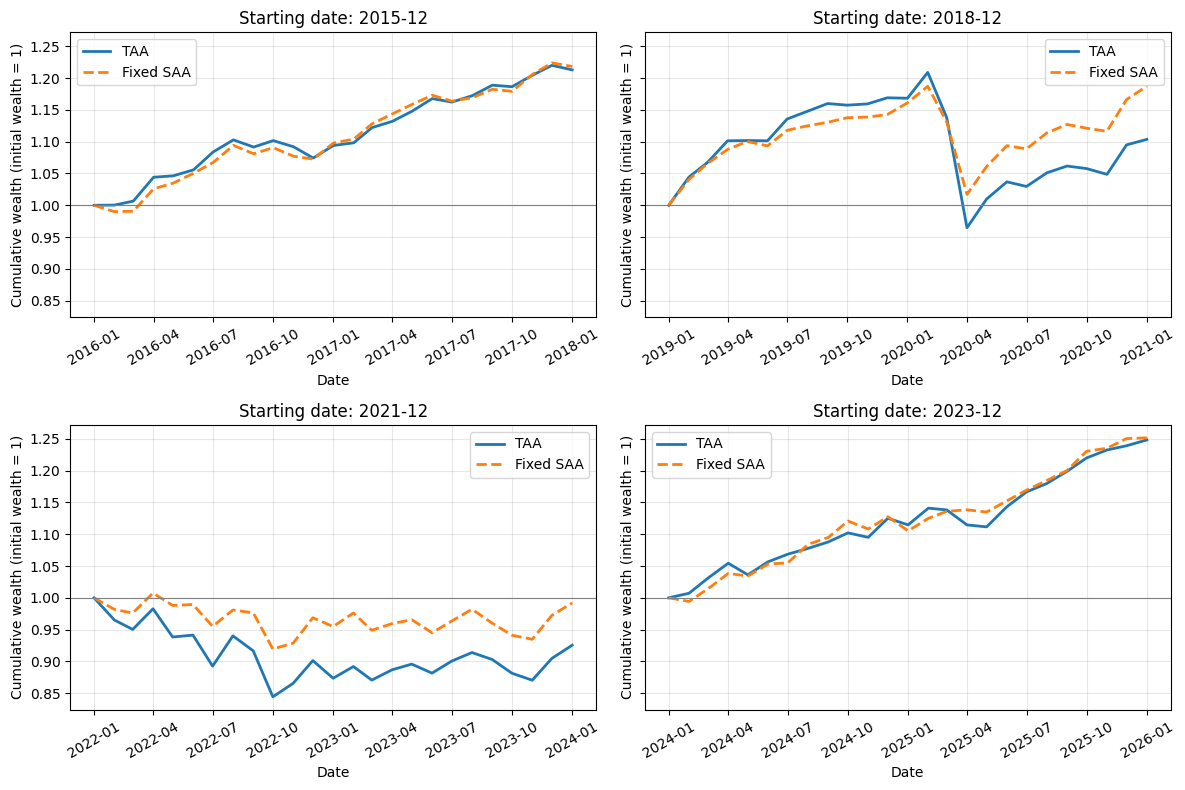

In [ ]:
# Q6(c): Cumulative wealth paths

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), sharey=True
)

for ax, (key, run) in zip(axes.flat, q6_runs.items()):
    wealth = run["wealth"]
    dates = wealth.index.to_timestamp(how="end")

    ax.plot(
        dates, wealth["TAA"],
        label="TAA", color="C0", linewidth=2
    )
    ax.plot(
        dates, wealth["SAA"],
        label="Fixed SAA", color="C1",
        linestyle="--", linewidth=2
    )

    ax.axhline(1, color="grey", linewidth=0.8)
    ax.set_title(f"Starting date: {key}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Cumulative wealth (initial wealth = 1)")
    ax.grid(alpha=0.3)
    ax.legend()
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Q6(c) findings**

The tactical strategy achieved lower cumulative returns than the fixed balanced SAA in all four test periods. The largest differences occurred in the periods beginning in December 2018 and December 2021: TAA returned 10.36% and −7.45%, compared with 18.72% and −0.81% for SAA.

TAA also had higher annualised volatility in three of the four periods and larger maximum drawdowns in every period. Its Sharpe ratio was lower except in the December 2015 test, where the improvement was marginal (1.819 versus 1.815).

Overall, these historical tests provide no consistent evidence that the chosen tactical strategy improved performance relative to the fixed SAA. Results exclude transaction costs and apply to the selected model settings and test periods.

## Q6(d) Changes in portfolio weights

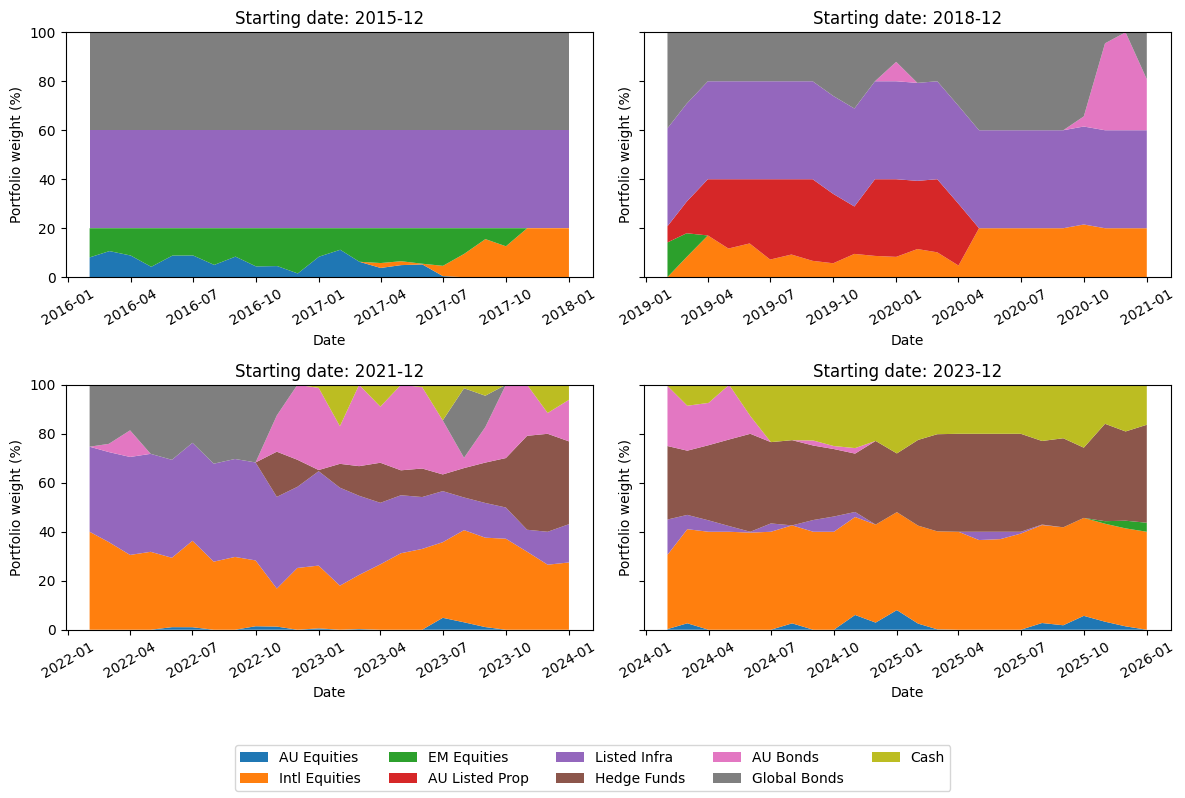

In [ ]:
# Q6(d): portfolio weights over time

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
asset_colors = plt.get_cmap("tab10").colors[:len(assets)]

for ax, (key, run) in zip(axes.flat, q6_runs.items()):
    weights = run["weights"]
    dates = weights.index.to_timestamp(how="end")

    ax.stackplot(
        dates, 100 * weights.to_numpy().T,
        labels=[LABEL[a] for a in assets],
        colors=asset_colors
    )
    ax.set_title(f"Starting date: {key}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Portfolio weight (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=30)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.10, 1, 1))
plt.show()

In [ ]:
# Q6(d): identify the largest monthly changes in target weights

change_rows = []
q6_weight_changes = {}

for key, run in q6_runs.items():
    weights = run["weights"]
    changes = 0.5 * weights.diff().abs().sum(axis=1)
    changes.iloc[0] = np.nan  # exclude the initial allocation
    q6_weight_changes[key] = changes
    month = changes.idxmax()
    position = weights.index.get_loc(month)

    change_rows.append({
        "T0": key,
        "Investment month": str(month),
        "Decision month": str(month - 1),
        "Target weight change (%)": 100 * changes.loc[month],
        "Growth before (%)": 100 * (weights.iloc[position - 1] @ growth_vector),
        "Growth after (%)": 100 * (weights.iloc[position] @ growth_vector)
    })

q6_largest_changes = pd.DataFrame(change_rows).set_index("T0")
display(q6_largest_changes.round(2))

# This measures changes between target allocations.
# Actual trading turnover in Q6(b) also allows for weight drift.

In [ ]:
# Q6(d): compare estimates before and after important weight changes

parameter_rows = []
correlation_rows = []

for key, run in q6_runs.items():
    weights = run["weights"]
    selected_months = [q6_weight_changes[key].idxmax()]

    # Also examine April 2020, when growth exposure fell sharply.
    if key == "2018-12":
        selected_months.append(pd.Period("2020-04", freq="M"))

    for month in sorted(selected_months):
        previous_month = month - 1
        old_weights = weights.loc[previous_month]
        new_weights = weights.loc[month]
        weight_change = new_weights - old_weights

        # Show assets whose weights changed by at least 5 percentage points.
        changed_assets = weight_change.index[weight_change.abs() >= 0.05]

        for asset in changed_assets:
            parameter_rows.append({
                "Month": str(month),
                "Asset": LABEL[asset],
                "Weight before (%)": 100 * old_weights[asset],
                "Weight after (%)": 100 * new_weights[asset],
                "Mean before (%)": 100 * run["estimated_means"].loc[previous_month, asset],
                "Mean after (%)": 100 * run["estimated_means"].loc[month, asset],
                "Vol before (%)": 100 * run["estimated_volatilities"].loc[previous_month, asset],
                "Vol after (%)": 100 * run["estimated_volatilities"].loc[month, asset]
            })

        # Re-estimate covariance using the same historical windows as Q6(b).
        correlations = []
        for investment_month in [previous_month, month]:
            train_dates = pd.period_range(
                end=investment_month - 1, periods=Q6_WINDOW, freq="M"
            )
            train = monthly_returns.reindex(index=train_dates, columns=assets)
            if train.isna().any().any():
                raise ValueError("Incomplete estimation window.")

            mu, covariance, _, _ = estimate_at_T0(train)
            np.testing.assert_allclose(
                mu, run["estimated_means"].loc[investment_month], atol=1e-10
            )
            volatility = np.sqrt(np.diag(covariance))
            correlation = covariance / np.outer(volatility, volatility)
            correlations.append(pd.DataFrame(correlation, index=assets, columns=assets))

        # Compare the assets with the largest weight increase and decrease.
        asset_up = weight_change.idxmax()
        asset_down = weight_change.idxmin()
        pairs = [(asset_up, asset_down)]
        if str(month) == "2020-04":
            pairs.append(("RDAU", "FDCIISAH"))

        for asset_a, asset_b in pairs:
            correlation_rows.append({
                "Month": str(month),
                "Asset pair": LABEL[asset_a] + " / " + LABEL[asset_b],
                "Correlation before": correlations[0].loc[asset_a, asset_b],
                "Correlation after": correlations[1].loc[asset_a, asset_b]
            })

q6_parameter_changes = pd.DataFrame(parameter_rows).set_index(["Month", "Asset"])
q6_correlation_changes = pd.DataFrame(correlation_rows).set_index("Month")

display(q6_parameter_changes.round(2))
display(q6_correlation_changes.round(3))

**Q6(d) findings**

Portfolio weights change over time even when total growth exposure remains similar. The largest monthly target-weight changes in the four test periods were 7.37%, 31.36%, 40.35% and 18.54%. Growth exposure stayed at 60% during three of these changes, showing that substantial reallocation can occur within the growth and defensive groups.

In October 2017, international equities increased from 12.63% to 20.00%, while emerging-market equities fell from 7.37% to zero. Both estimated returns declined, but the emerging-market estimate fell further, from 6.09% to 5.30%, compared with 5.80% to 5.73% for international equities. International equities therefore became relatively more attractive despite the fall in their own expected return.

The April 2020 change was also associated with higher estimated risk. Listed property fell from 25.21% to zero as its expected return decreased from 11.78% to 7.89% and its volatility increased from 11.77% to 17.24%. Its correlations with international equities and infrastructure rose from 0.322 to 0.465 and from 0.521 to 0.630, reducing its diversification benefits. Growth exposure fell from 69.97% to 60.00%, while global bonds increased to the 40% cap.

In October 2020, Australian bonds increased from 4.14% to 35.50%, while global bonds fell from 34.34% to 4.50%. The Australian bond expected return rose from 5.28% to 5.48%, narrowing the gap with global bonds, while Australian bond volatility remained lower. Their correlation changed little, from 0.727 to 0.730. In July 2023, the relative return estimates moved in the opposite direction: the global bond estimate rose from 2.51% to 2.59%, while the Australian bond estimate fell from 2.58% to 2.49%. Global bonds increased to 28.39%, with reductions in Australian bonds and cash.

In February 2024, international equities increased from 30.32% to 38.42%, while infrastructure fell from 14.42% to 5.84%. This was consistent with their expected returns rising from 10.12% to 10.62% and falling from 7.99% to 7.75%, respectively.

These results show that allocations depend on relative expected returns and the covariance between assets, subject to the portfolio constraints. The comparisons help explain the changes but do not isolate the effect of each input. Rolling estimates change as both new observations enter and old observations leave the window. Large reallocations following small changes in estimates also suggest that the optimal weights can be sensitive to estimation error. All estimates use data ending before the investment month, under the same month-end availability assumption as Q6(b).

## Q6(e) Sensitivity to the estimation window and risk aversion

In [ ]:
# ================================================================
# Q6(e): Sensitivity to the estimation window
# ================================================================

WINDOW_CHOICES = [60, 120]   # 5 years versus baseline 10 years

q6e_rows = []
q6e_runs = {}

for window in WINDOW_CHOICES:

    for T0 in T0_list:

        key = str(T0)

        # Run the same TAA strategy, changing ONLY the estimation window
        run = run_q6_at_T0(
            T0,
            window=window
        )

        q6e_runs[(window, key)] = run

        monthly = run["monthly"]

        # TAA realised performance
        taa_stats = q6_performance_stats(
            monthly["TAA return"],
            monthly["Cash return"]
        )

        # Fixed SAA benchmark
        saa_stats = q6_performance_stats(
            monthly["SAA return"],
            monthly["Cash return"]
        )

        # Compare portfolio weights with the baseline 120-month strategy
        baseline_weights = q6_runs[key]["weights"]

        allocation_difference = (
            0.5
            * (run["weights"] - baseline_weights)
            .abs()
            .sum(axis=1)
        )

        q6e_rows.append({
            "Estimation window (months)": window,
            "T0": key,

            "TAA cumulative return (%)":
                taa_stats["Cumulative return (%)"],

            "SAA cumulative return (%)":
                saa_stats["Cumulative return (%)"],

            "TAA minus SAA (pp)":
                taa_stats["Cumulative return (%)"]
                - saa_stats["Cumulative return (%)"],

            "TAA volatility (%)":
                taa_stats["Annualised volatility (%)"],

            "TAA Sharpe":
                taa_stats["Sharpe ratio"],

            "TAA maximum drawdown (%)":
                taa_stats["Maximum drawdown (%)"],

            "TAA turnover (%)":
                100 * monthly["TAA turnover"].sum(),

            "Mean allocation difference vs 120m (%)":
                100 * allocation_difference.mean(),

            "Maximum allocation difference vs 120m (%)":
                100 * allocation_difference.max()
        })


q6e_results = pd.DataFrame(q6e_rows)

display(
    q6e_results
    .sort_values(["T0", "Estimation window (months)"])
    .round(3)
)

In [ ]:
# ================================================================
# Q6(e) continued: sensitivity to the risk-aversion parameter gamma
# ================================================================
GAMMA_CHOICES = [5, 7, 10, 20]      # baseline Q6_GAMMA = 10

q6e_gamma_rows = []
for gam in GAMMA_CHOICES:
    for T0 in T0_list:
        key = str(T0)
        # same strategy, changing ONLY gamma (baseline run is reused)
        run = q6_runs[key] if gam == Q6_GAMMA else run_q6_at_T0(T0, gamma=gam)
        monthly = run["monthly"]
        taa = q6_performance_stats(monthly["TAA return"], monthly["Cash return"])
        saa = q6_performance_stats(monthly["SAA return"], monthly["Cash return"])
        growth = monthly["Growth exposure"]
        q6e_gamma_rows.append({
            "gamma": gam,
            "T0": key,
            "TAA minus SAA (pp)": taa["Cumulative return (%)"] - saa["Cumulative return (%)"],
            "TAA Sharpe": taa["Sharpe ratio"],
            "SAA Sharpe": saa["Sharpe ratio"],
            "TAA volatility (%)": taa["Annualised volatility (%)"],
            "TAA turnover (%)": 100 * monthly["TAA turnover"].sum(),
            "Average growth (%)": 100 * growth.mean(),
            "Months at 60% floor": int((growth < GROWTH_LOWER + 1e-6).sum()),
            "Months at 80% ceiling": int((growth > GROWTH_UPPER - 1e-6).sum()),
        })

q6e_gamma = pd.DataFrame(q6e_gamma_rows)
display(q6e_gamma.set_index(["gamma", "T0"]).round(2))
print("Cumulative TAA minus SAA return (pp):")
display(q6e_gamma.pivot(index="T0", columns="gamma", values="TAA minus SAA (pp)").round(2))

# growth exposure of the full-sample optimum (Q4(a) problem) for each gamma
g_q6 = growth_exposure.reindex(assets).to_numpy(dtype=float)
print("Growth exposure of the full-sample optimum:",
      {gam: f"{100 * g_q6 @ solve_portfolio(mu_hat, Sigma_hat, gamma=gam):.1f}%" for gam in GAMMA_CHOICES})

**Q6(e) findings**

**Estimation window.** Using 60 instead of 120 months changes the tactical portfolio a lot: the average half-L1 distance between the two strategies' target weights is 16.1% to 51.8%, depending on the period. The 60-month version did better than the 120-month version in all four periods and beat the SAA in two of them (by 0.46 and 2.92 percentage points), but it still lost 6.87 and 3.57 points in the periods starting December 2018 and December 2021. Its turnover was higher in two periods and lower in the other two.

**Risk aversion.** We repeat the baseline with $\gamma = 5$, 7, 10 and 20. The TAA earns more than the SAA in only 3 of the 16 cases, by at most 0.98 percentage points, and less in the other 13, by up to 11.75 points. The main effect of $\gamma$ is on growth exposure. With $\gamma = 10$ the strategy sits at the 60% floor in 63 of the 96 test months and at the 80% ceiling in 9. With $\gamma = 5$ it sits at the ceiling in 68 months, and with $\gamma = 20$ it sits at the floor in all 96. A low $\gamma$ helped slightly in the calm periods starting December 2015 and December 2023 but lost the most in the period covering the 2020 market fall. A high $\gamma$ did the opposite. No value of $\gamma$ makes the tactical strategy reliably better than the fixed SAA.

## Q6(f) Does tactical reallocation add value?

In [ ]:
# Q6(f): value added, actual turnover and illustrative transaction costs
# Use saved out-of-sample runs; no new optimisation or future information.
# Turnover tau = 0.5 * sum(abs(target weights - drifted weights)).
# c is the cost per dollar bought OR sold, so total cost fraction = 2*c*tau.
# Costs are paid before the month's return; initial establishment is excluded
# for both strategies, consistently with Q6(b).
COST_BPS = [0, 10, 25]  # illustrative scenarios, not calibrated trading costs
q6f_rows = []
for window in WINDOW_CHOICES:
    for T0 in T0_list:
        key = str(T0)
        run = q6e_runs[(window, key)]
        data = run['monthly']
        for cost_bps in COST_BPS:
            c = cost_bps / 10000
            stats = {}
            for strategy in ['TAA', 'SAA']:
                gross = data[f'{strategy} return']
                turnover = data[f'{strategy} turnover']
                if not np.isfinite(turnover).all() or (turnover < 0).any():
                    raise ValueError('Invalid turnover.')
                cost_fraction = 2 * c * turnover
                if (cost_fraction >= 1).any():
                    raise ValueError('Transaction costs exhaust wealth.')
                net = (1 - cost_fraction) * (1 + gross) - 1
                stats[strategy] = q6_performance_stats(net, data['Cash return'])
                if cost_bps == 0:
                    np.testing.assert_allclose(
                        (1 + net).prod(), run['wealth'][strategy].iloc[-1], atol=1e-10
                    )
            q6f_rows.append({
                'Window (months)': window,
                'T0': key,
                'Cost per traded dollar (bps)': cost_bps,
                'TAA cumulative return (%)': stats['TAA']['Cumulative return (%)'],
                'SAA cumulative return (%)': stats['SAA']['Cumulative return (%)'],
                'TAA minus SAA (pp)': stats['TAA']['Cumulative return (%)'] - stats['SAA']['Cumulative return (%)'],
                'TAA Sharpe': stats['TAA']['Sharpe ratio'],
                'SAA Sharpe': stats['SAA']['Sharpe ratio'],
                'TAA total one-way turnover (%)': 100 * data['TAA turnover'].sum(),
                'SAA total one-way turnover (%)': 100 * data['SAA turnover'].sum(),
                'TAA annualised one-way turnover (%)': 100 * data['TAA turnover'].sum() * 12 / len(data),
                'SAA annualised one-way turnover (%)': 100 * data['SAA turnover'].sum() * 12 / len(data),
            })

q6f_results = pd.DataFrame(q6f_rows)
q6f_baseline = q6f_results.query('`Window (months)` == @Q6_WINDOW and `Cost per traded dollar (bps)` == 0')
print('Baseline gross performance and trading turnover (24-month tests):')
display(q6f_baseline.drop(columns=['Window (months)', 'Cost per traded dollar (bps)']).set_index('T0').round(3))
print('Cost sensitivity: cumulative TAA minus SAA return (percentage points):')
display(q6f_results.pivot(index=['Window (months)', 'T0'], columns='Cost per traded dollar (bps)', values='TAA minus SAA (pp)').round(3))
print('Costs are illustrative; each strategy is charged for its own turnover.')

**Q6(f) findings**

We combine the out-of-sample performance in Q6(c), parameter sensitivity in Q6(d)–(e), and actual drift-adjusted turnover recorded in Q6(b). The fixed SAA maintains constant target weights through monthly rebalancing, so its trading turnover is small but non-zero.

For an illustrative cost of $c$ per dollar bought or sold, with one-way turnover $\tau_t=\frac12\sum_i|w_{t,i}-w_{t,i}^{\mathrm{pre}}|$, we evaluate

$$r_{t}^{\mathrm{net}}=(1-2c\tau_t)(1+r_t^{\mathrm{gross}})-1.$$

These scenarios retain the existing target allocations and gross-path turnover; the optimiser does not anticipate costs. Costs are deducted proportionally before returns, with initial establishment excluded for both strategies. They are an implementation-cost sensitivity check, not estimates of actual asset-specific trading costs.

The baseline tactical strategy did not consistently add value relative to the fixed balanced SAA. Across the four 24-month test periods, its cumulative returns were lower by 0.54, 8.36, 6.64 and 0.33 percentage points. TAA had higher volatility in three periods and larger maximum drawdowns in all four. Its only Sharpe-ratio improvement was marginal, at 1.819 versus 1.815 in the December 2015 experiment.

Parameter estimation helps explain the lack of robust improvement. TAA responds to estimated expected returns as well as covariances, whereas the SAA benchmark minimises estimated variance under a fixed growth constraint. Rolling historical means are noisy and need not predict future returns. Q6(d) shows substantial reallocations following relatively small changes in relative return estimates. Shortening the estimation window from 120 to 60 months changed average allocations by 16.13–51.81% in half-L1 distance. The shorter-window strategy outperformed SAA in only two periods, by 0.46 and 2.92 percentage points, and underperformed in the other two. A shorter window reacts faster but uses fewer observations; a longer window reduces sampling noise but may retain outdated market regimes. These results demonstrate sensitivity, without establishing estimation error as the sole cause of underperformance.

Implementation costs further weaken the case for this TAA strategy. Baseline total one-way turnover over each two-year test was 80.15–346.75%, compared with 13.10–21.46% for SAA. The benchmark also trades monthly to restore its fixed targets, but tactical target changes require considerably more trading. Under an illustrative cost of 10 basis points per dollar bought or sold, the baseline cumulative-return gaps widen to −0.70, −8.75, −7.24 and −0.72 percentage points. For the 60-month strategy, the small 2015-period gain becomes a 0.16-percentage-point loss at 25 basis points. The 2023-period gain remains positive, so costs do not eliminate every tactical benefit.

Overall, these tests provide no robust evidence that the chosen tactical implementation improves on maintaining the fixed SAA, and this holds for every estimation window and value of $\gamma$ we tried in Q6(e). The comparison combines tactical flexibility with a different optimisation objective, so it does not isolate the effect of reallocation alone. Four short historical tests, illustrative costs and the assumed month-end availability of index data limit generalisation. Turnover penalties or more stable return estimates could be investigated, but any improvement would require fresh out-of-sample validation.

## Extension B: Multiperiod dynamic portfolio optimisation


### (a) Fixed, tactical and dynamic portfolio strategies

A fixed strategic asset allocation (SAA) maintains constant target weights throughout the investment horizon. In our implementation, monthly rebalancing restores these targets after market movements cause actual weights to drift. Trading occurs, but the targets do not respond to changing market estimates, wealth or the remaining horizon.

The tactical asset allocation (TAA) strategy in Q6 updates expected returns and covariances using information available at each rebalancing date. It solves a one-period mean–variance problem within the investment constraints and permitted deviations from SAA. Its target weights respond to market estimates, but its objective uses a fixed risk-aversion parameter without explicitly accounting for current wealth or future reallocation opportunities.

A dynamic portfolio policy chooses weights according to the investment date and current wealth:

$$
x_k=\pi_k(W_k).
$$

It maximises expected terminal utility,

$$
\max_{\pi}\mathbb{E}\left[-e^{-\gamma W_N}\right],
$$

accounting for how current decisions affect subsequent wealth and future optimal allocations. Under exponential utility, absolute risk aversion is constant, while relative risk aversion equals $\gamma W$. Consequently, allocations may depend on wealth even when return assumptions remain unchanged.

Actual weight changes depend on the model and constraints. Long-only restrictions, asset caps or growth-exposure limits may keep some weights unchanged across wealth levels or dates. Small wealth changes may also produce little adjustment. A dynamic policy therefore permits wealth and horizon dependence, but does not necessarily change every weight or automatically become more conservative near the terminal date.

### (b) Dynamic programming formulation

**Model and admissible strategies**

Consider investment dates $k=0,\ldots,N$, with wealth evolving according to

$$
W_{k+1}=W_k(1+x_k^\top R_{k+1}).
$$

Here, $x_k$ is the vector of portfolio weights selected before observing
$R_{k+1}$. We assume returns are independent and identically distributed
across periods, with fixed model parameters. The return-distribution
parameters are estimated at the initial decision date using only
information available then and are held fixed throughout the investment
horizon; they are not updated in response to subsequent market
observations. Current wealth and the investment date are therefore
sufficient state variables.

Using the fully invested, long-only and individual-asset constraints
from the core investigation, define the feasible set as

$$
\mathcal X=
\left\{
x\in\mathbb R^n:
\mathbf 1^\top x=1,\quad 0\leq x_i\leq0.4
\right\}.
$$

Any additional growth-exposure restrictions adopted in the numerical
model must also be included in $\mathcal X$.

An admissible policy $\pi=(\pi_0,\ldots,\pi_{N-1})$ selects
$x_k=\pi_k(W_k)\in\mathcal X$ using only information available at date $k$.
The objective is

$$
\max_{\pi}\mathbb E^\pi\left[-e^{-\gamma W_N}\right],
\qquad \gamma>0,
$$

where $\mathbb E^\pi$ denotes expectation under the wealth process
generated by policy $\pi$.

**Value function and terminal condition**

Define the value function as the maximum expected terminal utility
achievable from date $k$ onwards, starting with wealth $w$:

$$
V_k(w)=
\sup_{\pi_k,\ldots,\pi_{N-1}}
\mathbb E^\pi
\left[
-e^{-\gamma W_N}\mid W_k=w
\right].
$$

At the terminal date, no investment decisions remain. Hence,

$$
V_N(w)=U(w)=-e^{-\gamma w}.
$$

**Derivation of the Bellman recursion**

At date $k$, first choose a feasible allocation $x$. Once the next
return is realised, wealth becomes

$$
W_{k+1}=w(1+x^\top R_{k+1}).
$$

By the law of iterated expectations, expected terminal utility can
be evaluated by first conditioning on the next-period information:

$$
\mathbb E^\pi[U(W_N)\mid W_k=w]
=
\mathbb E^\pi
\left[
\mathbb E^\pi[U(W_N)\mid\mathcal F_{k+1}]
\mid W_k=w
\right],
$$

where $\mathcal F_{k+1}$ represents the information available at date
$k+1$.

Under an optimal continuation policy, the inner conditional expectation
equals $V_{k+1}(W_{k+1})$. Maximising over the current allocation gives
the Bellman recursion:

$$
\boxed{
V_k(w)=
\max_{x\in\mathcal X}
\mathbb E
\left[
V_{k+1}\left(w(1+x^\top R_{k+1})\right)
\right],
\quad k=N-1,\ldots,0.
}
$$

The corresponding optimal policy is

$$
\pi_k^*(w)\in
\operatorname*{arg\,max}_{x\in\mathcal X}
\mathbb E
\left[
V_{k+1}\left(w(1+x^\top R_{k+1})\right)
\right].
$$

Starting from $V_N$, we solve backwards to obtain $V_{N-1},\ldots,V_0$
and the associated allocation rules. For initial wealth $W_0=1$,
$V_0(1)$ is the optimal expected terminal utility.

Although return-distribution parameters remain fixed, optimal weights
may change with current wealth and the remaining investment horizon.
The continuation value incorporates future optimal reallocations.
Therefore, at earlier dates, replacing it with next-period utility
would generally solve a different, one-period problem.

### (c) Final-period optimisation and dependence on wealth

At the final investment date \(N-1\), let current wealth be \(w>0\).
Only one investment period remains, so

$$
W_N=w(1+x^\top R_N).
$$

Assume monthly returns follow

$$
R_N\sim N(m_\Delta,C_\Delta),
$$

where the parameters are estimated at the initial decision date and
held fixed, as specified in part (b). The feasible set remains

$$
\mathcal X=
\left\{
x:\mathbf{1}^\top x=1,\quad 0\leq x_i\leq0.4
\right\}.
$$

**Expected terminal utility**

For a given allocation \(x\), terminal wealth is normally distributed:

$$
W_N\sim N\left(
w(1+x^\top m_\Delta),
\,w^2x^\top C_\Delta x
\right).
$$

Using the exponential moment of a normal random variable,

$$
\mathbb E[-e^{-\gamma W_N}]
=
-\exp\left[
-\gamma w(1+x^\top m_\Delta)
+\frac{\gamma^2w^2}{2}x^\top C_\Delta x
\right].
$$

Maximising this expression is equivalent to maximising the
certainty-equivalent terminal wealth,

$$
w(1+x^\top m_\Delta)
-\frac{\gamma w^2}{2}x^\top C_\Delta x.
$$

Since \(w>0\), dividing by \(w\) and removing the constant term gives

$$
\boxed{
x_{N-1}^*(w)
=
\operatorname*{arg\,max}_{x\in\mathcal X}
\left[
x^\top m_\Delta
-\frac{\gamma w}{2}x^\top C_\Delta x
\right].
}
$$

**Financial interpretation**

The final-period problem has the same mean–variance form as Q4,
with an effective risk-aversion parameter of $\gamma w$.
At $w=1$, it reproduces the Q4 problem when parameters and constraints
are identical.

Exponential utility has constant absolute risk aversion $\gamma$,
but relative risk aversion is $\gamma w$. As wealth increases, a
given percentage exposure creates greater monetary risk, increasing
the variance penalty in the portfolio-weight problem.

With fixed parameters and constraints, higher wealth therefore leads
to weakly lower optimal portfolio variance and expected return.
Individual asset weights need not change monotonically, and binding
constraints can leave allocations unchanged over some wealth ranges.

This result applies to the final investment date. At earlier dates,
the Bellman recursion uses the continuation value rather than terminal
utility directly, so the same one-period rule cannot generally be
assumed to solve the full multiperiod problem.

At $w=0$, terminal wealth remains zero and every feasible allocation
has the same utility. The numerical investigation below focuses on
positive wealth.

**Numerical specification**

We estimate model parameters using the 120 monthly observations ending
in December 2015. Hedge-fund desmoothing is estimated within this
window, following the procedure used in Q5.

The resulting parameters are held fixed across wealth levels. Monthly
means and covariances are obtained by dividing the annualised estimates
by 12, consistent with the annualisation convention in Q1.

We set the base absolute risk-aversion parameter to gamma = 10 and
consider wealth levels relative to initial wealth W0 = 1. The final-period
problem is solved using effective risk aversion gamma times current
wealth, subject to the fully invested, long-only and 40% asset-cap
constraints. No additional growth-exposure constraint is imposed.

In [ ]:
# (c): fixed monthly model parameters

EXT_T0 = pd.Period("2015-12", freq="M")
EXT_WINDOW = 120
EXT_GAMMA = 10.0

ext_train_dates = pd.period_range(
    end=EXT_T0,
    periods=EXT_WINDOW,
    freq="M"
)

ext_train = monthly_returns.reindex(
    index=ext_train_dates,
    columns=assets
)

if not np.isfinite(ext_train.to_numpy()).all():
    raise ValueError("Incomplete or invalid Extension estimation data.")

# Estimate once, using only information available by EXT_T0.
ext_mu_annual, ext_cov_annual, _, ext_hf_rho = (
    estimate_at_T0(ext_train)
)

ext_mu_monthly = ext_mu_annual / 12
ext_cov_monthly = ext_cov_annual / 12

if not np.allclose(ext_cov_monthly, ext_cov_monthly.T):
    raise ValueError("Covariance matrix is not symmetric.")

if np.linalg.eigvalsh(ext_cov_monthly).min() < -1e-10:
    raise ValueError("Covariance matrix is not positive semidefinite.")

# Classification is used for reporting, not as an optimisation constraint.
ext_growth_vector = (
    growth_exposure.reindex(assets).to_numpy(dtype=float)
)

if not np.isfinite(ext_growth_vector).all():
    raise ValueError("Missing growth classification.")

print(f"Estimation period: {ext_train.index.min()} to {EXT_T0}")
print(f"Observations: {len(ext_train)} months")
print(f"Base gamma: {EXT_GAMMA:g}")
print(f"Window-specific hedge-fund rho: {ext_hf_rho:.3f}")
print("Parameters remain fixed across wealth levels.")

In [ ]:
# (c): final-period optimal allocation across wealth levels

EXT_WEALTH_LEVELS = [0.50, 0.75, 1.00, 1.25, 1.50, 2.00]

ext_c_weights = {}
ext_c_rows = []

for wealth in EXT_WEALTH_LEVELS:
    effective_gamma = EXT_GAMMA * wealth

    w, info = solve_portfolio(
        ext_mu_monthly,
        ext_cov_monthly,
        gamma=effective_gamma,
        return_info=True,
        label=f"Extension B(c), wealth={wealth}"
    )

    if (
        abs(w.sum() - 1) > 1e-7
        or np.any(w < LB - 1e-7)
        or np.any(w > UB + 1e-7)
        or info["kkt_residual"] > 1e-6
    ):
        raise ValueError(f"Invalid solution at wealth={wealth}.")

    monthly_return = float(w @ ext_mu_monthly)
    monthly_variance = float(w @ ext_cov_monthly @ w)
    monthly_volatility = np.sqrt(monthly_variance)

    expected_terminal_wealth = wealth * (1 + monthly_return)
    terminal_wealth_sd = wealth * monthly_volatility

    ce_terminal_wealth = (
        expected_terminal_wealth
        - 0.5 * EXT_GAMMA * terminal_wealth_sd**2
    )

    # Exact expected exponential utility under the normal model.
    expected_utility = -np.exp(
        -EXT_GAMMA * ce_terminal_wealth
    )

    ext_c_weights[wealth] = w.copy()

    ext_c_rows.append({
        "Current wealth": wealth,
        "Effective gamma": effective_gamma,
        "Monthly expected return (%)": 100 * monthly_return,
        "Monthly volatility (%)": 100 * monthly_volatility,
        "Growth exposure (%)": 100 * (ext_growth_vector @ w),
        "Expected terminal wealth": expected_terminal_wealth,
        "Terminal wealth SD": terminal_wealth_sd,
        "CE terminal wealth": ce_terminal_wealth,
        "Expected utility": expected_utility,
        "KKT residual": info["kkt_residual"]
    })

ext_c_summary = (
    pd.DataFrame(ext_c_rows)
    .set_index("Current wealth")
)

ext_c_weight_table = pd.DataFrame(
    {
        wealth: 100 * w
        for wealth, w in ext_c_weights.items()
    },
    index=[LABEL[a] for a in assets]
).T

ext_c_weight_table.index.name = "Current wealth"

print("Final-period portfolio characteristics:")
display(ext_c_summary.round(6))

print("Optimal asset weights (%):")
display(ext_c_weight_table.round(2))

# Check the wealth-comparative-statics prediction.
assert (
    np.diff(ext_c_summary["Monthly expected return (%)"]) <= 1e-6
).all()

assert (
    np.diff(ext_c_summary["Monthly volatility (%)"]) <= 1e-6
).all()

print("Constraint, optimality and wealth-monotonicity checks passed.")

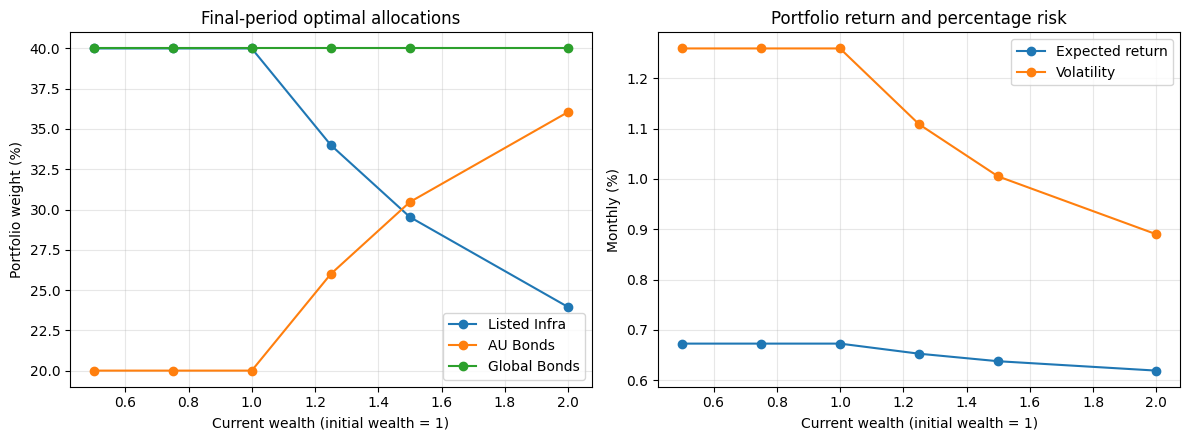

In [ ]:
#(c): allocation and portfolio characteristics versus wealth

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

wealth_values = ext_c_weight_table.index.to_numpy(dtype=float)

# Plot only assets held at one or more wealth levels.
held_assets = ext_c_weight_table.columns[
    ext_c_weight_table.max() > 1e-4
]

for asset in held_assets:
    axes[0].plot(
        wealth_values,
        ext_c_weight_table[asset],
        marker="o",
        label=asset
    )

axes[0].set_xlabel("Current wealth (initial wealth = 1)")
axes[0].set_ylabel("Portfolio weight (%)")
axes[0].set_title("Final-period optimal allocations")
axes[0].legend()
axes[0].grid(alpha=0.3)

for column, label in [
    ("Monthly expected return (%)", "Expected return"),
    ("Monthly volatility (%)", "Volatility")
]:
    axes[1].plot(
        wealth_values,
        ext_c_summary[column],
        marker="o",
        label=label
    )

axes[1].set_xlabel("Current wealth (initial wealth = 1)")
axes[1].set_ylabel("Monthly (%)")
axes[1].set_title("Portfolio return and percentage risk")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Findings**

The allocations are identical at the sampled wealth levels 0.50, 0.75 and 1.00: 40% infrastructure, 20% Australian bonds and 40% global bonds. Infrastructure and global bonds are at their caps, illustrating how portfolio constraints can limit the response to changes in wealth.

At higher wealth levels, infrastructure is progressively replaced by Australian bonds, while global bonds remain at 40%. Between wealth 1.00 and 2.00, infrastructure falls to 23.95%, monthly expected return declines from 0.673% to 0.619%, and monthly volatility declines from 1.259% to 0.890%. This is consistent with the increasing effective risk aversion derived above. The sampled points do not identify the exact wealth threshold at which the allocation begins to change.

Lower percentage volatility does not imply lower monetary risk: terminal wealth standard deviation increases from approximately 0.00630 at wealth 0.50 to 0.01780 at wealth 2.00. These results describe the final-period policy under fixed historical estimates and constraints; they do not establish the optimal policy at earlier dates or demonstrate out-of-sample performance.

### (d) Numerical dynamic programming

We now solve the multiperiod problem numerically for a short horizon of $N=3$ monthly investment periods. The return model, parameter estimates, risk-aversion parameter and portfolio constraints are the same as in part (c).

Because wealth is continuous, we discretise it on a finite grid

$$
w_1, \ldots, w_J.
$$

At each date $k$ and wealth grid point $w_j$, the Bellman problem is

$$
V_k(w_j) = \max_{x \in \mathcal{X}} \; E\left[ V_{k+1}\left( w_j \left(1 + x^\top R_{k+1}\right) \right) \right].
$$

The next-period wealth generated by the Monte Carlo simulation will generally not lie exactly on the wealth grid. We therefore interpolate the continuation value between neighbouring grid points.

Direct interpolation of expected exponential utility can be numerically awkward because the value function is negative and can become very close to zero. We therefore store the certainty-equivalent representation

$$
CE_k(w) = -\frac{1}{\gamma} \log\left[ -V_k(w) \right].
$$

Since

$$
V_N(w) = -e^{-\gamma w},
$$

the terminal condition becomes simply

$$
CE_N(w) = w.
$$

For a candidate portfolio $x$, the Bellman step is equivalently obtained by minimising

$$
\log E\left[ \exp\left\{ -\gamma \, CE_{k+1}\left( w \left(1 + x^\top R_{k+1}\right) \right) \right\} \right].
$$

Monte Carlo simulation is used to approximate this expectation. Common random draws are used across candidate portfolios at a given investment date to reduce numerical noise in the optimisation.

We use a baseline wealth grid on $[0.5, 1.5]$, $51$ grid points and $20{,}000$ Monte Carlo return draws per investment date. The optimisation at each state is subject to

$$
\mathbf{1}^\top x = 1, \qquad 0 \le x_i \le 0.4.
$$

Accuracy is assessed by comparing the numerical policy at the final investment date with the analytical solution derived in part (c). Numerical stability is investigated by varying both the number of wealth grid points and the Monte Carlo sample size.

In [ ]:
# ======================================================================
# Extension B(d): Numerical dynamic portfolio optimisation
# ======================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from scipy.optimize import minimize
from scipy.special import logsumexp
from IPython.display import display


# ======================================================================
# 1. Numerical specification
# ======================================================================

EXT_GAMMA = 10.0          # risk-aversion parameter, same as part (c)

EXT_D_N = 3               # number of monthly investment periods

EXT_D_W_MIN = 0.50
EXT_D_W_MAX = 1.50
EXT_D_W_POINTS = 51       # wealth grid points

EXT_D_MC_PATHS = 20000     # Monte Carlo paths per stage

EXT_D_SEED = 3888
EXT_D_W0 = 1.0            # initial wealth

print("Extension B(d) numerical specification")
print(f"Investment periods:       {EXT_D_N}")
print(
    f"Wealth grid:              "
    f"[{EXT_D_W_MIN}, {EXT_D_W_MAX}] "
    f"with {EXT_D_W_POINTS} points"
)
print(f"Monte Carlo paths/stage:  {EXT_D_MC_PATHS}")
print(f"Risk aversion gamma:      {EXT_GAMMA}")
print(f"Initial wealth:           {EXT_D_W0}")

In [ ]:
# ======================================================================
# 2. Helper functions
# ======================================================================

def interp_extrap(x, grid, values):
    """
    Linear interpolation of a one-dimensional value function.
    Linear extrapolation is used if simulated wealth falls outside
    the wealth grid.
    """
    x = np.asarray(x, dtype=float)

    y = np.interp(x, grid, values)

    # Left extrapolation
    left = x < grid[0]

    if np.any(left):
        slope_left = (
            (values[1] - values[0])
            / (grid[1] - grid[0])
        )

        y[left] = (
            values[0]
            + slope_left * (x[left] - grid[0])
        )

    # Right extrapolation
    right = x > grid[-1]

    if np.any(right):
        slope_right = (
            (values[-1] - values[-2])
            / (grid[-1] - grid[-2])
        )

        y[right] = (
            values[-1]
            + slope_right * (x[right] - grid[-1])
        )

    return y


def log_mean_exp(z):
    """
    Numerically stable log(mean(exp(z))).
    """
    z = np.asarray(z, dtype=float)

    return (
        logsumexp(z)
        - np.log(len(z))
    )


def analytical_final_policy(wealth):
    """
    Analytical final-period solution from Extension B(c).

    At wealth w, effective risk aversion is gamma*w.
    """
    w, info = solve_portfolio(
        ext_mu_monthly,
        ext_cov_monthly,
        gamma=EXT_GAMMA * wealth,
        return_info=True,
        label=f"Analytical final-period wealth={wealth:.4f}"
    )

    return w

In [ ]:
# ======================================================================
# 3. Dynamic-programming solver
# ======================================================================

# ============================================================
# Dynamic Programming Solver
# ============================================================

def solve_dynamic_dp(
    wealth_points=51,
    mc_paths=5000,
    seed=3888,
    wealth_min=0.50,
    wealth_max=1.50,
    N=3,
    verbose=False
):
    """
    Numerical dynamic programming using:
      - wealth discretisation
      - Monte Carlo integration
      - backward induction
      - linear interpolation

    Returns
    -------
    wealth_grid : ndarray
    CE           : ndarray, shape (N+1, wealth_points)
    policy       : ndarray, shape (N, wealth_points, n_assets)
    """

    # --------------------------------------------------------
    # Wealth grid
    # --------------------------------------------------------
    wealth_grid = np.linspace(
        wealth_min,
        wealth_max,
        wealth_points
    )

    n_assets = len(assets)

    # --------------------------------------------------------
    # Monte Carlo returns
    #
    # Each stage has its own fixed random stream.
    # This makes convergence comparisons cleaner.
    # --------------------------------------------------------
    stage_draws = []

    for k in range(N):

        rng_k = np.random.default_rng(seed + k)

        R_k = rng_k.multivariate_normal(
            mean=ext_mu_monthly,
            cov=ext_cov_monthly,
            size=mc_paths
        )

        stage_draws.append(R_k)

    # --------------------------------------------------------
    # Certainty-equivalent value function
    #
    # CE_N(w) = w
    # --------------------------------------------------------
    CE = np.zeros(
        (N + 1, wealth_points)
    )

    CE[N, :] = wealth_grid

    # --------------------------------------------------------
    # Optimal policy
    # --------------------------------------------------------
    policy = np.zeros(
        (
            N,
            wealth_points,
            n_assets
        )
    )

    # Portfolio constraints
    bounds = [
        (float(LB[i]), float(UB[i]))
        for i in range(n_assets)
    ]

    constraints = {
        "type": "eq",
        "fun": lambda x: np.sum(x) - 1.0
    }

    # ========================================================
    # Backward induction
    # ========================================================
    for k in range(N - 1, -1, -1):

        if verbose:
            print(f"Solving stage k={k}")

        R_draws = stage_draws[k]

        CE_next_grid = CE[k + 1]

        previous_solution = None

        for j, wealth in enumerate(wealth_grid):

            # ------------------------------------------------
            # Initial guess
            # ------------------------------------------------
            if previous_solution is None:

                x0 = analytical_final_policy(
                    wealth
                )

            else:

                # Warm start using solution at nearby wealth
                x0 = previous_solution.copy()

            # ------------------------------------------------
            # Bellman objective
            # ------------------------------------------------
            def objective(x):

                # Simulated portfolio returns
                rp = R_draws @ x

                # Next-period wealth
                W_next = (
                    wealth
                    * (1.0 + rp)
                )

                # Continuation certainty equivalent
                CE_next = interp_extrap(
                    W_next,
                    wealth_grid,
                    CE_next_grid
                )

                # Stable calculation of:
                #
                # log E[
                #   exp(-gamma * CE_next)
                # ]
                z = (
                    -EXT_GAMMA
                    * CE_next
                )

                return (
                    logsumexp(z)
                    - np.log(mc_paths)
                )

            # ------------------------------------------------
            # Optimisation
            # ------------------------------------------------
            result = minimize(
                objective,
                x0=x0,
                method="SLSQP",
                bounds=bounds,
                constraints=constraints,
                options={
                    "ftol": 1e-10,
                    "maxiter": 300,
                    "disp": False
                }
            )

            if not result.success:
                raise RuntimeError(
                    f"Optimisation failed at "
                    f"k={k}, wealth={wealth:.4f}: "
                    f"{result.message}"
                )

            x_star = result.x

            # ------------------------------------------------
            # Feasibility checks
            # ------------------------------------------------
            if not np.isclose(
                x_star.sum(),
                1.0,
                atol=1e-6
            ):
                raise ValueError(
                    f"Weights do not sum to 1 "
                    f"at k={k}, wealth={wealth:.4f}"
                )

            if np.any(
                x_star < LB - 1e-6
            ):
                raise ValueError(
                    "Lower-bound violation."
                )

            if np.any(
                x_star > UB + 1e-6
            ):
                raise ValueError(
                    "Upper-bound violation."
                )

            # ------------------------------------------------
            # Store solution
            # ------------------------------------------------
            policy[k, j, :] = x_star

            CE[k, j] = (
                -result.fun
                / EXT_GAMMA
            )

            previous_solution = x_star

    if verbose:
        print("Dynamic programming completed.")

    return wealth_grid, CE, policy

In [ ]:
# ======================================================================
# 4. Baseline dynamic-programming solution
# ======================================================================

start_time = time.perf_counter()

(
    ext_d_grid,
    ext_d_CE,
    ext_d_policy
) = solve_dynamic_dp(
    wealth_points=EXT_D_W_POINTS,
    mc_paths=EXT_D_MC_PATHS,
    seed=EXT_D_SEED,
    wealth_min=EXT_D_W_MIN,
    wealth_max=EXT_D_W_MAX,
    N=EXT_D_N
)

ext_d_runtime = (
    time.perf_counter()
    - start_time
)

print(
    f"\nTotal DP runtime: "
    f"{ext_d_runtime:.2f} seconds"
)

In [ ]:
# ======================================================================
# 5. Initial dynamic portfolio at W0 = 1
# ======================================================================

w0_idx = np.argmin(
    np.abs(
        ext_d_grid
        - EXT_D_W0
    )
)

w0_grid = ext_d_grid[w0_idx]

x0_dynamic = (
    ext_d_policy[
        0,
        w0_idx,
        :
    ]
)

CE0_dynamic = (
    ext_d_CE[
        0,
        w0_idx
    ]
)

initial_return = float(
    x0_dynamic
    @ ext_mu_monthly
)

initial_vol = float(
    np.sqrt(
        x0_dynamic
        @ ext_cov_monthly
        @ x0_dynamic
    )
)

ext_d_initial_table = pd.DataFrame({
    "Asset": asset_labels,
    "Dynamic weight (%)":
        100 * x0_dynamic
})

print(
    f"Wealth grid point used: "
    f"{w0_grid:.4f}"
)

print(
    f"Initial certainty equivalent: "
    f"{CE0_dynamic:.6f}"
)

print(
    f"Initial expected monthly return: "
    f"{100 * initial_return:.4f}%"
)

print(
    f"Initial monthly volatility: "
    f"{100 * initial_vol:.4f}%"
)

display(
    ext_d_initial_table.round(3)
)

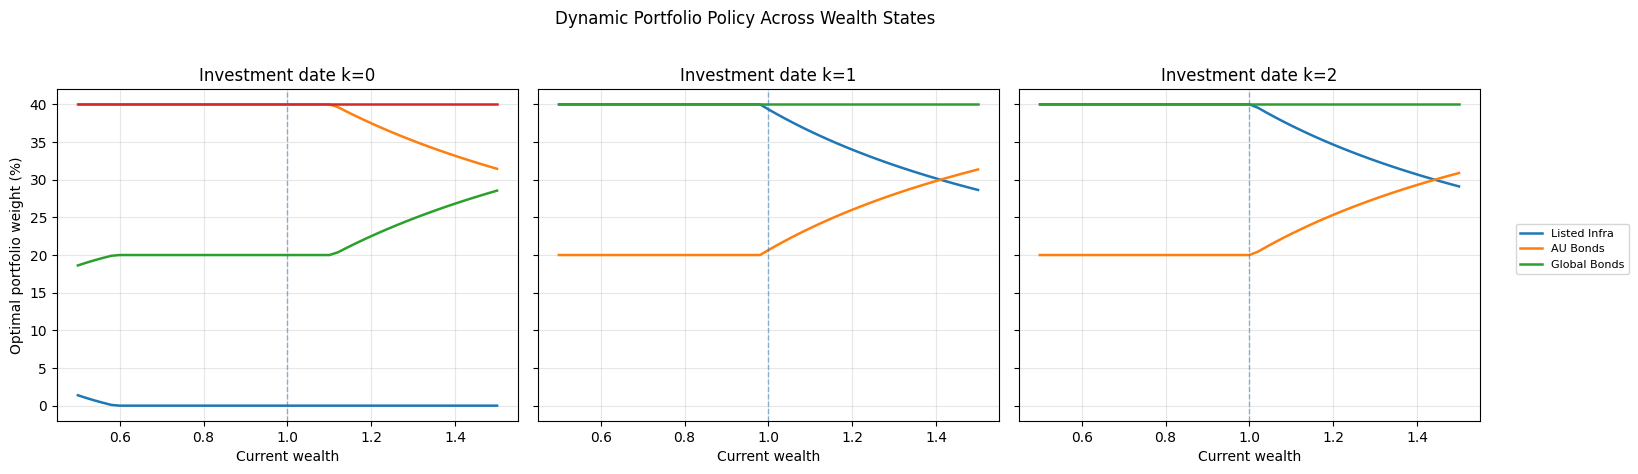

In [ ]:
# ======================================================================
# 6. Dynamic portfolio policy across wealth states
# ======================================================================

fig, axes = plt.subplots(
    1,
    EXT_D_N,
    figsize=(15, 4.6),
    sharey=True
)

if EXT_D_N == 1:
    axes = [axes]

for k, ax in enumerate(axes):

    for j, asset in enumerate(
        assets
    ):

        weights = (
            100
            * ext_d_policy[
                k,
                :,
                j
            ]
        )

        # Only plot assets that receive
        # a material allocation somewhere
        if weights.max() > 0.01:

            ax.plot(
                ext_d_grid,
                weights,
                linewidth=1.8,
                label=LABEL[asset]
            )

    ax.axvline(
        1.0,
        linewidth=1,
        linestyle="--",
        alpha=0.5
    )

    ax.set_xlabel(
        "Current wealth"
    )

    ax.set_title(
        f"Investment date k={k}"
    )

    ax.grid(alpha=0.3)

axes[0].set_ylabel(
    "Optimal portfolio weight (%)"
)

handles, labels = (
    axes[-1]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    fontsize=8
)

fig.suptitle(
    "Dynamic Portfolio Policy Across Wealth States",
    y=1.02
)

plt.tight_layout()

plt.show()

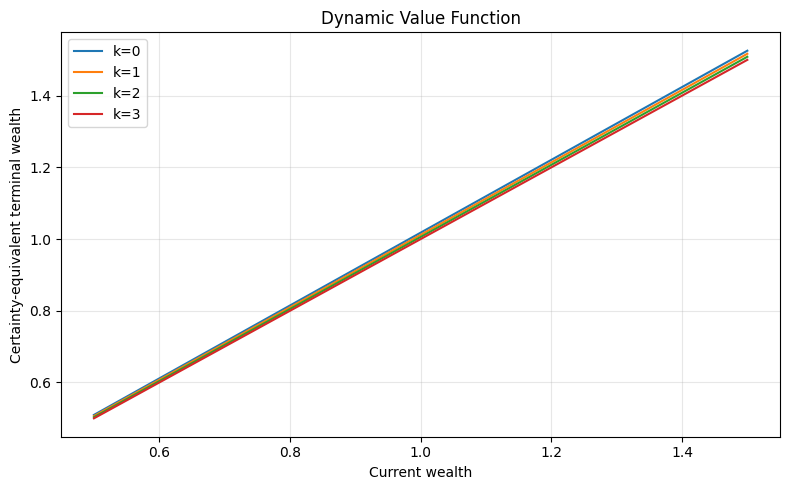

In [ ]:
# ======================================================================
# 7. Certainty-equivalent value functions
# ======================================================================

plt.figure(figsize=(8, 5))

for k in range(
    EXT_D_N + 1
):

    plt.plot(
        ext_d_grid,
        ext_d_CE[k],
        label=f"k={k}"
    )

plt.xlabel(
    "Current wealth"
)

plt.ylabel(
    "Certainty-equivalent terminal wealth"
)

plt.title(
    "Dynamic Value Function"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
# ======================================================================
# 8. Accuracy check against analytical final-period solution
# ======================================================================

validation_wealths = [
    0.75,
    1.00,
    1.25
]

validation_rows = []

validation_weight_tables = {}

for wealth in validation_wealths:

    idx = np.argmin(
        np.abs(
            ext_d_grid
            - wealth
        )
    )

    actual_grid_wealth = (
        ext_d_grid[idx]
    )

    # Numerical DP policy
    numerical_w = (
        ext_d_policy[
            EXT_D_N - 1,
            idx,
            :
        ]
    )

    # Analytical final-period policy
    analytical_w = (
        analytical_final_policy(
            actual_grid_wealth
        )
    )

    diff = (
        numerical_w
        - analytical_w
    )

    half_l1 = (
        0.5
        * np.abs(diff).sum()
    )

    max_diff = (
        np.abs(diff).max()
    )

    validation_rows.append({
        "Wealth":
            actual_grid_wealth,

        "Half-L1 allocation error (%)":
            100 * half_l1,

        "Maximum weight error (pp)":
            100 * max_diff
    })

    validation_weight_tables[
        actual_grid_wealth
    ] = pd.DataFrame({
        "Analytical (%)":
            100 * analytical_w,

        "Numerical DP (%)":
            100 * numerical_w,

        "Difference (pp)":
            100 * diff
    }, index=asset_labels)


ext_d_validation = (
    pd.DataFrame(
        validation_rows
    )
    .set_index("Wealth")
)

print(
    "Final-period numerical validation:"
)

display(
    ext_d_validation.round(4)
)

In [ ]:
print(
    "Detailed validation at wealth = 1:"
)

display(
    validation_weight_tables[
        1.0
    ].round(3)
)

**Convergence analysis**

To separate the effects of wealth discretisation and Monte Carlo sampling, we run two experiments. First, we vary the number of wealth-grid points (31, 51 and 71) with the baseline 20,000 Monte Carlo scenarios. Second, we vary the number of scenarios (5,000, 10,000, 20,000 and 40,000) on the baseline 51-point grid. For each configuration we record the initial certainty equivalent, the initial weights and the run time, and compare them with the highest-resolution configuration in each experiment. These differences are convergence diagnostics rather than exact errors, since the true multiperiod solution is unknown.

In [ ]:
# ============================================================
# Additional Convergence Analysis
# Separating wealth-grid and Monte Carlo errors
# ============================================================

import time

convergence_results = []

# Experiment A: vary grid resolution, fixing MC scenarios
# Experiment B: vary MC scenarios, fixing grid resolution

configs = [
    ("Grid", 31, 20000),
    ("Grid", 51, 20000),
    ("Grid", 71, 20000),

    ("MC", 51, 5000),
    ("MC", 51, 10000),
    ("MC", 51, 20000),
    ("MC", 51, 40000)
]

for experiment, G, M in configs:

    start = time.perf_counter()

    grid, CE, policy = solve_dynamic_dp(
        wealth_points=G,
        mc_paths=M,
        seed=EXT_D_SEED,
        wealth_min=EXT_D_W_MIN,
        wealth_max=EXT_D_W_MAX,
        N=EXT_D_N
    )

    runtime = time.perf_counter() - start

    # Initial certainty equivalent at W0 = 1
    CE0 = np.interp(
        1.0,
        grid,
        CE[0]
    )

    # Initial optimal portfolio
    x0 = np.array([
        np.interp(
            1.0,
            grid,
            policy[0, :, i]
        )
        for i in range(len(assets))
    ])

    convergence_results.append({
        "Experiment": experiment,
        "Grid points": G,
        "MC paths": M,
        "Initial CE": CE0,
        "Initial weights": x0,
        "Runtime (s)": runtime
    })

convergence_df = pd.DataFrame(convergence_results)

# Compare against the highest-resolution setting
# within each experiment.

for experiment in ["Grid", "MC"]:

    mask = convergence_df["Experiment"] == experiment

    subset = convergence_df.loc[mask]

    ref_CE = subset.iloc[-1]["Initial CE"]
    ref_x = subset.iloc[-1]["Initial weights"]

    convergence_df.loc[
        mask, "CE difference"
    ] = abs(subset["Initial CE"] - ref_CE)

    convergence_df.loc[
        mask, "Weight L2 difference"
    ] = [
        np.linalg.norm(x - ref_x)
        for x in subset["Initial weights"]
    ]

display(
    convergence_df.drop(
        columns=["Initial weights"]
    ).round(8)
)

In [ ]:
# ======================================================================
# 11. Forward simulation to check wealth-grid coverage
# ======================================================================

def interpolate_policy(
    wealth,
    grid,
    policy_at_k
):
    """
    Interpolate portfolio weights across wealth states.

    Outside the wealth grid, the nearest boundary
    policy is used.
    """

    wealth = np.asarray(
        wealth,
        dtype=float
    )

    n_paths = len(wealth)

    n_assets = (
        policy_at_k.shape[1]
    )

    out = np.zeros(
        (
            n_paths,
            n_assets
        )
    )

    for j in range(
        n_assets
    ):

        out[:, j] = np.interp(
            wealth,
            grid,
            policy_at_k[:, j]
        )

    return out

In [ ]:
# Forward simulation

rng = np.random.default_rng(
    2026
)

N_FORWARD = 20_000

wealth = np.ones(
    N_FORWARD
)

coverage_rows = []

for k in range(
    EXT_D_N
):

    weights = interpolate_policy(
        wealth,
        ext_d_grid,
        ext_d_policy[k]
    )

    # Check interpolated weights remain feasible
    if not np.allclose(
        weights.sum(axis=1),
        1.0,
        atol=1e-6
    ):
        raise ValueError(
            "Interpolated policy is not fully invested."
        )

    R = rng.multivariate_normal(
        mean=ext_mu_monthly,
        cov=ext_cov_monthly,
        size=N_FORWARD
    )

    portfolio_returns = (
        np.sum(
            weights * R,
            axis=1
        )
    )

    wealth_next = (
        wealth
        * (
            1.0
            + portfolio_returns
        )
    )

    outside_fraction = np.mean(
        (
            wealth_next
            < EXT_D_W_MIN
        )
        |
        (
            wealth_next
            > EXT_D_W_MAX
        )
    )

    coverage_rows.append({
        "After investment period":
            k + 1,

        "Mean wealth":
            wealth_next.mean(),

        "SD wealth":
            wealth_next.std(
                ddof=1
            ),

        "Minimum wealth":
            wealth_next.min(),

        "Maximum wealth":
            wealth_next.max(),

        "Outside grid (%)":
            100 * outside_fraction
    })

    wealth = wealth_next


ext_d_coverage = pd.DataFrame(
    coverage_rows
)

print(
    "Wealth-grid coverage:"
)

display(
    ext_d_coverage.round(4)
)

### Independent Certainty Equivalent Validation

To assess the consistency of the complete three-period dynamic strategy, we evaluate the computed wealth-dependent portfolio policy using 20,000 independent simulated return paths.

The certainty equivalent of terminal wealth is estimated as

$$
\widehat{J}_0^{\mathrm{eval}}
=
-\frac{1}{\gamma}
\log\left(
\frac{1}{P}
\sum_{j=1}^{P}
e^{-\gamma W_N^{(j)}}
\right),
$$

where $P=20{,}000$ is the number of independent simulation paths and $W_N^{(j)}$ denotes the terminal wealth of path $j$.

We compare this estimate with the initial certainty equivalent obtained from backward induction:

$$
\mathrm{CE\ Difference}
=
\left|
\widehat{J}_0^{\mathrm{eval}}
-
\widehat{J}_0^{\mathrm{DP}}
\right|.
$$

A small difference provides evidence of numerical consistency between backward optimisation and independent forward policy evaluation. However, this comparison does not establish global optimality, and the observed difference may also reflect Monte Carlo sampling error.

In [ ]:
# ============================================================
# Independent Certainty Equivalent Validation
# ============================================================

from scipy.special import logsumexp
EXT_D_GAMMA = 10
# Final wealth from the independent forward simulation
terminal_wealth = np.asarray(wealth, dtype=float)

# Certainty equivalent estimated from independent paths
independent_CE = -(
    logsumexp(-EXT_D_GAMMA * terminal_wealth)
    - np.log(len(terminal_wealth))
) / EXT_D_GAMMA

# Monte Carlo standard error of the independent CE estimate
u = np.exp(-EXT_D_GAMMA * terminal_wealth)
independent_CE_se = u.std(ddof=1) / np.sqrt(len(u)) / (EXT_D_GAMMA * u.mean())

# Initial certainty equivalent from backward induction
DP_CE = float(
    np.interp(
        1.0,
        ext_d_grid,
        ext_d_CE[0]
    )
)

validation_results = pd.DataFrame({
    "Metric": [
        "Backward induction CE",
        "Independent simulation CE",
        "MC standard error of independent CE",
        "Absolute CE difference",
        "Relative CE difference (%)"
    ],
    "Value": [
        DP_CE,
        independent_CE,
        independent_CE_se,
        abs(DP_CE - independent_CE),
        100 * abs(DP_CE - independent_CE) / abs(DP_CE)
    ]
})

display(validation_results.round(8))

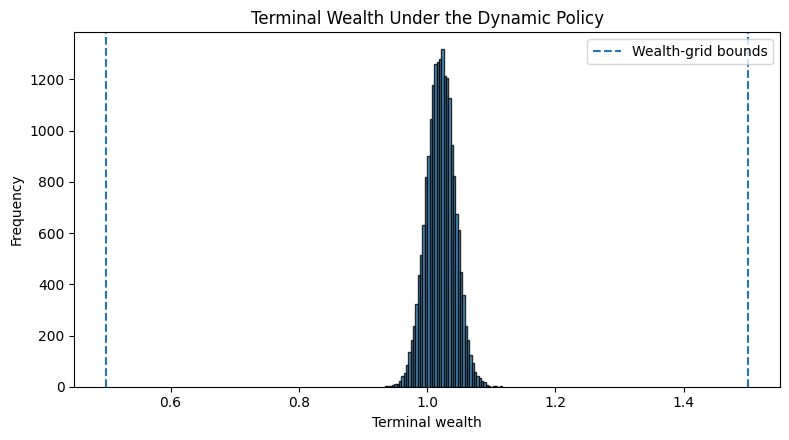

In [ ]:
# ======================================================================
# 12. Simulated terminal wealth distribution
# ======================================================================

plt.figure(
    figsize=(8, 4.5)
)

plt.hist(
    wealth,
    bins=50,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    EXT_D_W_MIN,
    linestyle="--",
    label="Wealth-grid bounds"
)

plt.axvline(
    EXT_D_W_MAX,
    linestyle="--"
)

plt.xlabel(
    "Terminal wealth"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Terminal Wealth Under the Dynamic Policy"
)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
# ======================================================================
# 13. Compact Part (d) result summary
# ======================================================================

print("=" * 65)
print("EXTENSION B(d): SUMMARY")
print("=" * 65)

print(
    f"\nBaseline DP:"
    f"\n  periods       = {EXT_D_N}"
    f"\n  wealth grid   = {EXT_D_W_POINTS}"
    f"\n  MC paths      = {EXT_D_MC_PATHS}"
    f"\n  runtime       = {ext_d_runtime:.2f} s"
)

print(
    f"\nInitial state W0={EXT_D_W0:.2f}:"
    f"\n  certainty equivalent "
    f"= {CE0_dynamic:.6f}"
    f"\n  monthly expected return "
    f"= {100 * initial_return:.4f}%"
    f"\n  monthly volatility "
    f"= {100 * initial_vol:.4f}%"
)

print(
    "\nInitial dynamic weights:"
)

for asset, weight in zip(
    asset_labels,
    x0_dynamic
):

    if weight > 1e-4:

        print(
            f"  {asset:22s}: "
            f"{100 * weight:6.2f}%"
        )

print(
    "\nFinal-period validation:"
)

print(
    ext_d_validation.round(4)
)

print(
    "\nNumerical stability:"
)

print(
    convergence_df.drop(
        columns=["Initial weights"]
    ).round(6)
)
print(
    "\nWealth-grid coverage:"
)

print(
    ext_d_coverage.round(4)
)

In [ ]:
idx = np.argmin(np.abs(ext_d_grid - 1.0))

check_weights = pd.DataFrame(
    {
        f"k={k}": 100 * ext_d_policy[k, idx, :]
        for k in range(EXT_D_N)
    },
    index=asset_labels
)

display(check_weights.round(2))

**Findings**

The numerical dynamic-programming solution is accurate and stable for the short three-period horizon considered. Using a 51-point wealth grid on \([0.5,1.5]\) and 20,000 Monte Carlo scenarios per period, the initial certainty equivalent is 1.017964. At \(W_0=1\), the optimal allocation is 40% Listed Infrastructure, 20% Australian Bonds and 40% Global Bonds, with an expected monthly return of 0.673% and volatility of 1.259%. The allocation is also very similar across the three decision dates: at \(W=1\), only a small shift between Listed Infrastructure and Australian Bonds occurs at \(k=1\), while Global Bonds remains at its 40% upper bound.

Numerical validation provides strong evidence that the approximation is reliable. At the final investment date, the numerical policy coincides with the analytical solution at wealth levels 0.74 and 1.00, and the maximum allocation error at wealth 1.24 is only 0.45 percentage points. Wealth-grid refinement has essentially no effect: with 31, 51 and 71 grid points the initial certainty equivalent changes by less than \(2\times10^{-7}\) and the initial weights are identical, so the discretisation error is negligible. Monte Carlo sampling matters more. With 5,000 scenarios the certainty equivalent differs from the 40,000-scenario value by \(2.6\times10^{-4}\), and about 1.8 percentage points of the infrastructure weight moves to Australian bonds. From 10,000 scenarios onwards the initial weights are identical and the certainty equivalent changes by less than \(4\times10^{-5}\), so the baseline of 20,000 scenarios lies well inside the converged range. The sensitivity of the weights at small sample sizes is consistent with a relatively flat objective near the optimum and binding portfolio constraints.

Independent forward simulation gives a certainty equivalent of 1.018082, compared with 1.017964 from backward induction. The difference of 0.000118 (0.012%) is smaller than the Monte Carlo standard error of the independent estimate, 0.000158, so the two agree within simulation error. Moreover, none of the 20,000 simulated wealth paths leaves the chosen wealth grid, confirming that the state-space range is adequate. Overall, the method appears numerically robust. For this calibration, however, the gains from wealth- and horizon-dependent reallocation are limited near the initial wealth level, as the dynamic policy remains close to the same constrained allocation across investment dates.

### (e) Comparison with fixed and tactical allocation

We use the same market data and numerical settings as parts (c)–(d): a 120-month estimation window, monthly returns, $\gamma=10$, $W_0=1$ and three investment periods. The December 2015 calibration is retained, and the comparison is repeated at the other three Q5 starting dates. Each experiment uses only the next three months of returns, so all strategies are evaluated over the same horizon.

The fixed strategy is Q5's balanced SAA, maintained by monthly rebalancing. TAA uses the corresponding monthly allocations from Q6. The dynamic strategy uses the policy from backward induction, with parameters estimated at the starting date and held fixed for the three months. Its weights depend on current wealth and the remaining horizon.

The strategies have different constraints: SAA requires 70% growth, TAA permits 60–80%, and the dynamic strategy in part (d) has no growth restriction. We therefore also solve a dynamic policy with the same 60–80% range as TAA. All portfolios remain fully invested, long-only and subject to the 40% asset cap. The restricted dynamic policy controls for the growth limits, although its parameter-updating rule and objective still differ from TAA's.

We report cumulative return, monthly volatility, maximum drawdown and drift-adjusted turnover. Initial establishment is excluded from turnover and transaction costs are excluded from returns. With only three observations per experiment, realised volatility is descriptive and is not a precise risk estimate.

In [ ]:
# Extension B(e): dynamic solver for different calibration dates
# Same backward-induction method as part (d), with optional growth limits.

def solve_ext_e_dp(mu, covariance, growth_limits=None):
    grid = np.linspace(EXT_D_W_MIN, EXT_D_W_MAX, EXT_D_W_POINTS)
    CE = np.zeros((EXT_D_N + 1, len(grid)))
    CE[-1] = grid
    policy = np.zeros((EXT_D_N, len(grid), len(assets)))

    constraints = [{"type": "eq", "fun": lambda x: x.sum() - 1}]
    if growth_limits is not None:
        lower, upper = growth_limits
        constraints += [
            {"type": "ineq", "fun": lambda x: growth_vector @ x - lower},
            {"type": "ineq", "fun": lambda x: upper - growth_vector @ x}
        ]

    for k in range(EXT_D_N - 1, -1, -1):
        rng = np.random.default_rng(EXT_D_SEED + k)
        draws = rng.multivariate_normal(mu, covariance, size=EXT_D_MC_PATHS)
        previous_solution = None

        for j, wealth in enumerate(grid):
            if previous_solution is not None:
                x0 = previous_solution.copy()
            elif growth_limits is None:
                x0 = solve_portfolio(mu, covariance, gamma=EXT_GAMMA * wealth)
            else:
                x0, _ = solve_tactical(
                    mu, covariance, EXT_GAMMA * wealth, lower, upper
                )

            def objective(x):
                next_wealth = wealth * (1 + draws @ x)
                continuation = interp_extrap(next_wealth, grid, CE[k + 1])
                return log_mean_exp(-EXT_GAMMA * continuation)

            result = minimize(
                objective, x0, method="SLSQP",
                bounds=list(zip(LB, UB)), constraints=constraints,
                options={"ftol": 1e-10, "maxiter": 300}
            )
            if not result.success:
                raise RuntimeError(f"DP failed at k={k}, wealth={wealth}: {result.message}")

            x = result.x
            if (abs(x.sum() - 1) > 1e-6
                or np.any(x < LB - 1e-6) or np.any(x > UB + 1e-6)):
                raise ValueError("Invalid dynamic weights.")
            if growth_limits is not None:
                if not lower - 1e-6 <= growth_vector @ x <= upper + 1e-6:
                    raise ValueError("Dynamic growth exposure is outside its limits.")

            policy[k, j] = x
            CE[k, j] = -result.fun / EXT_GAMMA
            previous_solution = x

    return grid, CE, policy


In [ ]:
# Calibrate and evaluate each strategy over the same three-month period.

ext_e_runs = {}
ext_e_rows = []
ext_e_checks = []

for T0 in T0_list:
    key = str(T0)
    train_dates = pd.period_range(end=T0, periods=EXT_WINDOW, freq="M")
    test_dates = pd.period_range(start=T0 + 1, periods=EXT_D_N, freq="M")
    train = monthly_returns.reindex(index=train_dates, columns=assets)
    test = monthly_returns.reindex(index=test_dates, columns=assets)

    if train.isna().any().any() or test.isna().any().any():
        raise ValueError(f"{key}: incomplete data.")
    assert train.index.max() < test.index.min()

    mu_annual, cov_annual, _, _ = estimate_at_T0(train)
    mu, covariance = mu_annual / 12, cov_annual / 12

    if T0 == EXT_T0:
        np.testing.assert_allclose(mu, ext_mu_monthly, atol=1e-12)
        np.testing.assert_allclose(covariance, ext_cov_monthly, atol=1e-12)
        dynamic = (ext_d_grid, ext_d_CE, ext_d_policy)
    else:
        dynamic = solve_ext_e_dp(mu, covariance)

    dynamic_band = solve_ext_e_dp(mu, covariance, (GROWTH_LOWER, GROWTH_UPPER))
    models = {"Dynamic": dynamic, "Dynamic (60–80%)": dynamic_band}
    paths, allocations = {}, {}
    fixed_weights = np.asarray(q5_weights[key][SAA_NAME])

    for strategy in ["Fixed SAA", "TAA", "Dynamic", "Dynamic (60–80%)"]:
        wealth = 1.0
        wealth_path = [wealth]
        weight_rows, return_rows = [], []
        previous_end = None
        turnover = 0.0
        outside_grid = 0

        for k, month in enumerate(test_dates):
            if strategy == "Fixed SAA":
                weights = fixed_weights.copy()
            elif strategy == "TAA":
                weights = q6_runs[key]["weights"].loc[month].to_numpy()
            else:
                grid, _, policy = models[strategy]
                outside_grid += int(wealth < grid[0] or wealth > grid[-1])
                weights = interpolate_policy(np.array([wealth]), grid, policy[k])[0]

            if (abs(weights.sum() - 1) > 1e-6
                or np.any(weights < LB - 1e-6) or np.any(weights > UB + 1e-6)):
                raise ValueError("Invalid backtest weights.")
            if strategy in ["TAA", "Dynamic (60–80%)"]:
                assert GROWTH_LOWER - 1e-6 <= growth_vector @ weights <= GROWTH_UPPER + 1e-6

            if previous_end is not None:
                turnover += 0.5 * np.abs(weights - previous_end).sum()

            asset_return = test.loc[month].to_numpy()
            portfolio_return = float(weights @ asset_return)
            if portfolio_return <= -1:
                raise ValueError("Non-positive wealth.")
            wealth *= 1 + portfolio_return
            previous_end = weights * (1 + asset_return) / (1 + portfolio_return)
            wealth_path.append(wealth)
            weight_rows.append(weights)
            return_rows.append(portfolio_return)

        # The historical benchmarks must reproduce Q5 and Q6 for these months.
        if strategy == "Fixed SAA":
            np.testing.assert_allclose(return_rows, q5_returns[key].loc[test_dates, SAA_NAME], atol=1e-10)
        elif strategy == "TAA":
            np.testing.assert_allclose(return_rows, q6_runs[key]["monthly"].loc[test_dates, "TAA return"], atol=1e-10)

        wealth_path = np.asarray(wealth_path)
        drawdown = 1 - wealth_path / np.maximum.accumulate(wealth_path)
        paths[strategy] = wealth_path
        allocations[strategy] = pd.DataFrame(weight_rows, index=test_dates, columns=assets)
        ext_e_rows.append({
            "T0": key, "Strategy": strategy,
            "Cumulative return (%)": 100 * (wealth - 1),
            "Monthly volatility (%)": 100 * np.std(return_rows, ddof=1),
            "Maximum drawdown (%)": 100 * drawdown.max(),
            "Total turnover (%)": 100 * turnover,
            "Initial growth (%)": 100 * (weight_rows[0] @ growth_vector)
        })
        ext_e_checks.append({"T0": key, "Strategy": strategy,
                             "Decision states outside grid": outside_grid})

    ext_e_runs[key] = {"wealth": pd.DataFrame(paths, index=pd.period_range(T0, periods=EXT_D_N+1, freq="M")),
                       "weights": allocations, "models": models,
                       "mu": mu, "covariance": covariance}
    print(f"Completed {key}: {test_dates[0]} to {test_dates[-1]}")

ext_e_results = pd.DataFrame(ext_e_rows).set_index(["T0", "Strategy"])
display(ext_e_results.round(3))
print("Benchmark, date and portfolio-constraint checks passed.")
print("Historical decision states outside grid:",
      sum(row["Decision states outside grid"] for row in ext_e_checks))


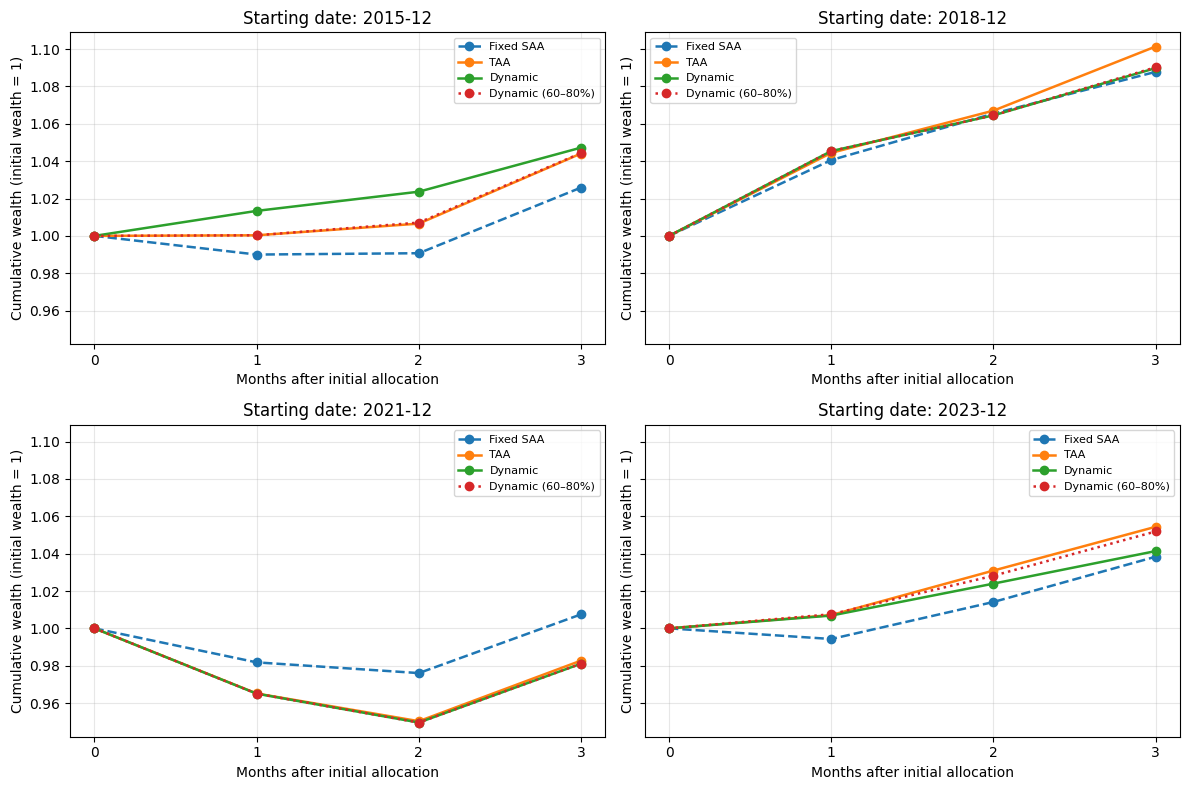

In [ ]:
# Cumulative wealth and initial allocations

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
styles = {"Fixed SAA": ("C0", "--"), "TAA": ("C1", "-"),
          "Dynamic": ("C2", "-"), "Dynamic (60–80%)": ("C3", ":")}

for ax, (key, run) in zip(axes.flat, ext_e_runs.items()):
    for strategy, (color, line_style) in styles.items():
        ax.plot(range(EXT_D_N + 1), run["wealth"][strategy],
                label=strategy, color=color, linestyle=line_style,
                marker="o", linewidth=1.8)
    ax.set_title(f"Starting date: {key}")
    ax.set_xticks(range(EXT_D_N + 1))
    ax.set_xlabel("Months after initial allocation")
    ax.set_ylabel("Cumulative wealth (initial wealth = 1)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

ext_e_initial_weights = pd.DataFrame({
    name: 100 * weights.iloc[0]
    for name, weights in ext_e_runs[str(EXT_T0)]["weights"].items()
}).rename(index=LABEL)
print(f"Initial allocations at {EXT_T0} (%)")
display(ext_e_initial_weights.round(2))


**Comparison under the estimated return model**

Historical performance and expected terminal utility answer different questions. We also evaluate the December 2015 dynamic policies on 50,000 independent normal-return paths, using the same paths for every strategy. The evaluation seed differs from the backward-induction seed.

For each dynamic policy, we include a static mean–variance portfolio with identical constraints and $\gamma=10$, calculated at $W_0=1$ and maintained for all three months. These controls hold the estimates and feasible set constant, allowing us to assess the benefit of wealth- and horizon-dependent allocation together. They are not the rolling TAA strategy, which is evaluated in the historical comparison above.

Expected utility is reported as certainty-equivalent terminal wealth,
$$
\widehat{CE}=-\frac{1}{\gamma}\log\left(\frac1P\sum_{j=1}^P e^{-\gamma W_N^{(j)}}\right).
$$
A higher certainty equivalent is preferable under the assumed utility. We report an approximate paired 95% Monte Carlo interval for each dynamic policy's CE gain over its static control. This interval measures simulation uncertainty conditional on the estimated model, not parameter uncertainty or DP approximation error.

In [ ]:
# Independent simulation using the December 2015 calibration

EXT_E_PATHS = 50_000
EXT_E_SEED = 20261019
baseline = ext_e_runs[str(EXT_T0)]
mu, covariance = baseline["mu"], baseline["covariance"]

static_mv = solve_portfolio(mu, covariance, gamma=EXT_GAMMA)
static_band, _ = solve_tactical(mu, covariance, EXT_GAMMA, GROWTH_LOWER, GROWTH_UPPER)
constant_weights = {
    "Fixed SAA": np.asarray(q5_weights[str(EXT_T0)][SAA_NAME]),
    "Static MV": static_mv,
    "Static MV (60–80%)": static_band
}
strategy_names = list(constant_weights) + list(baseline["models"])
terminal = {name: np.ones(EXT_E_PATHS) for name in strategy_names}
outside = {name: np.zeros(EXT_E_PATHS, dtype=bool) for name in baseline["models"]}
rng = np.random.default_rng(EXT_E_SEED)

for k in range(EXT_D_N):
    draws = rng.multivariate_normal(mu, covariance, size=EXT_E_PATHS)
    for name in strategy_names:
        if name in constant_weights:
            returns = draws @ constant_weights[name]
        else:
            grid, _, policy = baseline["models"][name]
            outside[name] |= (terminal[name] < grid[0]) | (terminal[name] > grid[-1])
            weights = interpolate_policy(terminal[name], grid, policy[k])
            assert np.allclose(weights.sum(axis=1), 1, atol=1e-6)
            assert np.all(weights >= LB - 1e-6) and np.all(weights <= UB + 1e-6)
            if name == "Dynamic (60–80%)":
                growth = weights @ growth_vector
                assert growth.min() >= GROWTH_LOWER - 1e-6 and growth.max() <= GROWTH_UPPER + 1e-6
            returns = np.sum(weights * draws, axis=1)
        terminal[name] *= 1 + returns

ext_e_sim_rows = []
CE_values = {}
for name, final_wealth in terminal.items():
    CE_values[name] = -log_mean_exp(-EXT_GAMMA * final_wealth) / EXT_GAMMA
    ext_e_sim_rows.append({
        "Strategy": name,
        "Mean terminal wealth": final_wealth.mean(),
        "SD terminal wealth": final_wealth.std(ddof=1),
        "Loss probability (%)": 100 * np.mean(final_wealth < 1),
        "Certainty equivalent": CE_values[name]
    })

ext_e_simulation = pd.DataFrame(ext_e_sim_rows).set_index("Strategy")
display(ext_e_simulation.round(6))

paired_rows = []
for dynamic_name, static_name in [("Dynamic", "Static MV"),
                                  ("Dynamic (60–80%)", "Static MV (60–80%)")]:
    # Delta-method influence values for the paired CE difference.
    z_dynamic = -EXT_GAMMA * terminal[dynamic_name]
    z_static = -EXT_GAMMA * terminal[static_name]
    influence = -(np.exp(z_dynamic - log_mean_exp(z_dynamic))
                  - np.exp(z_static - log_mean_exp(z_static))) / EXT_GAMMA
    standard_error = influence.std(ddof=1) / np.sqrt(EXT_E_PATHS)
    gain = CE_values[dynamic_name] - CE_values[static_name]
    paired_rows.append({
        "Comparison": dynamic_name + " minus " + static_name,
        "CE gain (bp of initial wealth)": 10000 * gain,
        "95% MC lower (bp)": 10000 * (gain - 1.96 * standard_error),
        "95% MC upper (bp)": 10000 * (gain + 1.96 * standard_error)
    })

ext_e_ce_gains = pd.DataFrame(paired_rows).set_index("Comparison")
display(ext_e_ce_gains.round(4))
print("Simulation paths with a decision state outside the wealth grid (%)")
for name, flags in outside.items():
    print(f"{name}: {100 * flags.mean():.3f}")


**Findings**

The three-month comparisons do not identify one strategy that performs best in every period. Dynamic allocation returned 4.73% in January–March 2016, compared with 4.41% for TAA and 2.59% for fixed SAA. TAA performed best in January–March 2019 and 2024, returning 10.14% and 5.44%, respectively. In January–March 2022, fixed SAA returned 0.75%, while TAA and dynamic allocation lost 1.73% and 1.89%.

The 2016 result partly reflects different growth restrictions. The dynamic portfolio initially held 40% infrastructure, 20% Australian bonds and 40% global bonds, giving 40% growth exposure. TAA and fixed SAA started with 60% and 70% growth exposure. When the dynamic policy was restricted to the same 60–80% range as TAA, its return fell to 4.43%, close to TAA's 4.41%. Its monthly volatility was also similar to TAA's, at 1.96% against 1.99%. The original dynamic portfolio's lower volatility of 0.67% therefore should not be interpreted solely as a benefit of dynamic optimisation.

The strategies also respond to different information. Fixed SAA restores the same target weights each month. TAA updates return and covariance estimates, whereas the dynamic policies keep their initial estimates and adjust to wealth and the remaining horizon. Higher wealth increases effective relative risk aversion under exponential utility, but binding constraints can limit changes in weights. Where the growth limits are not binding, the two dynamic versions can be almost identical, as in the 2022 experiment. Where the limits restrict the chosen allocations, their results differ more: in early 2024, the dynamic return increased from 4.14% to 5.19% after imposing the growth range.

Independent simulation under the December 2015 model gives certainty equivalents of 1.017895 for dynamic allocation and 1.012235 for fixed SAA. However, the static mean–variance portfolio with the same constraints achieves 1.017896. The dynamic CE gain is approximately −0.010 basis points of initial wealth, with a paired 95% Monte Carlo interval of [−0.038, 0.018]. The restricted dynamic policy also has an interval containing zero. These results provide no clear evidence of an additional utility gain from dynamic reallocation for this calibration. The short horizon, small wealth changes and binding asset caps help explain why dynamic and static mean–variance performance is so similar. The small negative estimated gains are consistent with simulation and numerical approximation error; they do not establish that the exact optimal dynamic policy is inferior.

Dynamic allocation does not necessarily reduce trading. In early 2024, its turnover was 35.42%, compared with 23.50% for TAA and 1.46% for fixed SAA. Transaction costs could therefore change the comparison. Overall, dynamic allocation permits wealth- and horizon-dependent decisions, but these tests do not show a consistent practical advantage. The historical samples are short, and the simulated results depend on fixed normal-return estimates. More substantial wealth changes or a longer horizon could make dynamic decisions more important, but this would require further testing. As in the earlier backtests, observations are assumed available at month-end; publication delays would need to be allowed for in implementation.
